✅ Setup complete
   Product       : SM  tick=0.1
   Abs threshold : 0.1   Comp threshold: 0.3
   Volume filter : >3000    Forward days: 10
   Today         : 2026-09-21
════════════════════════════════════════════════════════════
INSTRUMENTS SELECTED
════════════════════════════════════════════════════════════
  Expired spreads : ['SMH26-SMK26', 'SMK26-SMN26', 'SMN26-SMQ26']
  Front 4 spreads : ['SMV26-SMZ26', 'SMZ26-SMF27', 'SMF27-SMH27', 'SMH27-SMK27']
  Total           : 7 instruments
════════════════════════════════════════════════════════════
════════════════════════════════════════════════════════════
FETCHING & SCORING OHLC DATA
════════════════════════════════════════════════════════════

  ▸ SMH26-SMK26
    [SKIP] not enough data

  ▸ SMK26-SMN26
    rows=92  abs_events=14

  ▸ SMN26-SMQ26
    rows=132  abs_events=45

  ▸ SMV26-SMZ26
    rows=178  abs_events=80

  ▸ SMZ26-SMF27
    rows=178  abs_events=80

  ▸ SMF27-SMH27
    rows=178  abs_events=81

  ▸ SMH27-SMK27
    rows=1

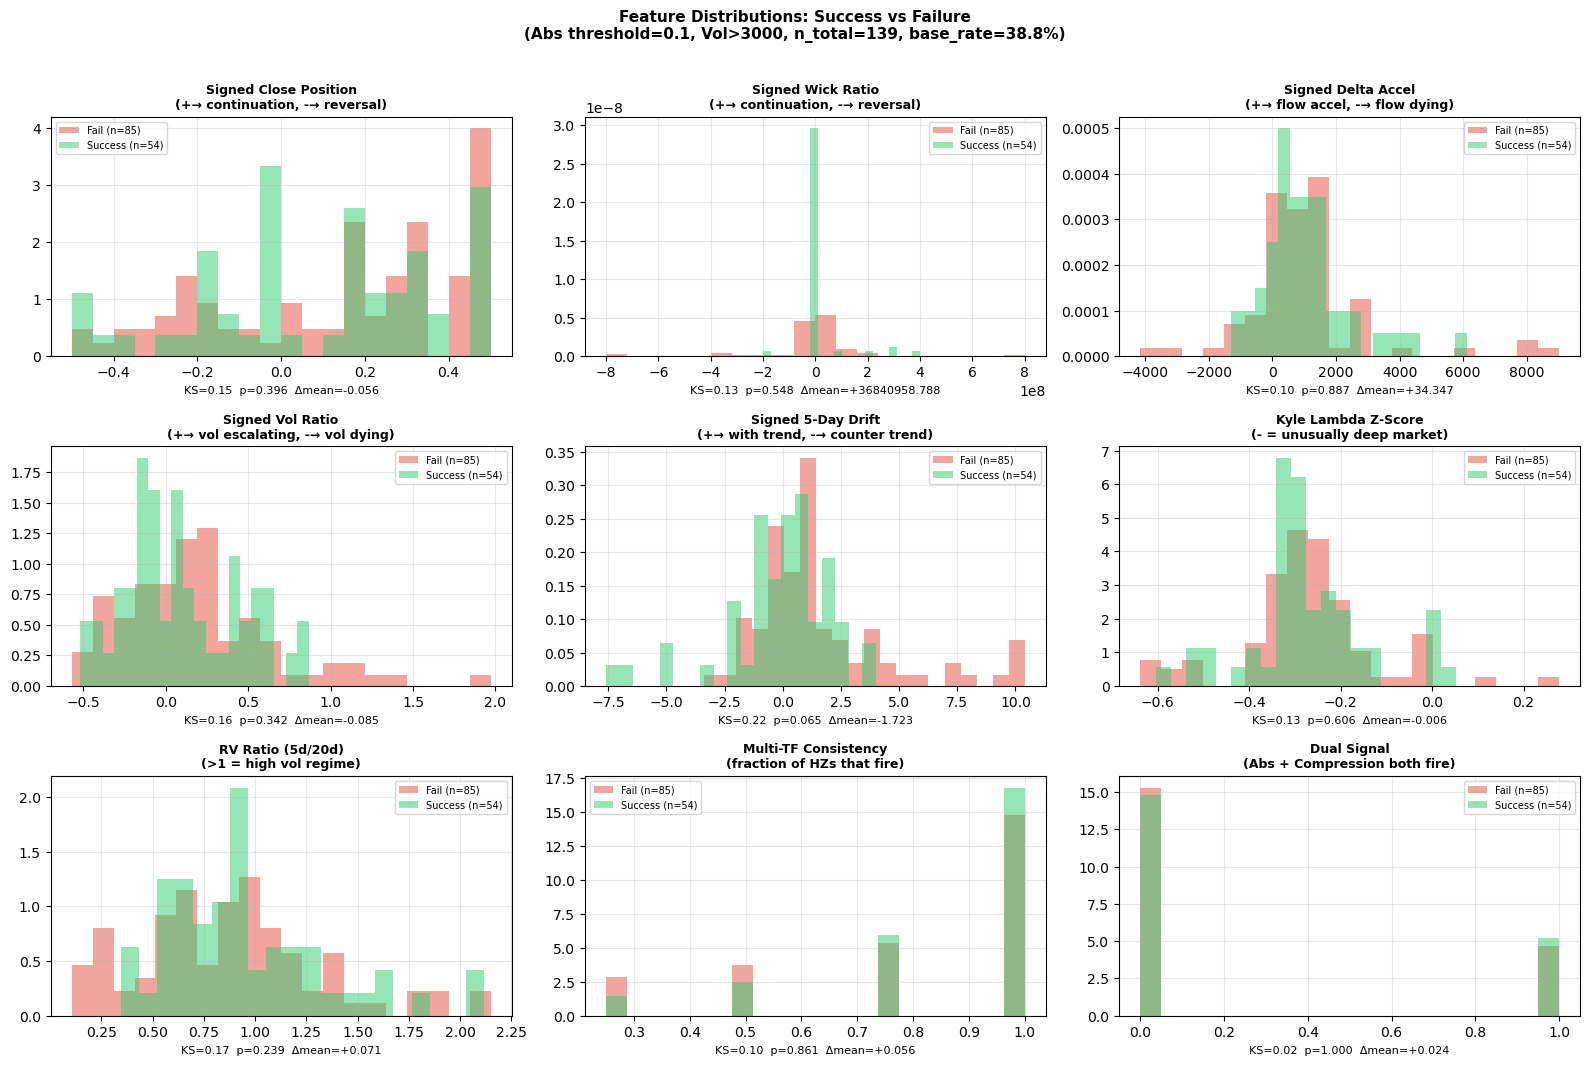


Feature Separation (KS test, sorted by KS stat):
           feature  ks_stat  ks_pval  mean_success     mean_fail     mean_diff
    signed_drift_5 0.221351 0.064848 -1.185185e-01  1.604706e+00 -1.723224e+00
          rv_ratio 0.172985 0.238541  9.506683e-01  8.797679e-01  7.090033e-02
  signed_vol_ratio 0.157298 0.341831  9.575264e-02  1.804805e-01 -8.472788e-02
  signed_close_pos 0.150327 0.396021  9.439826e-02  1.505679e-01 -5.616963e-02
 signed_wick_ratio 0.132680 0.547989  2.037037e+07 -1.647059e+07  3.684096e+07
     lambda_zscore 0.126797 0.606489 -2.744493e-01 -2.687163e-01 -5.733007e-03
    tf_consistency 0.098911 0.861133  8.564815e-01  8.000000e-01  5.648148e-02
signed_delta_accel 0.095425 0.886832  1.076630e+03  1.042282e+03  3.434728e+01
       dual_signal 0.023965 1.000000  2.592593e-01  2.352941e-01  2.396514e-02
════════════════════════════════════════════════════════════
WALK-FORWARD SPLIT
════════════════════════════════════════════════════════════
  Train: 97 events 

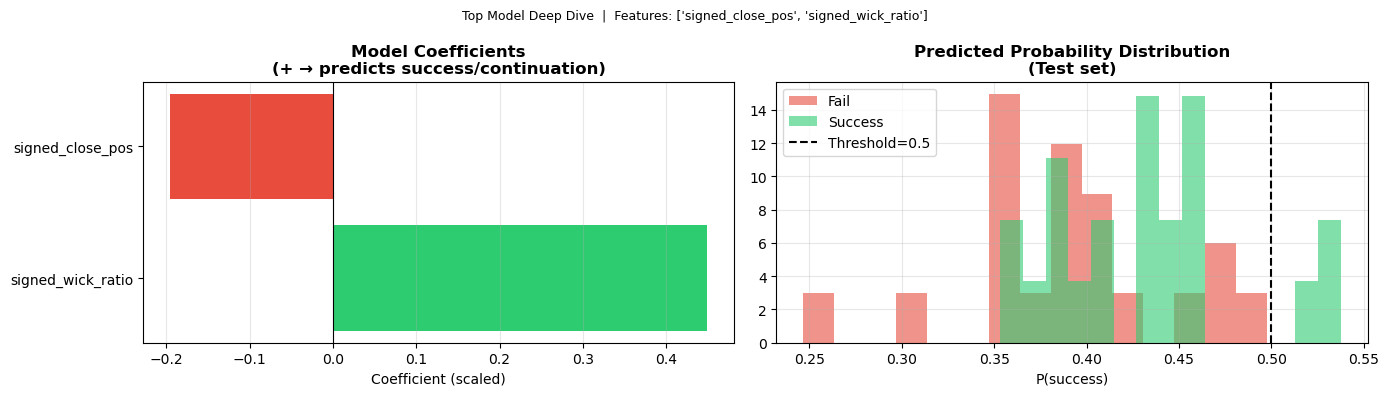


  Coefficients (sorted by |coef|):
          feature  coefficient
signed_wick_ratio     0.449145
 signed_close_pos    -0.195871


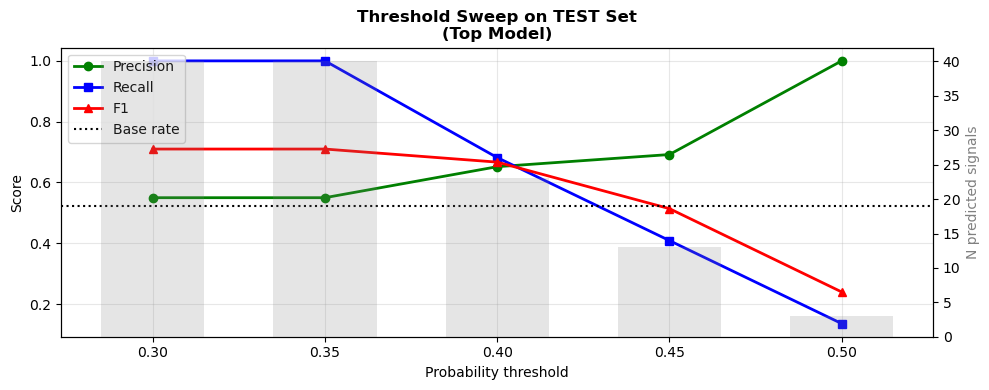


  Threshold Sweep Table (TEST):
 threshold  N_predicted  precision  recall    f1
      0.30           40      0.550   1.000 0.710
      0.35           40      0.550   1.000 0.710
      0.40           23      0.652   0.682 0.667
      0.45           13      0.692   0.409 0.514
      0.50            3      1.000   0.136 0.240
════════════════════════════════════════════════════════════
BUY vs SELL ABSORPTION SPLIT
════════════════════════════════════════════════════════════

  BUY ABSORPTION  n=71  success=25 (35.2%)  fail=46
           feature  mean_success     mean_fail          diff  ks_stat  p_value
    signed_drift_5 -2.080000e-01  1.156500e+00 -1.364500e+00    0.289    0.107
          rv_ratio  9.288000e-01  8.356000e-01  9.320000e-02    0.286    0.110
     lambda_zscore -2.759000e-01 -2.283000e-01 -4.760000e-02    0.285    0.114
 signed_wick_ratio -8.000000e+06 -7.391304e+07  6.591304e+07    0.250    0.216
  signed_close_pos  9.270000e-02  1.036000e-01 -1.090000e-02    0.243    0

In [2]:

# ═══════════════════════════════════════════════════════════════════════════════
# CELL 1 — SETUP & IMPORTS
# ═══════════════════════════════════════════════════════════════════════════════

import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, r"C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents")

import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_score, recall_score, f1_score
from itertools import combinations

from market_analysis.config import (
    PRODUCTS, FRONT_N, OHLC_START_DATE, OHLC_END_DATE, ABSORPTION, COMPRESSION
)
from market_analysis.data.ohlc import getData_OHLC_v2, fetch_ohlc_1d, get_ohlc_for_horizon
from market_analysis.utils.contracts import (
    MONTH_CODES, next_n_contract_months, get_front_instruments, fmt_contract
)
from market_analysis.signals.absorption.calculate import calculate_absorption
from market_analysis.signals.absorption.label import label_absorption
from market_analysis.signals.compression.calculate import calculate_compression

# ── Constants ──────────────────────────────────────────────────────────────────
PRODUCT_CODE      = "SM"
TICK_SIZE         = PRODUCTS[PRODUCT_CODE]["tick_size"]          # 0.1
ABS_THRESHOLD     = 0.1    # absorption_strength filter
COMP_THRESHOLD    = 0.30    # compression_score filter
VOLUME_MIN        = 3000    # ignore bars with total volume below this
HORIZONS          = ["1d", "2d", "3d", "5d"]
TODAY             = datetime.date.today()

# Label params (from your best sweep row)
REQUIRED_MOVE_TICKS = 3     # 5 × tick = 0.5 pts
SL_LOOKBACK         = 10
FORWARD_DAYS        = 10

print("✅ Setup complete")
print(f"   Product       : {PRODUCT_CODE}  tick={TICK_SIZE}")
print(f"   Abs threshold : {ABS_THRESHOLD}   Comp threshold: {COMP_THRESHOLD}")
print(f"   Volume filter : >{VOLUME_MIN}    Forward days: {FORWARD_DAYS}")
print(f"   Today         : {TODAY}")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 2 — INSTRUMENT SELECTION (front 4 + recently expired spreads)
# ═══════════════════════════════════════════════════════════════════════════════

def get_expired_spreads(product_code: str, n_expired: int = 3) -> list[str]:
    """
    Return the last `n_expired` calendar-consecutive spread pairs that expired
    before today. Uses the same traded_months list from config.
    """
    product  = PRODUCTS[product_code]
    traded   = sorted(product["traded_months"])
    prefix   = product["api_prefix"]

    # walk backwards from today to collect recent contract months
    y, m     = TODAY.year, TODAY.month
    collected = []
    while len(collected) < n_expired + 4:   # collect extra buffer
        m -= 1
        if m < 1:
            m = 12; y -= 1
        if m in traded:
            collected.append((y, m))

    collected.reverse()   # chronological order

    pairs = []
    for i in range(len(collected) - 1):
        front = fmt_contract(prefix, *collected[i])
        back  = fmt_contract(prefix, *collected[i + 1])
        pairs.append(f"{front}-{back}")

    # take the most recent n_expired pairs
    return pairs[-n_expired:]


# Front 4 spreads starting from today
front_4 = get_front_instruments(PRODUCT_CODE, "spread",
                                reference_date=TODAY, front_n=4)

# ~3 recently expired spreads for extra data
expired_3 = get_expired_spreads(PRODUCT_CODE, n_expired=3)

ALL_INSTRUMENTS = expired_3 + front_4

print("═" * 60)
print("INSTRUMENTS SELECTED")
print("═" * 60)
print(f"  Expired spreads : {expired_3}")
print(f"  Front 4 spreads : {front_4}")
print(f"  Total           : {len(ALL_INSTRUMENTS)} instruments")
print("═" * 60)


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 3 — FETCH, SCORE (absorption + compression) FOR ALL INSTRUMENTS
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("FETCHING & SCORING OHLC DATA")
print("═" * 60)

# Store per-instrument scored 1D DataFrames (before aggregation)
scored_1d = {}      # {instrument: df_with_absorption_1d}
scored_nd = {}      # {instrument: {horizon: df}}

for instr in ALL_INSTRUMENTS:
    print(f"\n  ▸ {instr}")

    # --- 1D fetch & absorption score ---
    df1d = fetch_ohlc_1d(instr, PRODUCT_CODE, getData_OHLC_v2,
                          start_date=OHLC_START_DATE, end_date=OHLC_END_DATE)
    if df1d is None or len(df1d) < 70:
        print(f"    [SKIP] not enough data")
        continue

    df1d_abs  = calculate_absorption(df1d, window=60,
                                      tick_size=TICK_SIZE, strength_threshold=ABS_THRESHOLD)
    df1d_abs  = label_absorption(df1d_abs, tick=TICK_SIZE,
                                  required_move_ticks=REQUIRED_MOVE_TICKS,
                                  sl_lookback=SL_LOOKBACK,
                                  forward_days=FORWARD_DAYS)
    scored_1d[instr] = df1d_abs

    # --- compression on 1D ---
    df1d_comp, _ = calculate_compression(df1d.copy(),
                                          compression_threshold=COMP_THRESHOLD)

    # merge compression_score into absorption df by Date
    comp_merge = df1d_comp[["Date", "compression_score"]].copy()
    comp_merge["Date"] = pd.to_datetime(comp_merge["Date"]).dt.strftime("%Y-%m-%d")
    df1d_abs["Date"]   = pd.to_datetime(df1d_abs["Date"]).dt.strftime("%Y-%m-%d")
    df1d_abs = df1d_abs.merge(comp_merge.rename(columns={"compression_score": "comp_score_1d"}),
                               on="Date", how="left")
    scored_1d[instr] = df1d_abs

    # --- multi-horizon absorption scores (for consistency feature) ---
    scored_nd[instr] = {}
    for hz in HORIZONS:
        from market_analysis.data.ohlc import _aggregate_trailing
        from market_analysis.config import HORIZON_BARS
        n_bars = HORIZON_BARS[hz]
        dfh    = df1d.copy() if n_bars == 1 else _aggregate_trailing(df1d.copy(), n_bars)
        if dfh is None or len(dfh) < 65:
            continue
        dfh_sc = calculate_absorption(dfh, window=60,
                                       tick_size=TICK_SIZE, strength_threshold=ABS_THRESHOLD)
        scored_nd[instr][hz] = dfh_sc
    print(f"    rows={len(df1d_abs)}  "
          f"abs_events={(df1d_abs['absorption_strength'] > ABS_THRESHOLD).sum()}")

print("\n✅ Scoring complete")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 4 — FEATURE ENGINEERING
# (all past-only, no forward leakage, computed at bar t)
# ═══════════════════════════════════════════════════════════════════════════════

def build_resolution_features(df: pd.DataFrame,
                                scored_nd_for_instr: dict,
                                tick: float = 0.1,
                                epsilon: float = 1e-9) -> pd.DataFrame:
    """
    Add Stage-2 characterization features to a scored+labeled 1D DataFrame.
    All features use only [t-N : t] — strictly past-only.
    """
    d = df.copy().sort_values("Date").reset_index(drop=True)

    # ── 1. Intrabar: close position within bar ──────────────────────────────
    d["close_pos"] = (d["close"] - d["low"]) / (d["high"] - d["low"] + epsilon)
    # Signed for direction:
    #   BUY  absorption → reversal = price drops → close near LOW is BAD for buyers
    #     close_pos LOW (< 0.3) → sellers won intrabar → reversal hint → signed negative
    #   SELL absorption → reversal = price rises → close near HIGH is BAD for sellers
    # Convention: signed_close_pos > 0 → continuation, < 0 → reversal
    d["signed_close_pos"] = np.where(
        d["absorption_direction"] == "BUY",
        d["close_pos"] - 0.5,          # BUY: high → continuation (+), low → reversal (-)
        0.5 - d["close_pos"],          # SELL: low → continuation (+), high → reversal (-)
    )

    # ── 2. Intrabar: wick asymmetry ──────────────────────────────────────────
    d["upper_wick"] = d["high"] - d[["open", "close"]].max(axis=1)
    d["lower_wick"] = d[["open", "close"]].min(axis=1) - d["low"]
    d["wick_ratio"] = d["upper_wick"] / (d["lower_wick"] + epsilon)
    # BUY absorption: large upper wick → price pushed up but rejected → reversal
    # SELL absorption: large lower wick → price tested down but rejected → reversal
    # Sign: negative → reversal hint
    d["signed_wick_ratio"] = np.where(
        d["absorption_direction"] == "BUY",
        -(d["wick_ratio"] - 1.0),       # BUY: wick_ratio >> 1 → reversal → negative
        (d["wick_ratio"] - 1.0),        # SELL: wick_ratio << 1 → reversal → positive issue
    )
    # simpler: just keep raw wick_ratio and let model learn direction via dir dummy

    # ── 3. Delta ratio (how one-sided) ───────────────────────────────────────
    d["delta_ratio"] = d["buyvolume"] / (d["sellvolume"] + epsilon)

    # ── 4. Delta momentum: is aggressive flow accel or dying? ────────────────
    d["delta_accel"] = d["delta"] - d["delta"].shift(1).rolling(3, min_periods=1).mean()
    # Sign to success: BUY absorption — if delta_accel positive → buyers not exhausted → continuation
    # SELL absorption — if delta_accel negative (sell delta growing) → sellers not exhausted → continuation
    d["signed_delta_accel"] = np.where(
        d["absorption_direction"] == "BUY",
        d["delta_accel"],
        -d["delta_accel"],
    )

    # ── 5. Volume deceleration ───────────────────────────────────────────────
    vol_roll5 = d["volume"].shift(1).rolling(5, min_periods=2).mean()
    d["vol_ratio"] = d["volume"] / (vol_roll5 + epsilon)
    # vol_ratio < 1 → volume drying up → exhaustion → reversal (negative for our sign)
    # signed: positive → continuation hint
    d["signed_vol_ratio"] = d["vol_ratio"] - 1.0   # >0 = escalating, <0 = dying

    # ── 6. Price drift into absorption ───────────────────────────────────────
    d["drift_5"] = (d["close"] - d["close"].shift(5)) / (5 * tick + epsilon)
    # BUY absorption after falling prices (drift_5 < 0) → counter-trend buyers → reversal likely
    # SELL absorption after rising prices (drift_5 > 0) → counter-trend sellers → reversal likely
    # Sign: same direction as absorption = continuation, opposite = reversal
    d["signed_drift_5"] = np.where(
        d["absorption_direction"] == "BUY",
        d["drift_5"],          # rising drift + BUY absorption → continuation
        -d["drift_5"],         # falling drift + SELL absorption → continuation
    )

    # ── 7. Kyle Lambda: market depth anomaly ─────────────────────────────────
    price_change = d["close"].diff().abs()
    abs_delta    = d["delta"].abs()
    d["lambda_t"]     = price_change / (abs_delta + epsilon)
    d["lambda_5_avg"] = d["lambda_t"].shift(1).rolling(5, min_periods=2).mean()
    d["lambda_ratio"] = d["lambda_t"] / (d["lambda_5_avg"] + epsilon)
    lam_mean60 = d["lambda_t"].shift(1).rolling(60, min_periods=20).mean()
    lam_std60  = d["lambda_t"].shift(1).rolling(60, min_periods=20).std()
    d["lambda_zscore"] = (d["lambda_t"] - lam_mean60) / (lam_std60 + epsilon)
    # very negative lambda_zscore = unusually deep market = strong absorption event

    # ── 8. Realized volatility ratio ─────────────────────────────────────────
    log_ret = np.log(d["close"].replace(0, np.nan) / d["close"].shift(1).replace(0, np.nan))
    d["rv_5"]    = log_ret.rolling(5,  min_periods=3).std()
    d["rv_20"]   = log_ret.rolling(20, min_periods=10).std()
    d["rv_ratio"] = d["rv_5"] / (d["rv_20"] + epsilon)
    # rv_ratio > 1.5 → already in high vol → absorption is panic → reversal
    # rv_ratio < 0.7 → low vol / compression → coiling → continuation either way

    # ── 9. Multi-timeframe consistency ───────────────────────────────────────
    # For each bar date, check if absorption_strength > ABS_THRESHOLD on other horizons
    d["Date_str"] = pd.to_datetime(d["Date"]).dt.strftime("%Y-%m-%d")
    tf_scores = {hz: {} for hz in HORIZONS}
    for hz, dfh in scored_nd_for_instr.items():
        if dfh is None or "absorption_strength" not in dfh.columns:
            continue
        dfh_copy = dfh.copy()
        dfh_copy["Date_str"] = pd.to_datetime(dfh_copy["Date"]).dt.strftime("%Y-%m-%d")
        for _, row in dfh_copy.iterrows():
            tf_scores[hz][row["Date_str"]] = row["absorption_strength"]

    consistency_vals = []
    for _, row in d.iterrows():
        date_key = row["Date_str"]
        fires = [
            1 if tf_scores[hz].get(date_key, 0) > ABS_THRESHOLD else 0
            for hz in HORIZONS
        ]
        consistency_vals.append(np.mean(fires))
    d["tf_consistency"] = consistency_vals

    # ── 10. Dual signal: both absorption AND compression fire ─────────────────
    d["dual_signal"] = (
        (d["absorption_strength"] > ABS_THRESHOLD) &
        (d.get("comp_score_1d", pd.Series(0, index=d.index)).fillna(0) > COMP_THRESHOLD)
    ).astype(float)

    # ── 11. Direction dummy (BUY=1, SELL=0) ──────────────────────────────────
    d["is_buy_absorption"] = (d["absorption_direction"] == "BUY").astype(float)

    return d


# Apply feature engineering to all instruments
print("═" * 60)
print("FEATURE ENGINEERING")
print("═" * 60)

featured = {}
for instr, df in scored_1d.items():
    nd_for_instr = scored_nd.get(instr, {})
    featured[instr] = build_resolution_features(df, nd_for_instr, tick=TICK_SIZE)
    print(f"  ✓ {instr}  columns={len(featured[instr].columns)}")

print("✅ Feature engineering complete")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 5 — POOL ABSORPTION EVENTS & SUMMARY
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("POOLING ABSORPTION EVENTS (volume > 3000, strength > 0.25)")
print("═" * 60)

FEATURE_COLS = [
    "signed_close_pos",
    "signed_wick_ratio",
    "signed_delta_accel",
    "signed_vol_ratio",
    "signed_drift_5",
    "lambda_zscore",
    "rv_ratio",
    "tf_consistency",
    "dual_signal",
    "is_buy_absorption",
    # raw (unsigned) versions also included for exploration
    "close_pos",
    "wick_ratio",
    "vol_ratio",
    "delta_ratio",
    "lambda_ratio",
]

all_events = []
for instr, df in featured.items():
    mask = (
        (df["absorption_strength"] > ABS_THRESHOLD) &
        (df["volume"] > VOLUME_MIN) &
        (df["sl_success"].notna())
    )
    subset = df[mask].copy()
    subset["instrument"] = instr
    all_events.append(subset)

if not all_events:
    print("❌ No events found — check thresholds or data fetch")
else:
    pool = pd.concat(all_events, ignore_index=True)
    pool = pool.sort_values("Date").reset_index(drop=True)

    n_total   = len(pool)
    n_success = int(pool["sl_success"].sum())
    n_fail    = int((pool["sl_success"] == 0).sum())
    base_rate = n_success / n_total if n_total > 0 else 0

    print(f"\n  Total absorption events : {n_total}")
    print(f"  Success (reversal)      : {n_success}  ({100*base_rate:.1f}%)")
    print(f"  Failure                 : {n_fail}")
    print(f"\n  Per instrument:")
    for instr in pool["instrument"].unique():
        sub = pool[pool["instrument"] == instr]
        s = int(sub["sl_success"].sum())
        print(f"    {instr:20s}  n={len(sub):3d}  success={s}")
    print()

    # ensure features are numeric
    for fc in FEATURE_COLS:
        if fc in pool.columns:
            pool[fc] = pd.to_numeric(pool[fc], errors="coerce")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 6 — DISTRIBUTION PLOTS: Feature separation (success vs fail)
# ═══════════════════════════════════════════════════════════════════════════════

PLOT_FEATURES = [
    ("signed_close_pos",   "Signed Close Position\n(+→ continuation, -→ reversal)"),
    ("signed_wick_ratio",  "Signed Wick Ratio\n(+→ continuation, -→ reversal)"),
    ("signed_delta_accel", "Signed Delta Accel\n(+→ flow accel, -→ flow dying)"),
    ("signed_vol_ratio",   "Signed Vol Ratio\n(+→ vol escalating, -→ vol dying)"),
    ("signed_drift_5",     "Signed 5-Day Drift\n(+→ with trend, -→ counter trend)"),
    ("lambda_zscore",      "Kyle Lambda Z-Score\n(- = unusually deep market)"),
    ("rv_ratio",           "RV Ratio (5d/20d)\n(>1 = high vol regime)"),
    ("tf_consistency",     "Multi-TF Consistency\n(fraction of HZs that fire)"),
    ("dual_signal",        "Dual Signal\n(Abs + Compression both fire)"),
]

success_events = pool[pool["sl_success"] == 1]
fail_events    = pool[pool["sl_success"] == 0]

n_cols = 3
n_rows = (len(PLOT_FEATURES) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3.5))
axes = axes.flatten()

print("═" * 60)
print("FEATURE SEPARATION — SUCCESS vs FAILURE")
print("═" * 60)
sep_stats = []

for ax, (feat, label) in zip(axes, PLOT_FEATURES):
    if feat not in pool.columns:
        ax.set_visible(False)
        continue

    s_vals = success_events[feat].dropna()
    f_vals = fail_events[feat].dropna()

    if len(s_vals) == 0 or len(f_vals) == 0:
        ax.set_visible(False)
        continue

    # KDE / histogram
    ax.hist(f_vals, bins=20, alpha=0.5, color="#e74c3c", density=True, label=f"Fail (n={len(f_vals)})")
    ax.hist(s_vals, bins=20, alpha=0.5, color="#2ecc71", density=True, label=f"Success (n={len(s_vals)})")

    # KS test for separation
    ks_stat, ks_pval = stats.ks_2samp(s_vals, f_vals)
    mean_diff = s_vals.mean() - f_vals.mean()

    ax.set_title(label, fontsize=9, fontweight="bold")
    ax.set_xlabel(f"KS={ks_stat:.2f}  p={ks_pval:.3f}  Δmean={mean_diff:+.3f}", fontsize=8)
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

    sep_stats.append({
        "feature": feat, "ks_stat": ks_stat, "ks_pval": ks_pval,
        "mean_success": s_vals.mean(), "mean_fail": f_vals.mean(),
        "mean_diff": mean_diff,
    })

for ax in axes[len(PLOT_FEATURES):]:
    ax.set_visible(False)

plt.suptitle(f"Feature Distributions: Success vs Failure\n"
             f"(Abs threshold={ABS_THRESHOLD}, Vol>{VOLUME_MIN}, "
             f"n_total={n_total}, base_rate={base_rate:.1%})",
             fontsize=11, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# Summary table
sep_df = pd.DataFrame(sep_stats).sort_values("ks_stat", ascending=False)
print("\nFeature Separation (KS test, sorted by KS stat):")
print(sep_df[["feature", "ks_stat", "ks_pval", "mean_success", "mean_fail", "mean_diff"]].to_string(index=False))


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 7 — WALK-FORWARD TRAIN / TEST SPLIT
# ═══════════════════════════════════════════════════════════════════════════════

pool_sorted = pool.sort_values("Date").reset_index(drop=True)
split_idx   = int(len(pool_sorted) * 0.70)
train_df    = pool_sorted.iloc[:split_idx].copy()
test_df     = pool_sorted.iloc[split_idx:].copy()

print("═" * 60)
print("WALK-FORWARD SPLIT")
print("═" * 60)
print(f"  Train: {len(train_df)} events | {train_df['Date'].min()} → {train_df['Date'].max()}")
print(f"  Test : {len(test_df)} events  | {test_df['Date'].min()} → {test_df['Date'].max()}")
print(f"  Train base rate: {train_df['sl_success'].mean():.1%}")
print(f"  Test  base rate: {test_df['sl_success'].mean():.1%}")


def get_Xy(df: pd.DataFrame, feats: list[str]):
    """Extract X, y matrices from a pool DataFrame, dropping NaN rows."""
    sub  = df[feats + ["sl_success"]].dropna()
    X    = sub[feats].values.astype(float)
    y    = sub["sl_success"].values.astype(int)
    return X, y, sub.index


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 8 — FEATURE COMBO SWEEP (SGD Logistic Regression)
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("FEATURE COMBINATION SWEEP (SGD Logistic Regression)")
print("═" * 60)

# Signed feature candidates (theoretically motivated)
SIGNED_FEATS = [
    "signed_close_pos",
    "signed_delta_accel",
    "signed_vol_ratio",
    "signed_drift_5",
    "lambda_zscore",
    "rv_ratio",
    "tf_consistency",
    "signed_wick_ratio",
]

# Filter to only features that exist and have enough variance
available_feats = [
    f for f in SIGNED_FEATS
    if f in train_df.columns and train_df[f].dropna().std() > 1e-6
]
print(f"  Available features: {available_feats}\n")

# Combos of size 2–6 (theoretically motivated pairs first, then expand)
# Plus one full-feature model
combo_sizes = [2, 3, 4, 5]
combos      = []
for size in combo_sizes:
    combos.extend(list(combinations(available_feats, size)))
# Add full model
combos.append(tuple(available_feats))

print(f"  Total combos to evaluate: {len(combos)}")

def make_sgd_pipeline():
    clf = SGDClassifier(
        loss="log_loss",
        penalty="l2",
        alpha=0.01,
        max_iter=1000,
        tol=1e-4,
        random_state=42,
        class_weight="balanced",
    )
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])


results = []
for combo in combos:
    feats = list(combo)
    X_tr, y_tr, _ = get_Xy(train_df, feats)
    X_te, y_te, _ = get_Xy(test_df,  feats)

    if len(X_tr) < 20 or len(X_te) < 5:
        continue
    if len(np.unique(y_tr)) < 2 or len(np.unique(y_te)) < 2:
        continue

    pipe = make_sgd_pipeline()
    try:
        pipe.fit(X_tr, y_tr)
    except Exception:
        continue

    y_pred_prob = pipe.predict_proba(X_te)[:, 1]
    # Use 0.5 as default threshold
    y_pred = (y_pred_prob >= 0.5).astype(int)

    prec   = precision_score(y_te, y_pred, zero_division=0)
    rec    = recall_score(y_te,    y_pred, zero_division=0)
    f1     = f1_score(y_te,        y_pred, zero_division=0)
    # Lift over base rate
    base   = y_te.mean() if y_te.mean() > 0 else 1e-9
    lift   = prec / base

    results.append({
        "features"  : feats,
        "n_feats"   : len(feats),
        "precision" : round(prec, 4),
        "recall"    : round(rec,  4),
        "f1"        : round(f1,   4),
        "lift"      : round(lift, 4),
        "n_train"   : len(X_tr),
        "n_test"    : len(X_te),
    })

results_df = pd.DataFrame(results).sort_values("precision", ascending=False).reset_index(drop=True)

print("\n  Top 15 combos by Precision on TEST set:")
print("─" * 80)
for i, row in results_df.head(15).iterrows():
    print(f"  [{i+1:2d}] n_feats={row['n_feats']}  "
          f"P={row['precision']:.3f}  R={row['recall']:.3f}  "
          f"F1={row['f1']:.3f}  Lift={row['lift']:.2f}")
    print(f"       features: {row['features']}")

print(f"\n  Base rate on test: {test_df['sl_success'].mean():.1%}")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 9 — TOP MODEL DEEP DIVE (threshold sweep + coefficients)
# ═══════════════════════════════════════════════════════════════════════════════

# Pick top combo by precision
best_row   = results_df.iloc[0]
best_feats = best_row["features"]
print("═" * 60)
print(f"TOP MODEL ANALYSIS")
print("═" * 60)
print(f"  Features: {best_feats}")
print(f"  Train n={best_row['n_train']}  Test n={best_row['n_test']}")
print(f"  Precision={best_row['precision']:.3f}  Recall={best_row['recall']:.3f}  "
      f"F1={best_row['f1']:.3f}  Lift={best_row['lift']:.2f}")

X_tr, y_tr, _ = get_Xy(train_df, best_feats)
X_te, y_te, _ = get_Xy(test_df,  best_feats)

best_pipe = make_sgd_pipeline()
best_pipe.fit(X_tr, y_tr)
y_prob_te = best_pipe.predict_proba(X_te)[:, 1]

# ── Coefficients ──────────────────────────────────────────────────────────────
coefs = best_pipe.named_steps["clf"].coef_[0]
coef_df = pd.DataFrame({
    "feature": best_feats,
    "coefficient": coefs,
    "abs_coef": np.abs(coefs)
}).sort_values("abs_coef", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Coefficient bar chart
ax = axes[0]
colors = ["#2ecc71" if c > 0 else "#e74c3c" for c in coef_df["coefficient"]]
ax.barh(coef_df["feature"], coef_df["coefficient"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Model Coefficients\n(+ → predicts success/continuation)", fontweight="bold")
ax.set_xlabel("Coefficient (scaled)")
ax.grid(alpha=0.3, axis="x")

# Probability distribution by outcome
ax = axes[1]
ax.hist(y_prob_te[y_te == 0], bins=15, alpha=0.6, color="#e74c3c", density=True, label="Fail")
ax.hist(y_prob_te[y_te == 1], bins=15, alpha=0.6, color="#2ecc71", density=True, label="Success")
ax.axvline(0.5, color="black", linestyle="--", label="Threshold=0.5")
ax.set_title("Predicted Probability Distribution\n(Test set)", fontweight="bold")
ax.set_xlabel("P(success)")
ax.legend()
ax.grid(alpha=0.3)

plt.suptitle(f"Top Model Deep Dive  |  Features: {best_feats}", fontsize=9)
plt.tight_layout()
plt.show()

print("\n  Coefficients (sorted by |coef|):")
print(coef_df[["feature", "coefficient"]].to_string(index=False))


# ── Threshold sweep on test set ───────────────────────────────────────────────
thresholds = np.arange(0.30, 0.85, 0.05)
sweep_rows = []
for t in thresholds:
    y_pred_t = (y_prob_te >= t).astype(int)
    n_pred   = y_pred_t.sum()
    if n_pred == 0:
        continue
    p = precision_score(y_te, y_pred_t, zero_division=0)
    r = recall_score(y_te,    y_pred_t, zero_division=0)
    f = f1_score(y_te,        y_pred_t, zero_division=0)
    sweep_rows.append({"threshold": round(t, 2), "N_predicted": n_pred,
                        "precision": round(p, 3), "recall": round(r, 3), "f1": round(f, 3)})

sweep_res = pd.DataFrame(sweep_rows)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(sweep_res["threshold"], sweep_res["precision"], "g-o", label="Precision", linewidth=2)
ax.plot(sweep_res["threshold"], sweep_res["recall"],    "b-s", label="Recall",    linewidth=2)
ax.plot(sweep_res["threshold"], sweep_res["f1"],        "r-^", label="F1",        linewidth=2)
ax2 = ax.twinx()
ax2.bar(sweep_res["threshold"], sweep_res["N_predicted"], alpha=0.2, color="gray",
        width=0.03, label="N predicted")
ax2.set_ylabel("N predicted signals", color="gray")
ax.axhline(test_df["sl_success"].mean(), color="black", linestyle=":", label=f"Base rate")
ax.set_xlabel("Probability threshold")
ax.set_ylabel("Score")
ax.set_title("Threshold Sweep on TEST Set\n(Top Model)", fontweight="bold")
ax.legend(loc="upper left"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\n  Threshold Sweep Table (TEST):")
print(sweep_res.to_string(index=False))


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 10 — BUY vs SELL ABSORPTION SPLIT ANALYSIS
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("BUY vs SELL ABSORPTION SPLIT")
print("═" * 60)

for direction in ["BUY", "SELL"]:
    sub = pool[pool["absorption_direction"] == direction].copy()
    n   = len(sub)
    if n < 15:
        print(f"  {direction}: too few events ({n}), skipping")
        continue

    s_sub = sub[sub["sl_success"] == 1]
    f_sub = sub[sub["sl_success"] == 0]
    print(f"\n  {direction} ABSORPTION  n={n}  "
          f"success={len(s_sub)} ({100*len(s_sub)/n:.1f}%)  "
          f"fail={len(f_sub)}")

    feat_means = []
    for feat in available_feats:
        if feat not in sub.columns:
            continue
        sv = s_sub[feat].dropna()
        fv = f_sub[feat].dropna()
        if len(sv) < 3 or len(fv) < 3:
            continue
        ks, pv = stats.ks_2samp(sv, fv)
        feat_means.append({
            "feature": feat,
            "mean_success": round(sv.mean(), 4),
            "mean_fail"   : round(fv.mean(), 4),
            "diff"        : round(sv.mean() - fv.mean(), 4),
            "ks_stat"     : round(ks, 3),
            "p_value"     : round(pv, 3),
        })

    feat_means_df = pd.DataFrame(feat_means).sort_values("ks_stat", ascending=False)
    print(feat_means_df.to_string(index=False))

    # Train direction-specific model if enough data
    sub_sorted = sub.sort_values("Date").reset_index(drop=True)
    sp = int(len(sub_sorted) * 0.70)
    tr_d = sub_sorted.iloc[:sp]
    te_d = sub_sorted.iloc[sp:]
    if len(tr_d) < 15 or len(te_d) < 5:
        print(f"  [{direction}] Not enough data for direction model")
        continue

    X_tr_d, y_tr_d, _ = get_Xy(tr_d, best_feats)
    X_te_d, y_te_d, _ = get_Xy(te_d, best_feats)
    if len(np.unique(y_tr_d)) < 2:
        print(f"  [{direction}] Only one class in train, skipping")
        continue

    pipe_d = make_sgd_pipeline()
    pipe_d.fit(X_tr_d, y_tr_d)
    if len(np.unique(y_te_d)) < 2:
        print(f"  [{direction}] Only one class in test set, skipping metrics")
        continue
    y_pred_d = pipe_d.predict(X_te_d)
    print(f"\n  [{direction}] Direction-specific model (same features):")
    print(f"    Precision={precision_score(y_te_d, y_pred_d, zero_division=0):.3f}  "
          f"Recall={recall_score(y_te_d, y_pred_d, zero_division=0):.3f}  "
          f"F1={f1_score(y_te_d, y_pred_d, zero_division=0):.3f}")
    coefs_d = pipe_d.named_steps["clf"].coef_[0]
    print(f"    Coefficients: " +
          "  ".join(f"{f}={c:+.3f}" for f, c in zip(best_feats, coefs_d)))


print("\n" + "═" * 60)
print("ANALYSIS COMPLETE")
print("═" * 60)



# try 2

✅ Setup complete
   Product       : SM  tick=0.1
   Abs threshold : 0.25   Comp threshold: 0.3
   Volume filter : >3000    Forward days: 10
   Today         : 2026-09-21
   Fetch window  : 7 months before front-leg expiry
   RV numerators : [3, 4, 5, 10]
   RV denominators: [15, 20, 40, 60]
════════════════════════════════════════════════════════════
INSTRUMENTS SELECTED
════════════════════════════════════════════════════════════
  Expired spreads : ['SMH26-SMK26', 'SMK26-SMN26', 'SMN26-SMQ26']
  Front 4 spreads : ['SMV26-SMZ26', 'SMZ26-SMF27', 'SMF27-SMH27', 'SMH27-SMK27']
  Total           : 7 instruments

  Derived fetch windows (7 months before front-leg expiry):
    SMH26-SMK26             start=2025-08-01
    SMK26-SMN26             start=2025-10-01
    SMN26-SMQ26             start=2025-12-01
    SMV26-SMZ26             start=2026-03-01
    SMZ26-SMF27             start=2026-05-01
    SMF27-SMH27             start=2026-06-01
    SMH27-SMK27             start=2026-08-01
════════

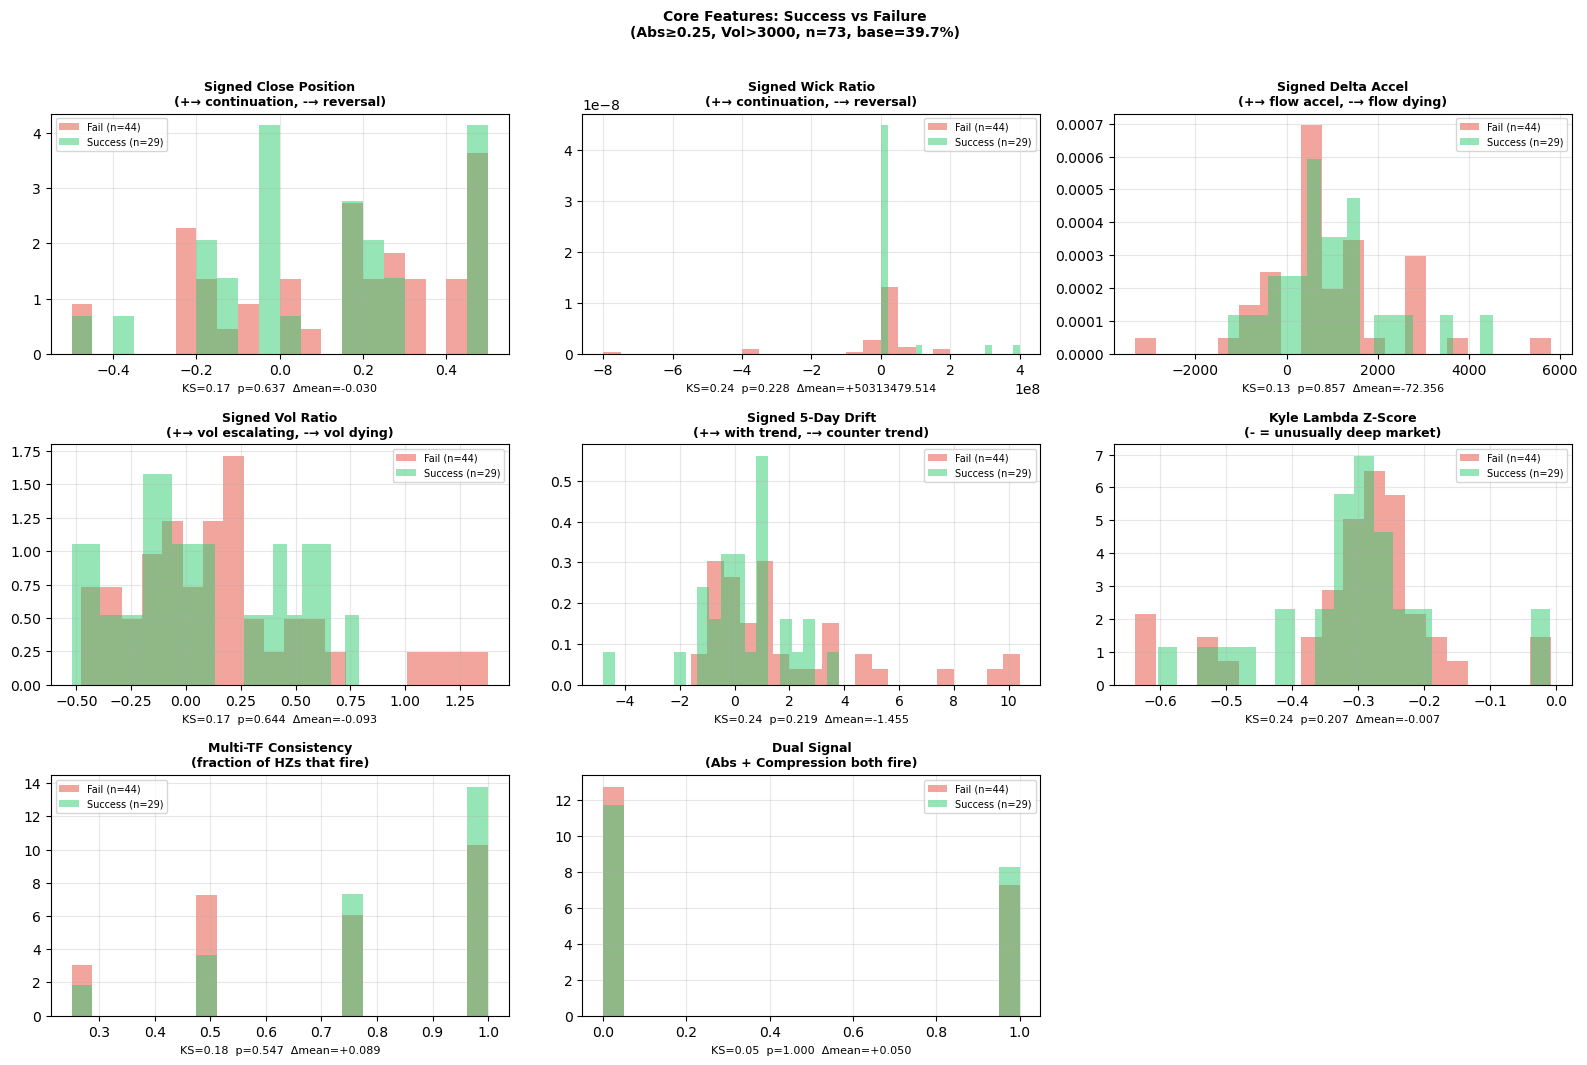


Core Feature Separation (KS test, sorted by KS stat):
           feature  ks_stat  ks_pval  mean_success     mean_fail     mean_diff
     lambda_zscore 0.244514 0.206884 -3.062730e-01 -2.991124e-01 -7.160671e-03
    signed_drift_5 0.238245 0.219176  3.310345e-01  1.786364e+00 -1.455329e+00
 signed_wick_ratio 0.236677 0.227800  2.758621e+07 -2.272727e+07  5.031348e+07
    tf_consistency 0.179467 0.546861  8.103448e-01  7.215909e-01  8.875392e-02
  signed_close_pos 0.166928 0.637088  1.108772e-01  1.413455e-01 -3.046828e-02
  signed_vol_ratio 0.166144 0.644215  6.452356e-02  1.575343e-01 -9.301071e-02
signed_delta_accel 0.134013 0.856682  9.290230e+02  1.001379e+03 -7.235580e+01
       dual_signal 0.050157 1.000000  4.137931e-01  3.636364e-01  5.015674e-02

════════════════════════════════════════════════════════════
SECTION B — RV RATIO COMBINATIONS (all num/den window pairs)
  Numerator  windows: [3, 4, 5, 10]
  Denominator windows: [15, 20, 40, 60]
═══════════════════════════════════

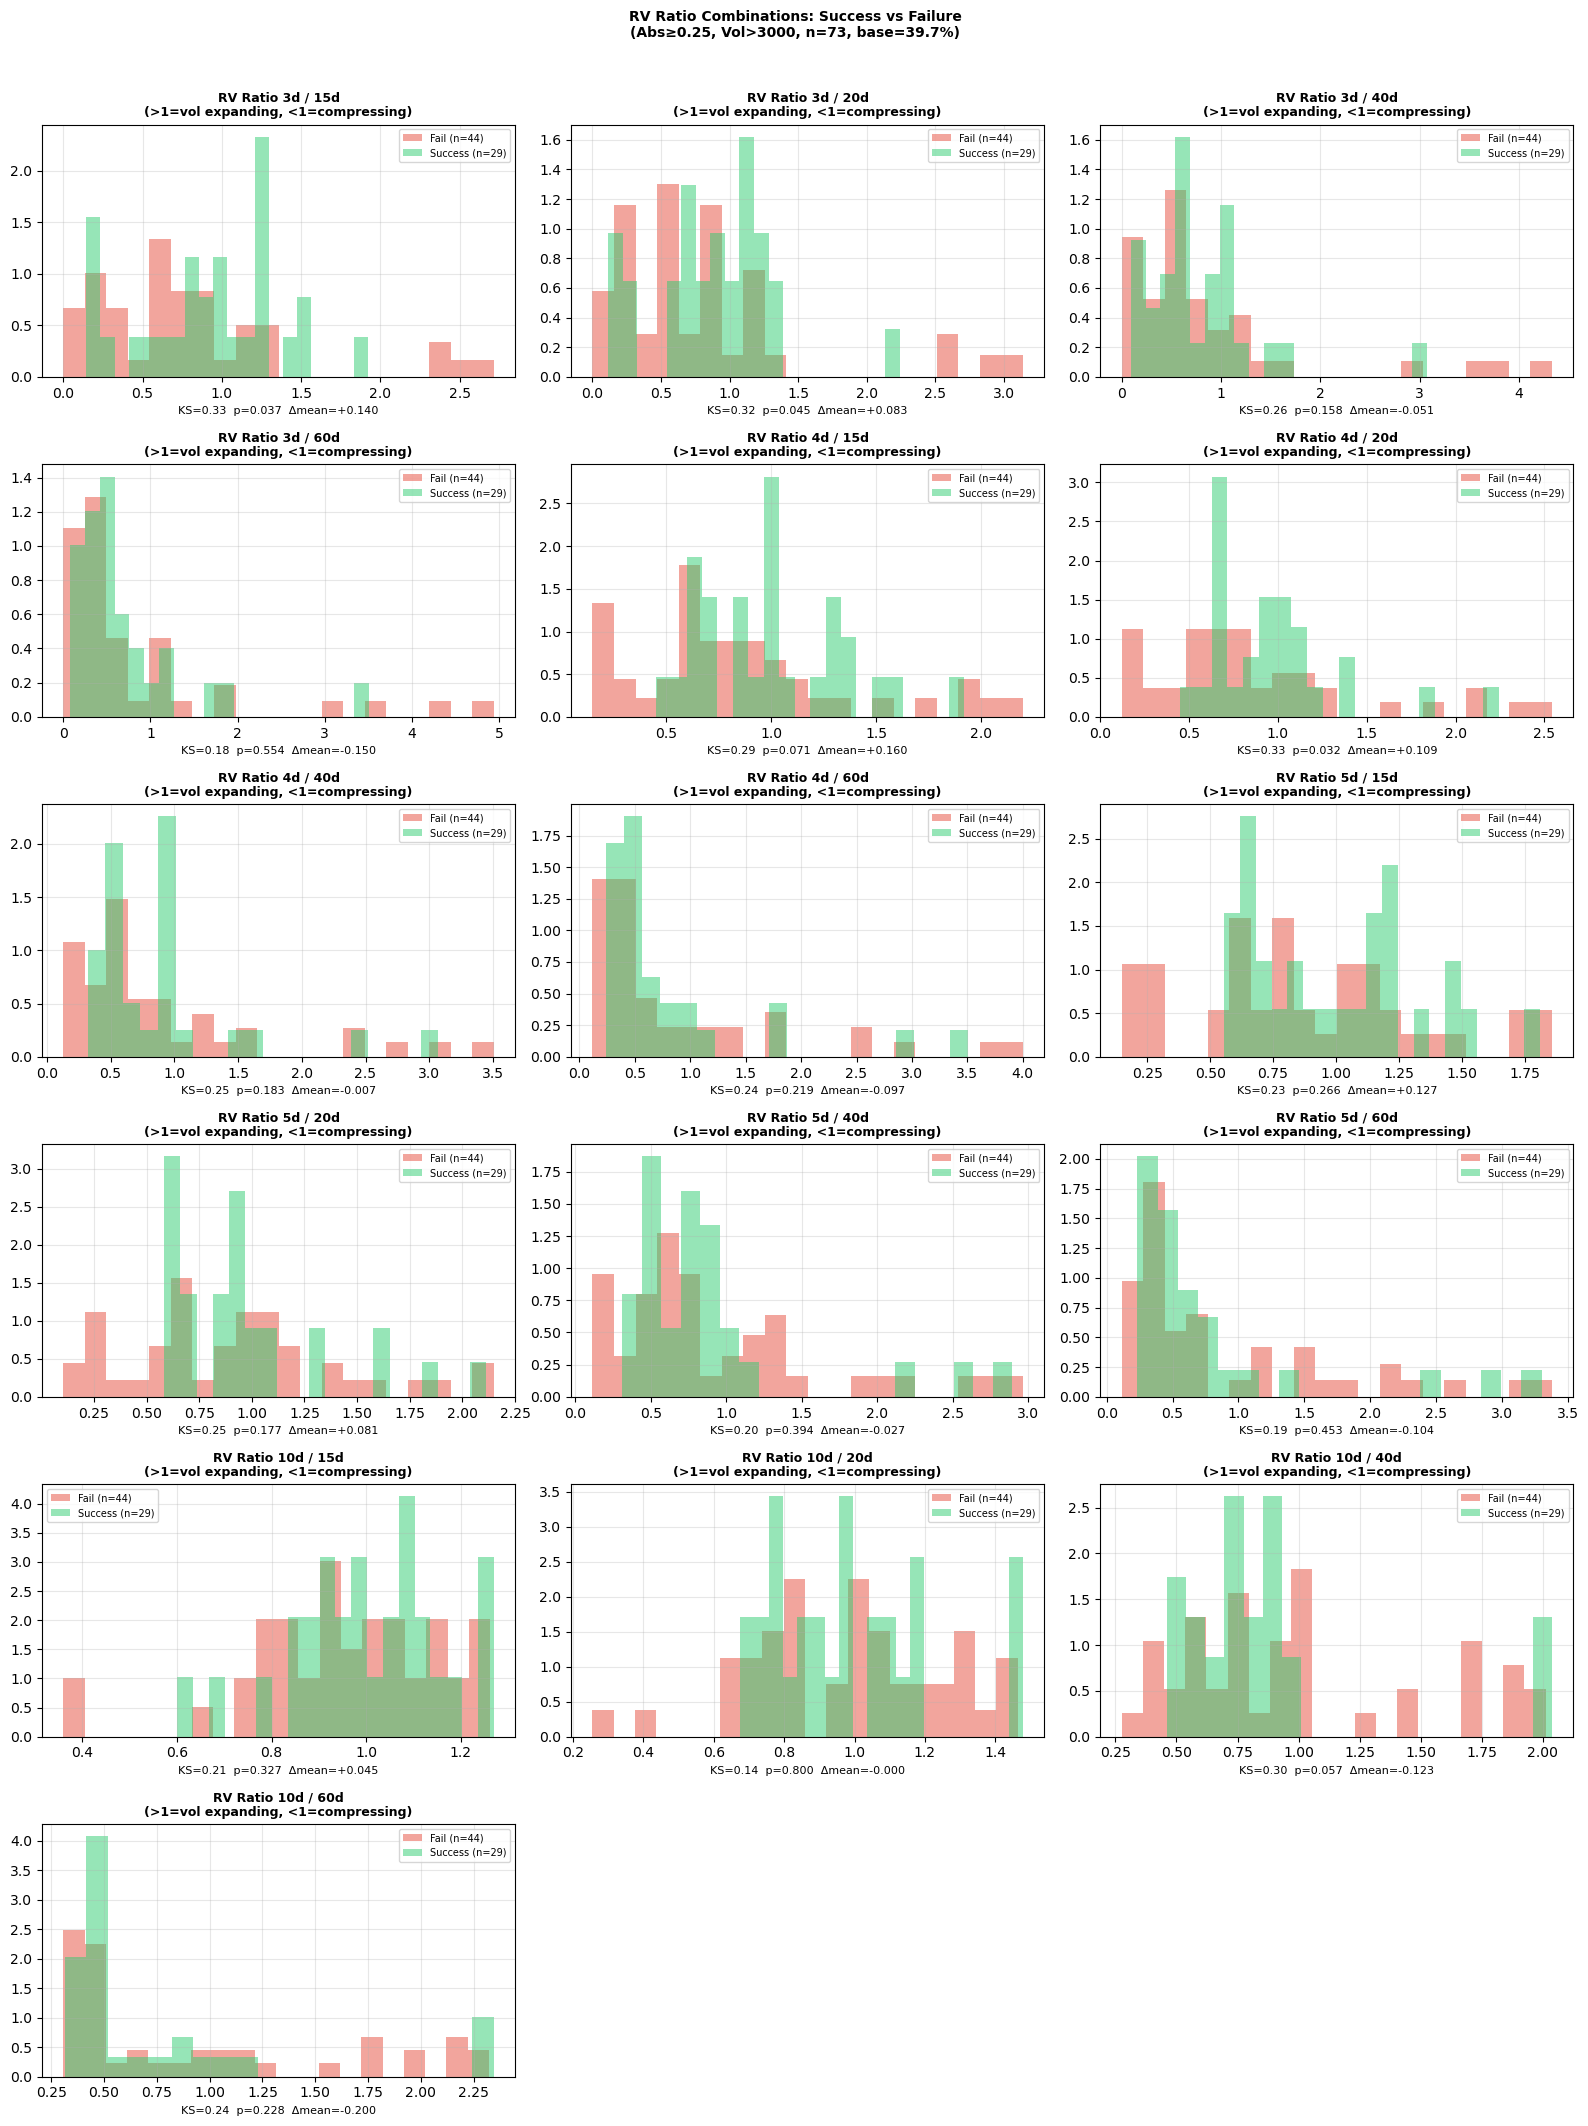


RV Ratio Separation (KS test, sorted by KS stat):
         feature  ks_stat  ks_pval  mean_success  mean_fail  mean_diff
 rv_ratio_4d_20d 0.329154 0.031554      0.979076   0.870389   0.108687
 rv_ratio_3d_15d 0.326019 0.036650      0.923616   0.783246   0.140370
 rv_ratio_3d_20d 0.315831 0.045026      0.893550   0.810646   0.082905
rv_ratio_10d_40d 0.304859 0.057451      0.871801   0.994678  -0.122877
 rv_ratio_4d_15d 0.294671 0.071003      1.002054   0.842381   0.159673
 rv_ratio_3d_40d 0.257837 0.157919      0.805626   0.856613  -0.050987
 rv_ratio_5d_20d 0.250000 0.177042      0.978152   0.897155   0.080997
 rv_ratio_4d_40d 0.248433 0.183465      0.900007   0.907503  -0.007496
 rv_ratio_4d_60d 0.238245 0.219176      0.788993   0.885860  -0.096867
rv_ratio_10d_60d 0.236677 0.227800      0.749842   0.950113  -0.200271
 rv_ratio_5d_15d 0.227273 0.265505      0.995484   0.868033   0.127451
rv_ratio_10d_15d 0.214734 0.327276      0.999781   0.954908   0.044872
 rv_ratio_5d_40d 0.202978 

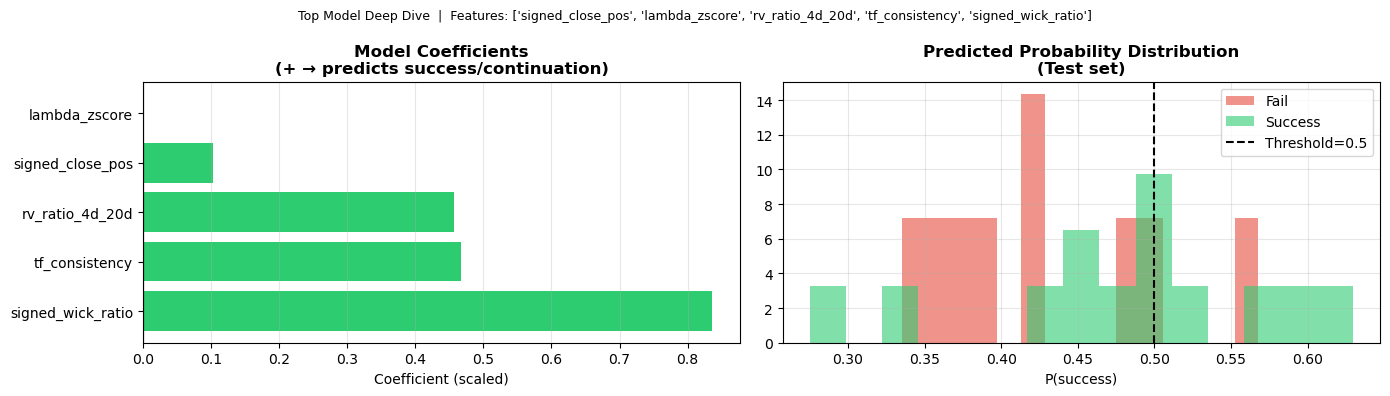


  Coefficients (sorted by |coef|):
          feature  coefficient
signed_wick_ratio     0.835506
   tf_consistency     0.467082
  rv_ratio_4d_20d     0.457062
 signed_close_pos     0.102183
    lambda_zscore     0.001955


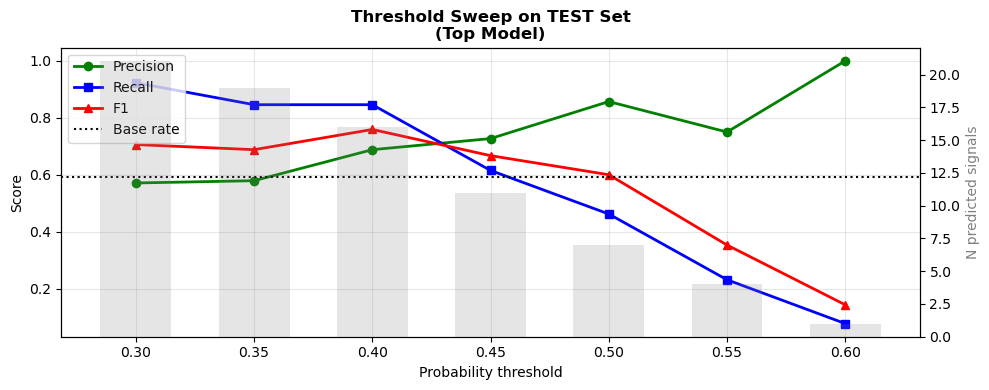


  Threshold Sweep Table (TEST):
 threshold  N_predicted  precision  recall    f1
      0.30           21      0.571   0.923 0.706
      0.35           19      0.579   0.846 0.688
      0.40           16      0.688   0.846 0.759
      0.45           11      0.727   0.615 0.667
      0.50            7      0.857   0.462 0.600
      0.55            4      0.750   0.231 0.353
      0.60            1      1.000   0.077 0.143
════════════════════════════════════════════════════════════
BUY vs SELL ABSORPTION SPLIT
════════════════════════════════════════════════════════════

  BUY ABSORPTION  n=35  success=15 (42.9%)  fail=20
           feature  mean_success     mean_fail          diff  ks_stat  p_value
 signed_wick_ratio        0.3248 -8.500000e+07  8.500000e+07    0.383    0.129
    signed_drift_5       -0.0133  1.070000e+00 -1.083300e+00    0.317    0.299
  signed_close_pos        0.1106  1.452000e-01 -3.460000e-02    0.300    0.363
   rv_ratio_4d_20d        0.9663  8.059000e-01  1.60400

In [5]:

# ═══════════════════════════════════════════════════════════════════════════════
# CELL 1 — SETUP & IMPORTS
# ═══════════════════════════════════════════════════════════════════════════════

import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, r"C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents")

import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_score, recall_score, f1_score
from itertools import combinations

from market_analysis.config import (
    PRODUCTS, FRONT_N, OHLC_START_DATE, OHLC_END_DATE, ABSORPTION, COMPRESSION
)
from market_analysis.data.ohlc import getData_OHLC_v2, fetch_ohlc_1d, get_ohlc_for_horizon
from market_analysis.utils.contracts import (
    MONTH_CODES, next_n_contract_months, get_front_instruments, fmt_contract
)
from market_analysis.signals.absorption.calculate import calculate_absorption
from market_analysis.signals.absorption.label import label_absorption
from market_analysis.signals.compression.calculate import calculate_compression

# ── Constants ──────────────────────────────────────────────────────────────────
PRODUCT_CODE      = "SM"
TICK_SIZE         = PRODUCTS[PRODUCT_CODE]["tick_size"]          # 0.1
ABS_THRESHOLD     = 0.25    # absorption_strength filter
COMP_THRESHOLD    = 0.30    # compression_score filter
VOLUME_MIN        = 3000    # ignore bars with total volume below this
HORIZONS          = ["1d", "2d", "3d", "5d"]
TODAY             = datetime.date.today()

# Label params (from your best sweep row)
REQUIRED_MOVE_TICKS = 3     # 5 × tick = 0.5 pts
SL_LOOKBACK         = 10
FORWARD_DAYS        = 10

# ── OHLC fetch window per instrument ─────────────────────────────────────────
# Each spread's data starts 7 months before the front-leg's expiry month.
# e.g. SMZ26-SMF27  → front leg = Dec 2026 → start = 2026-05-01
MONTHS_BEFORE_EXPIRY = 7

# ── RV Ratio config ──────────────────────────────────────────────────────────
# All combinations of (numerator_window, denominator_window) will be computed
# as separate features rv_ratio_{N}d_{D}d and each will get its own plot.
# Convention: short_window / long_window  → >1 = vol expanding, <1 = compressing
RV_NUMERATOR_WINDOWS   = [3,4, 5, 10]      # short lookback options (days)
RV_DENOMINATOR_WINDOWS = [15,20, 40,60]    # long  lookback options (days)
# ─────────────────────────────────────────────────────────────────────────────

print("✅ Setup complete")
print(f"   Product       : {PRODUCT_CODE}  tick={TICK_SIZE}")
print(f"   Abs threshold : {ABS_THRESHOLD}   Comp threshold: {COMP_THRESHOLD}")
print(f"   Volume filter : >{VOLUME_MIN}    Forward days: {FORWARD_DAYS}")
print(f"   Today         : {TODAY}")
print(f"   Fetch window  : {MONTHS_BEFORE_EXPIRY} months before front-leg expiry")
print(f"   RV numerators : {RV_NUMERATOR_WINDOWS}")
print(f"   RV denominators: {RV_DENOMINATOR_WINDOWS}")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 2 — INSTRUMENT SELECTION (front 4 + recently expired spreads)
# ═══════════════════════════════════════════════════════════════════════════════

def get_expired_spreads(product_code: str, n_expired: int = 3) -> list[str]:
    """
    Return the last `n_expired` calendar-consecutive spread pairs that expired
    before today. Uses the same traded_months list from config.
    """
    product  = PRODUCTS[product_code]
    traded   = sorted(product["traded_months"])
    prefix   = product["api_prefix"]

    # walk backwards from today to collect recent contract months
    y, m     = TODAY.year, TODAY.month
    collected = []
    while len(collected) < n_expired + 4:   # collect extra buffer
        m -= 1
        if m < 1:
            m = 12; y -= 1
        if m in traded:
            collected.append((y, m))

    collected.reverse()   # chronological order

    pairs = []
    for i in range(len(collected) - 1):
        front = fmt_contract(prefix, *collected[i])
        back  = fmt_contract(prefix, *collected[i + 1])
        pairs.append(f"{front}-{back}")

    # take the most recent n_expired pairs
    return pairs[-n_expired:]


def instr_fetch_start(instrument: str, months_before: int = MONTHS_BEFORE_EXPIRY) -> str:
    """
    Derive the OHLC fetch start date for a spread instrument.

    Logic: parse the front-leg contract → find its expiry month (year, month)
           → subtract `months_before` calendar months → return "YYYY-MM-01".

    Example:
        "SMZ26-SMF27"  → front leg SMZ26 → Dec 2026
                       → 7 months before Dec = May 2026
                       → start = "2026-05-01"
    """
    import re
    # Reverse MONTH_CODES so we can go from letter → month number
    CODE_TO_MONTH = {v: k for k, v in MONTH_CODES.items()}

    front_leg = instrument.split("-")[0]          # e.g. "SMZ26"
    m_obj     = re.match(r"^[A-Za-z]+([A-Z])(\d{2})$", front_leg)
    if not m_obj:
        # Fallback: use global OHLC_START_DATE if we can't parse
        return OHLC_START_DATE

    month_code = m_obj.group(1)                   # e.g. "Z"
    year_2dig  = int(m_obj.group(2))              # e.g. 26
    year       = 2000 + year_2dig                 # e.g. 2026
    month      = CODE_TO_MONTH.get(month_code, 1) # e.g. 12 (December)

    # subtract months_before months
    start_month = month - months_before
    start_year  = year
    while start_month < 1:
        start_month += 12
        start_year  -= 1

    return f"{start_year}-{start_month:02d}-01"


# Front 4 spreads starting from today
front_4 = get_front_instruments(PRODUCT_CODE, "spread",
                                reference_date=TODAY, front_n=4)

# ~3 recently expired spreads for extra data
expired_3 = get_expired_spreads(PRODUCT_CODE, n_expired=3)

ALL_INSTRUMENTS = expired_3 + front_4

print("═" * 60)
print("INSTRUMENTS SELECTED")
print("═" * 60)
print(f"  Expired spreads : {expired_3}")
print(f"  Front 4 spreads : {front_4}")
print(f"  Total           : {len(ALL_INSTRUMENTS)} instruments")
print()
print("  Derived fetch windows (7 months before front-leg expiry):")
for instr in ALL_INSTRUMENTS:
    print(f"    {instr:22s}  start={instr_fetch_start(instr)}")
print("═" * 60)


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 3 — FETCH, SCORE (absorption + compression) FOR ALL INSTRUMENTS
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("FETCHING & SCORING OHLC DATA")
print("═" * 60)

# Store per-instrument scored 1D DataFrames (before aggregation)
scored_1d = {}      # {instrument: df_with_absorption_1d}
scored_nd = {}      # {instrument: {horizon: df}}

for instr in ALL_INSTRUMENTS:
    print(f"\n  ▸ {instr}")

    # Per-instrument fetch window: 7 months before front-leg expiry
    instr_start = instr_fetch_start(instr)
    print(f"    fetch_start={instr_start}")

    # --- 1D fetch & absorption score ---
    df1d = fetch_ohlc_1d(instr, PRODUCT_CODE, getData_OHLC_v2,
                          start_date=instr_start, end_date=OHLC_END_DATE)
    if df1d is None or len(df1d) < 70:
        print(f"    [SKIP] not enough data (rows={len(df1d) if df1d is not None else 0})")
        continue

    df1d_abs  = calculate_absorption(df1d, window=60,
                                      tick_size=TICK_SIZE, strength_threshold=ABS_THRESHOLD)
    df1d_abs  = label_absorption(df1d_abs, tick=TICK_SIZE,
                                  required_move_ticks=REQUIRED_MOVE_TICKS,
                                  sl_lookback=SL_LOOKBACK,
                                  forward_days=FORWARD_DAYS)
    scored_1d[instr] = df1d_abs

    # --- compression on 1D ---
    df1d_comp, _ = calculate_compression(df1d.copy(),
                                          compression_threshold=COMP_THRESHOLD)

    # merge compression_score into absorption df by Date
    comp_merge = df1d_comp[["Date", "compression_score"]].copy()
    comp_merge["Date"] = pd.to_datetime(comp_merge["Date"]).dt.strftime("%Y-%m-%d")
    df1d_abs["Date"]   = pd.to_datetime(df1d_abs["Date"]).dt.strftime("%Y-%m-%d")
    df1d_abs = df1d_abs.merge(comp_merge.rename(columns={"compression_score": "comp_score_1d"}),
                               on="Date", how="left")
    scored_1d[instr] = df1d_abs

    # --- multi-horizon absorption scores (for consistency feature) ---
    scored_nd[instr] = {}
    for hz in HORIZONS:
        from market_analysis.data.ohlc import _aggregate_trailing
        from market_analysis.config import HORIZON_BARS
        n_bars = HORIZON_BARS[hz]
        dfh    = df1d.copy() if n_bars == 1 else _aggregate_trailing(df1d.copy(), n_bars)
        if dfh is None or len(dfh) < 65:
            continue
        dfh_sc = calculate_absorption(dfh, window=60,
                                       tick_size=TICK_SIZE, strength_threshold=ABS_THRESHOLD)
        scored_nd[instr][hz] = dfh_sc
    print(f"    rows={len(df1d_abs)}  "
          f"abs_events={(df1d_abs['absorption_strength'] > ABS_THRESHOLD).sum()}")

print("\n✅ Scoring complete")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 4 — FEATURE ENGINEERING
# (all past-only, no forward leakage, computed at bar t)
# ═══════════════════════════════════════════════════════════════════════════════

def build_resolution_features(df: pd.DataFrame,
                                scored_nd_for_instr: dict,
                                tick: float = 0.1,
                                epsilon: float = 1e-9) -> pd.DataFrame:
    """
    Add Stage-2 characterization features to a scored+labeled 1D DataFrame.
    All features use only [t-N : t] — strictly past-only.
    """
    d = df.copy().sort_values("Date").reset_index(drop=True)

    # ── 1. Intrabar: close position within bar ──────────────────────────────
    d["close_pos"] = (d["close"] - d["low"]) / (d["high"] - d["low"] + epsilon)
    # Signed for direction:
    #   BUY  absorption → reversal = price drops → close near LOW is BAD for buyers
    #     close_pos LOW (< 0.3) → sellers won intrabar → reversal hint → signed negative
    #   SELL absorption → reversal = price rises → close near HIGH is BAD for sellers
    # Convention: signed_close_pos > 0 → continuation, < 0 → reversal
    d["signed_close_pos"] = np.where(
        d["absorption_direction"] == "BUY",
        d["close_pos"] - 0.5,          # BUY: high → continuation (+), low → reversal (-)
        0.5 - d["close_pos"],          # SELL: low → continuation (+), high → reversal (-)
    )

    # ── 2. Intrabar: wick asymmetry ──────────────────────────────────────────
    d["upper_wick"] = d["high"] - d[["open", "close"]].max(axis=1)
    d["lower_wick"] = d[["open", "close"]].min(axis=1) - d["low"]
    d["wick_ratio"] = d["upper_wick"] / (d["lower_wick"] + epsilon)
    # BUY absorption: large upper wick → price pushed up but rejected → reversal
    # SELL absorption: large lower wick → price tested down but rejected → reversal
    # Sign: negative → reversal hint
    d["signed_wick_ratio"] = np.where(
        d["absorption_direction"] == "BUY",
        -(d["wick_ratio"] - 1.0),       # BUY: wick_ratio >> 1 → reversal → negative
        (d["wick_ratio"] - 1.0),        # SELL: wick_ratio << 1 → reversal → positive issue
    )
    # simpler: just keep raw wick_ratio and let model learn direction via dir dummy

    # ── 3. Delta ratio (how one-sided) ───────────────────────────────────────
    d["delta_ratio"] = d["buyvolume"] / (d["sellvolume"] + epsilon)

    # ── 4. Delta momentum: is aggressive flow accel or dying? ────────────────
    d["delta_accel"] = d["delta"] - d["delta"].shift(1).rolling(3, min_periods=1).mean()
    # Sign to success: BUY absorption — if delta_accel positive → buyers not exhausted → continuation
    # SELL absorption — if delta_accel negative (sell delta growing) → sellers not exhausted → continuation
    d["signed_delta_accel"] = np.where(
        d["absorption_direction"] == "BUY",
        d["delta_accel"],
        -d["delta_accel"],
    )

    # ── 5. Volume deceleration ───────────────────────────────────────────────
    vol_roll5 = d["volume"].shift(1).rolling(5, min_periods=2).mean()
    d["vol_ratio"] = d["volume"] / (vol_roll5 + epsilon)
    # vol_ratio < 1 → volume drying up → exhaustion → reversal (negative for our sign)
    # signed: positive → continuation hint
    d["signed_vol_ratio"] = d["vol_ratio"] - 1.0   # >0 = escalating, <0 = dying

    # ── 6. Price drift into absorption ───────────────────────────────────────
    d["drift_5"] = (d["close"] - d["close"].shift(5)) / (5 * tick + epsilon)
    # BUY absorption after falling prices (drift_5 < 0) → counter-trend buyers → reversal likely
    # SELL absorption after rising prices (drift_5 > 0) → counter-trend sellers → reversal likely
    # Sign: same direction as absorption = continuation, opposite = reversal
    d["signed_drift_5"] = np.where(
        d["absorption_direction"] == "BUY",
        d["drift_5"],          # rising drift + BUY absorption → continuation
        -d["drift_5"],         # falling drift + SELL absorption → continuation
    )

    # ── 7. Kyle Lambda: market depth anomaly ─────────────────────────────────
    price_change = d["close"].diff().abs()
    abs_delta    = d["delta"].abs()
    d["lambda_t"]     = price_change / (abs_delta + epsilon)
    d["lambda_5_avg"] = d["lambda_t"].shift(1).rolling(5, min_periods=2).mean()
    d["lambda_ratio"] = d["lambda_t"] / (d["lambda_5_avg"] + epsilon)
    lam_mean60 = d["lambda_t"].shift(1).rolling(60, min_periods=20).mean()
    lam_std60  = d["lambda_t"].shift(1).rolling(60, min_periods=20).std()
    d["lambda_zscore"] = (d["lambda_t"] - lam_mean60) / (lam_std60 + epsilon)
    # very negative lambda_zscore = unusually deep market = strong absorption event

    # ── 8. Realized volatility ratios (all configured combinations) ──────────
    # Config lists RV_NUMERATOR_WINDOWS and RV_DENOMINATOR_WINDOWS (defined in Cell 1).
    # For each (num_w, den_w) pair where num_w < den_w we compute:
    #   rv_ratio_{num_w}d_{den_w}d = rv(num_w) / rv(den_w)
    # >1 = vol expanding (short > long)  |  <1 = vol compressing
    log_ret = np.log(d["close"].replace(0, np.nan) / d["close"].shift(1).replace(0, np.nan))

    # Pre-compute each unique window std once
    all_windows = sorted(set(RV_NUMERATOR_WINDOWS + RV_DENOMINATOR_WINDOWS))
    rv_cache = {}
    for w in all_windows:
        mp = max(2, w // 2)
        rv_cache[w] = log_ret.rolling(w, min_periods=mp).std()

    for num_w in RV_NUMERATOR_WINDOWS:
        for den_w in RV_DENOMINATOR_WINDOWS:
            if num_w >= den_w:
                continue   # skip: numerator must be shorter than denominator
            col = f"rv_ratio_{num_w}d_{den_w}d"
            d[col] = rv_cache[num_w] / (rv_cache[den_w] + epsilon)

    # Keep the original rv_ratio name pointing at the first valid combo
    # so downstream code that references "rv_ratio" still works
    _first_num = next((n for n in RV_NUMERATOR_WINDOWS for den in RV_DENOMINATOR_WINDOWS if n < den), None)
    _first_den = next((den for n in RV_NUMERATOR_WINDOWS for den in RV_DENOMINATOR_WINDOWS if n < den), None)
    if _first_num is not None:
        d["rv_ratio"] = d[f"rv_ratio_{_first_num}d_{_first_den}d"]
    # rv_ratio > 1 → short-window vol > long-window vol → expanding (high-vol regime)
    # rv_ratio < 1 → short-window vol < long-window vol → compressing (quiet)

    # ── 9. Multi-timeframe consistency ───────────────────────────────────────
    # For each bar date, check if absorption_strength > ABS_THRESHOLD on other horizons
    d["Date_str"] = pd.to_datetime(d["Date"]).dt.strftime("%Y-%m-%d")
    tf_scores = {hz: {} for hz in HORIZONS}
    for hz, dfh in scored_nd_for_instr.items():
        if dfh is None or "absorption_strength" not in dfh.columns:
            continue
        dfh_copy = dfh.copy()
        dfh_copy["Date_str"] = pd.to_datetime(dfh_copy["Date"]).dt.strftime("%Y-%m-%d")
        for _, row in dfh_copy.iterrows():
            tf_scores[hz][row["Date_str"]] = row["absorption_strength"]

    consistency_vals = []
    for _, row in d.iterrows():
        date_key = row["Date_str"]
        fires = [
            1 if tf_scores[hz].get(date_key, 0) > ABS_THRESHOLD else 0
            for hz in HORIZONS
        ]
        consistency_vals.append(np.mean(fires))
    d["tf_consistency"] = consistency_vals

    # ── 10. Dual signal: both absorption AND compression fire ─────────────────
    d["dual_signal"] = (
        (d["absorption_strength"] > ABS_THRESHOLD) &
        (d.get("comp_score_1d", pd.Series(0, index=d.index)).fillna(0) > COMP_THRESHOLD)
    ).astype(float)

    # ── 11. Direction dummy (BUY=1, SELL=0) ──────────────────────────────────
    d["is_buy_absorption"] = (d["absorption_direction"] == "BUY").astype(float)

    return d


# Apply feature engineering to all instruments
print("═" * 60)
print("FEATURE ENGINEERING")
print("═" * 60)

featured = {}
for instr, df in scored_1d.items():
    nd_for_instr = scored_nd.get(instr, {})
    featured[instr] = build_resolution_features(df, nd_for_instr, tick=TICK_SIZE)
    print(f"  ✓ {instr}  columns={len(featured[instr].columns)}")

print("✅ Feature engineering complete")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 5 — POOL ABSORPTION EVENTS & SUMMARY
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("POOLING ABSORPTION EVENTS (volume > 3000, strength > 0.25)")
print("═" * 60)

FEATURE_COLS = [
    "signed_close_pos",
    "signed_wick_ratio",
    "signed_delta_accel",
    "signed_vol_ratio",
    "signed_drift_5",
    "lambda_zscore",
    "rv_ratio",
    "tf_consistency",
    "dual_signal",
    "is_buy_absorption",
    # raw (unsigned) versions also included for exploration
    "close_pos",
    "wick_ratio",
    "vol_ratio",
    "delta_ratio",
    "lambda_ratio",
]

all_events = []
for instr, df in featured.items():
    mask = (
        (df["absorption_strength"] > ABS_THRESHOLD) &
        (df["volume"] > VOLUME_MIN) &
        (df["sl_success"].notna())
    )
    subset = df[mask].copy()
    subset["instrument"] = instr
    all_events.append(subset)

if not all_events:
    print("❌ No events found — check thresholds or data fetch")
else:
    pool = pd.concat(all_events, ignore_index=True)
    pool = pool.sort_values("Date").reset_index(drop=True)

    n_total   = len(pool)
    n_success = int(pool["sl_success"].sum())
    n_fail    = int((pool["sl_success"] == 0).sum())
    base_rate = n_success / n_total if n_total > 0 else 0

    print(f"\n  Total absorption events : {n_total}")
    print(f"  Success (reversal)      : {n_success}  ({100*base_rate:.1f}%)")
    print(f"  Failure                 : {n_fail}")
    print(f"\n  Per instrument:")
    for instr in pool["instrument"].unique():
        sub = pool[pool["instrument"] == instr]
        s = int(sub["sl_success"].sum())
        print(f"    {instr:20s}  n={len(sub):3d}  success={s}")
    print()

    # ensure features are numeric
    for fc in FEATURE_COLS:
        if fc in pool.columns:
            pool[fc] = pd.to_numeric(pool[fc], errors="coerce")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 6 — DISTRIBUTION PLOTS: Feature separation (success vs fail)
# ═══════════════════════════════════════════════════════════════════════════════

# ── Helper: plot a set of features and return separation stats ────────────────
def _plot_feature_grid(pool_df, feature_list, title_prefix=""):
    """
    Plots histograms for each (feat, label) tuple in feature_list.
    Returns a list of separation stat dicts.
    """
    suc = pool_df[pool_df["sl_success"] == 1]
    fai = pool_df[pool_df["sl_success"] == 0]
    stats_out = []

    n_cols = 3
    n_rows = (len(feature_list) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3.5))
    axes = axes.flatten()

    for ax, (feat, label) in zip(axes, feature_list):
        if feat not in pool_df.columns:
            ax.set_visible(False); continue
        s_vals = suc[feat].dropna()
        f_vals = fai[feat].dropna()
        if len(s_vals) == 0 or len(f_vals) == 0:
            ax.set_visible(False); continue

        ax.hist(f_vals, bins=20, alpha=0.5, color="#e74c3c", density=True,
                label=f"Fail (n={len(f_vals)})")
        ax.hist(s_vals, bins=20, alpha=0.5, color="#2ecc71", density=True,
                label=f"Success (n={len(s_vals)})")
        ks_stat, ks_pval = stats.ks_2samp(s_vals, f_vals)
        mean_diff = s_vals.mean() - f_vals.mean()
        ax.set_title(label, fontsize=9, fontweight="bold")
        ax.set_xlabel(f"KS={ks_stat:.2f}  p={ks_pval:.3f}  Δmean={mean_diff:+.3f}", fontsize=8)
        ax.legend(fontsize=7); ax.grid(alpha=0.3)
        stats_out.append({"feature": feat, "ks_stat": ks_stat, "ks_pval": ks_pval,
                           "mean_success": s_vals.mean(), "mean_fail": f_vals.mean(),
                           "mean_diff": mean_diff})

    for ax in axes[len(feature_list):]:
        ax.set_visible(False)
    plt.suptitle(f"{title_prefix}\n"
                 f"(Abs≥{ABS_THRESHOLD}, Vol>{VOLUME_MIN}, "
                 f"n={n_total}, base={base_rate:.1%})",
                 fontsize=10, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()
    return stats_out


# ── Section A: core signed features ──────────────────────────────────────────
CORE_PLOT_FEATURES = [
    ("signed_close_pos",   "Signed Close Position\n(+→ continuation, -→ reversal)"),
    ("signed_wick_ratio",  "Signed Wick Ratio\n(+→ continuation, -→ reversal)"),
    ("signed_delta_accel", "Signed Delta Accel\n(+→ flow accel, -→ flow dying)"),
    ("signed_vol_ratio",   "Signed Vol Ratio\n(+→ vol escalating, -→ vol dying)"),
    ("signed_drift_5",     "Signed 5-Day Drift\n(+→ with trend, -→ counter trend)"),
    ("lambda_zscore",      "Kyle Lambda Z-Score\n(- = unusually deep market)"),
    ("tf_consistency",     "Multi-TF Consistency\n(fraction of HZs that fire)"),
    ("dual_signal",        "Dual Signal\n(Abs + Compression both fire)"),
]

print("═" * 60)
print("SECTION A — CORE FEATURE SEPARATION (success vs failure)")
print("═" * 60)
sep_stats = _plot_feature_grid(pool, CORE_PLOT_FEATURES,
                                title_prefix="Core Features: Success vs Failure")

sep_df = pd.DataFrame(sep_stats).sort_values("ks_stat", ascending=False)
print("\nCore Feature Separation (KS test, sorted by KS stat):")
print(sep_df[["feature", "ks_stat", "ks_pval", "mean_success", "mean_fail", "mean_diff"]].to_string(index=False))


# ── Section B: RV Ratio — all window combinations ────────────────────────────
print()
print("═" * 60)
print("SECTION B — RV RATIO COMBINATIONS (all num/den window pairs)")
print(f"  Numerator  windows: {RV_NUMERATOR_WINDOWS}")
print(f"  Denominator windows: {RV_DENOMINATOR_WINDOWS}")
print("═" * 60)

RV_PLOT_FEATURES = []
for num_w in RV_NUMERATOR_WINDOWS:
    for den_w in RV_DENOMINATOR_WINDOWS:
        if num_w >= den_w:
            continue
        col   = f"rv_ratio_{num_w}d_{den_w}d"
        label = (f"RV Ratio {num_w}d / {den_w}d\n"
                 f"(>1=vol expanding, <1=compressing)")
        RV_PLOT_FEATURES.append((col, label))

if RV_PLOT_FEATURES:
    rv_sep_stats = _plot_feature_grid(pool, RV_PLOT_FEATURES,
                                       title_prefix="RV Ratio Combinations: Success vs Failure")
    rv_sep_df = pd.DataFrame(rv_sep_stats).sort_values("ks_stat", ascending=False)
    print("\nRV Ratio Separation (KS test, sorted by KS stat):")
    print(rv_sep_df[["feature", "ks_stat", "ks_pval",
                     "mean_success", "mean_fail", "mean_diff"]].to_string(index=False))
    print(f"\n  → Best RV combo: {rv_sep_df.iloc[0]['feature']}  "
          f"KS={rv_sep_df.iloc[0]['ks_stat']:.3f}")
    # Store best for use in model sweep
    BEST_RV_FEATURE = rv_sep_df.iloc[0]["feature"]
else:
    print("  No valid RV combos (all numerators >= denominators). Check config.")
    BEST_RV_FEATURE = "rv_ratio"

# Combined separation table (all features)
all_sep_df = pd.concat([sep_df, rv_sep_df if RV_PLOT_FEATURES else pd.DataFrame()],
                        ignore_index=True).sort_values("ks_stat", ascending=False)
print("\n── ALL FEATURES combined (sorted by KS stat) ──")
print(all_sep_df[["feature", "ks_stat", "ks_pval", "mean_diff"]].to_string(index=False))
success_events = pool[pool["sl_success"] == 1]
fail_events    = pool[pool["sl_success"] == 0]


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 7 — WALK-FORWARD TRAIN / TEST SPLIT
# ═══════════════════════════════════════════════════════════════════════════════

pool_sorted = pool.sort_values("Date").reset_index(drop=True)
split_idx   = int(len(pool_sorted) * 0.70)
train_df    = pool_sorted.iloc[:split_idx].copy()
test_df     = pool_sorted.iloc[split_idx:].copy()

print("═" * 60)
print("WALK-FORWARD SPLIT")
print("═" * 60)
print(f"  Train: {len(train_df)} events | {train_df['Date'].min()} → {train_df['Date'].max()}")
print(f"  Test : {len(test_df)} events  | {test_df['Date'].min()} → {test_df['Date'].max()}")
print(f"  Train base rate: {train_df['sl_success'].mean():.1%}")
print(f"  Test  base rate: {test_df['sl_success'].mean():.1%}")


def get_Xy(df: pd.DataFrame, feats: list[str]):
    """Extract X, y matrices from a pool DataFrame, dropping NaN rows."""
    sub  = df[feats + ["sl_success"]].dropna()
    X    = sub[feats].values.astype(float)
    y    = sub["sl_success"].values.astype(int)
    return X, y, sub.index


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 8 — FEATURE COMBO SWEEP (SGD Logistic Regression)
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("FEATURE COMBINATION SWEEP (SGD Logistic Regression)")
print("═" * 60)

# Signed feature candidates (theoretically motivated).
# rv_ratio is replaced by the best-KS combo found in Cell 6 Section B.
SIGNED_FEATS = [
    "signed_close_pos",
    "signed_delta_accel",
    "signed_vol_ratio",
    "signed_drift_5",
    "lambda_zscore",
    BEST_RV_FEATURE,       # best RV window combo by KS separation
    "tf_consistency",
    "signed_wick_ratio",
]

# Filter to only features that exist and have enough variance
available_feats = [
    f for f in SIGNED_FEATS
    if f in train_df.columns and train_df[f].dropna().std() > 1e-6
]
print(f"  Available features: {available_feats}\n")

# Combos of size 2–6 (theoretically motivated pairs first, then expand)
# Plus one full-feature model
combo_sizes = [2, 3, 4, 5]
combos      = []
for size in combo_sizes:
    combos.extend(list(combinations(available_feats, size)))
# Add full model
combos.append(tuple(available_feats))

print(f"  Total combos to evaluate: {len(combos)}")

def make_sgd_pipeline():
    clf = SGDClassifier(
        loss="log_loss",
        penalty="l2",
        alpha=0.01,
        max_iter=1000,
        tol=1e-4,
        random_state=42,
        class_weight="balanced",
    )
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])


results = []
for combo in combos:
    feats = list(combo)
    X_tr, y_tr, _ = get_Xy(train_df, feats)
    X_te, y_te, _ = get_Xy(test_df,  feats)

    if len(X_tr) < 20 or len(X_te) < 5:
        continue
    if len(np.unique(y_tr)) < 2 or len(np.unique(y_te)) < 2:
        continue

    pipe = make_sgd_pipeline()
    try:
        pipe.fit(X_tr, y_tr)
    except Exception:
        continue

    y_pred_prob = pipe.predict_proba(X_te)[:, 1]
    # Use 0.5 as default threshold
    y_pred = (y_pred_prob >= 0.5).astype(int)

    prec   = precision_score(y_te, y_pred, zero_division=0)
    rec    = recall_score(y_te,    y_pred, zero_division=0)
    f1     = f1_score(y_te,        y_pred, zero_division=0)
    # Lift over base rate
    base   = y_te.mean() if y_te.mean() > 0 else 1e-9
    lift   = prec / base

    results.append({
        "features"  : feats,
        "n_feats"   : len(feats),
        "precision" : round(prec, 4),
        "recall"    : round(rec,  4),
        "f1"        : round(f1,   4),
        "lift"      : round(lift, 4),
        "n_train"   : len(X_tr),
        "n_test"    : len(X_te),
    })

results_df = pd.DataFrame(results).sort_values("precision", ascending=False).reset_index(drop=True)

print("\n  Top 15 combos by Precision on TEST set:")
print("─" * 80)
for i, row in results_df.head(15).iterrows():
    print(f"  [{i+1:2d}] n_feats={row['n_feats']}  "
          f"P={row['precision']:.3f}  R={row['recall']:.3f}  "
          f"F1={row['f1']:.3f}  Lift={row['lift']:.2f}")
    print(f"       features: {row['features']}")

print(f"\n  Base rate on test: {test_df['sl_success'].mean():.1%}")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 9 — TOP MODEL DEEP DIVE (threshold sweep + coefficients)
# ═══════════════════════════════════════════════════════════════════════════════

# Pick top combo by precision
best_row   = results_df.iloc[0]
best_feats = best_row["features"]
print("═" * 60)
print(f"TOP MODEL ANALYSIS")
print("═" * 60)
print(f"  Features: {best_feats}")
print(f"  Train n={best_row['n_train']}  Test n={best_row['n_test']}")
print(f"  Precision={best_row['precision']:.3f}  Recall={best_row['recall']:.3f}  "
      f"F1={best_row['f1']:.3f}  Lift={best_row['lift']:.2f}")

X_tr, y_tr, _ = get_Xy(train_df, best_feats)
X_te, y_te, _ = get_Xy(test_df,  best_feats)

best_pipe = make_sgd_pipeline()
best_pipe.fit(X_tr, y_tr)
y_prob_te = best_pipe.predict_proba(X_te)[:, 1]

# ── Coefficients ──────────────────────────────────────────────────────────────
coefs = best_pipe.named_steps["clf"].coef_[0]
coef_df = pd.DataFrame({
    "feature": best_feats,
    "coefficient": coefs,
    "abs_coef": np.abs(coefs)
}).sort_values("abs_coef", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Coefficient bar chart
ax = axes[0]
colors = ["#2ecc71" if c > 0 else "#e74c3c" for c in coef_df["coefficient"]]
ax.barh(coef_df["feature"], coef_df["coefficient"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Model Coefficients\n(+ → predicts success/continuation)", fontweight="bold")
ax.set_xlabel("Coefficient (scaled)")
ax.grid(alpha=0.3, axis="x")

# Probability distribution by outcome
ax = axes[1]
ax.hist(y_prob_te[y_te == 0], bins=15, alpha=0.6, color="#e74c3c", density=True, label="Fail")
ax.hist(y_prob_te[y_te == 1], bins=15, alpha=0.6, color="#2ecc71", density=True, label="Success")
ax.axvline(0.5, color="black", linestyle="--", label="Threshold=0.5")
ax.set_title("Predicted Probability Distribution\n(Test set)", fontweight="bold")
ax.set_xlabel("P(success)")
ax.legend()
ax.grid(alpha=0.3)

plt.suptitle(f"Top Model Deep Dive  |  Features: {best_feats}", fontsize=9)
plt.tight_layout()
plt.show()

print("\n  Coefficients (sorted by |coef|):")
print(coef_df[["feature", "coefficient"]].to_string(index=False))


# ── Threshold sweep on test set ───────────────────────────────────────────────
thresholds = np.arange(0.30, 0.85, 0.05)
sweep_rows = []
for t in thresholds:
    y_pred_t = (y_prob_te >= t).astype(int)
    n_pred   = y_pred_t.sum()
    if n_pred == 0:
        continue
    p = precision_score(y_te, y_pred_t, zero_division=0)
    r = recall_score(y_te,    y_pred_t, zero_division=0)
    f = f1_score(y_te,        y_pred_t, zero_division=0)
    sweep_rows.append({"threshold": round(t, 2), "N_predicted": n_pred,
                        "precision": round(p, 3), "recall": round(r, 3), "f1": round(f, 3)})

sweep_res = pd.DataFrame(sweep_rows)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(sweep_res["threshold"], sweep_res["precision"], "g-o", label="Precision", linewidth=2)
ax.plot(sweep_res["threshold"], sweep_res["recall"],    "b-s", label="Recall",    linewidth=2)
ax.plot(sweep_res["threshold"], sweep_res["f1"],        "r-^", label="F1",        linewidth=2)
ax2 = ax.twinx()
ax2.bar(sweep_res["threshold"], sweep_res["N_predicted"], alpha=0.2, color="gray",
        width=0.03, label="N predicted")
ax2.set_ylabel("N predicted signals", color="gray")
ax.axhline(test_df["sl_success"].mean(), color="black", linestyle=":", label=f"Base rate")
ax.set_xlabel("Probability threshold")
ax.set_ylabel("Score")
ax.set_title("Threshold Sweep on TEST Set\n(Top Model)", fontweight="bold")
ax.legend(loc="upper left"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\n  Threshold Sweep Table (TEST):")
print(sweep_res.to_string(index=False))


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 10 — BUY vs SELL ABSORPTION SPLIT ANALYSIS
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("BUY vs SELL ABSORPTION SPLIT")
print("═" * 60)

for direction in ["BUY", "SELL"]:
    sub = pool[pool["absorption_direction"] == direction].copy()
    n   = len(sub)
    if n < 15:
        print(f"  {direction}: too few events ({n}), skipping")
        continue

    s_sub = sub[sub["sl_success"] == 1]
    f_sub = sub[sub["sl_success"] == 0]
    print(f"\n  {direction} ABSORPTION  n={n}  "
          f"success={len(s_sub)} ({100*len(s_sub)/n:.1f}%)  "
          f"fail={len(f_sub)}")

    feat_means = []
    for feat in available_feats:
        if feat not in sub.columns:
            continue
        sv = s_sub[feat].dropna()
        fv = f_sub[feat].dropna()
        if len(sv) < 3 or len(fv) < 3:
            continue
        ks, pv = stats.ks_2samp(sv, fv)
        feat_means.append({
            "feature": feat,
            "mean_success": round(sv.mean(), 4),
            "mean_fail"   : round(fv.mean(), 4),
            "diff"        : round(sv.mean() - fv.mean(), 4),
            "ks_stat"     : round(ks, 3),
            "p_value"     : round(pv, 3),
        })

    feat_means_df = pd.DataFrame(feat_means).sort_values("ks_stat", ascending=False)
    print(feat_means_df.to_string(index=False))

    # Train direction-specific model if enough data
    sub_sorted = sub.sort_values("Date").reset_index(drop=True)
    sp = int(len(sub_sorted) * 0.70)
    tr_d = sub_sorted.iloc[:sp]
    te_d = sub_sorted.iloc[sp:]
    if len(tr_d) < 15 or len(te_d) < 5:
        print(f"  [{direction}] Not enough data for direction model")
        continue

    X_tr_d, y_tr_d, _ = get_Xy(tr_d, best_feats)
    X_te_d, y_te_d, _ = get_Xy(te_d, best_feats)
    if len(np.unique(y_tr_d)) < 2:
        print(f"  [{direction}] Only one class in train, skipping")
        continue

    pipe_d = make_sgd_pipeline()
    pipe_d.fit(X_tr_d, y_tr_d)
    if len(np.unique(y_te_d)) < 2:
        print(f"  [{direction}] Only one class in test set, skipping metrics")
        continue
    y_pred_d = pipe_d.predict(X_te_d)
    print(f"\n  [{direction}] Direction-specific model (same features):")
    print(f"    Precision={precision_score(y_te_d, y_pred_d, zero_division=0):.3f}  "
          f"Recall={recall_score(y_te_d, y_pred_d, zero_division=0):.3f}  "
          f"F1={f1_score(y_te_d, y_pred_d, zero_division=0):.3f}")
    coefs_d = pipe_d.named_steps["clf"].coef_[0]
    print(f"    Coefficients: " +
          "  ".join(f"{f}={c:+.3f}" for f, c in zip(best_feats, coefs_d)))


print("\n" + "═" * 60)
print("ANALYSIS COMPLETE")
print("═" * 60)


# try 3

✅ Setup complete
   Product       : SM  tick=0.1
   Abs threshold : 0.25   Comp threshold: 0.3
   Volume filter : >3000    Forward days: 10
   Today         : 2026-09-21
   Fetch window  : 7 months before front-leg expiry
   RV numerators : [3, 4, 5, 10]
   RV denominators: [15, 20, 40]
════════════════════════════════════════════════════════════
INSTRUMENTS SELECTED
════════════════════════════════════════════════════════════
  Expired spreads : ['SMH26-SMK26', 'SMK26-SMN26', 'SMN26-SMQ26']
  Front 4 spreads : ['SMV26-SMZ26', 'SMZ26-SMF27', 'SMF27-SMH27', 'SMH27-SMK27']
  Total           : 7 instruments

  Derived fetch windows (7 months before front-leg expiry):
    SMH26-SMK26             start=2025-08-01
    SMK26-SMN26             start=2025-10-01
    SMN26-SMQ26             start=2025-12-01
    SMV26-SMZ26             start=2026-03-01
    SMZ26-SMF27             start=2026-05-01
    SMF27-SMH27             start=2026-06-01
    SMH27-SMK27             start=2026-08-01
════════════

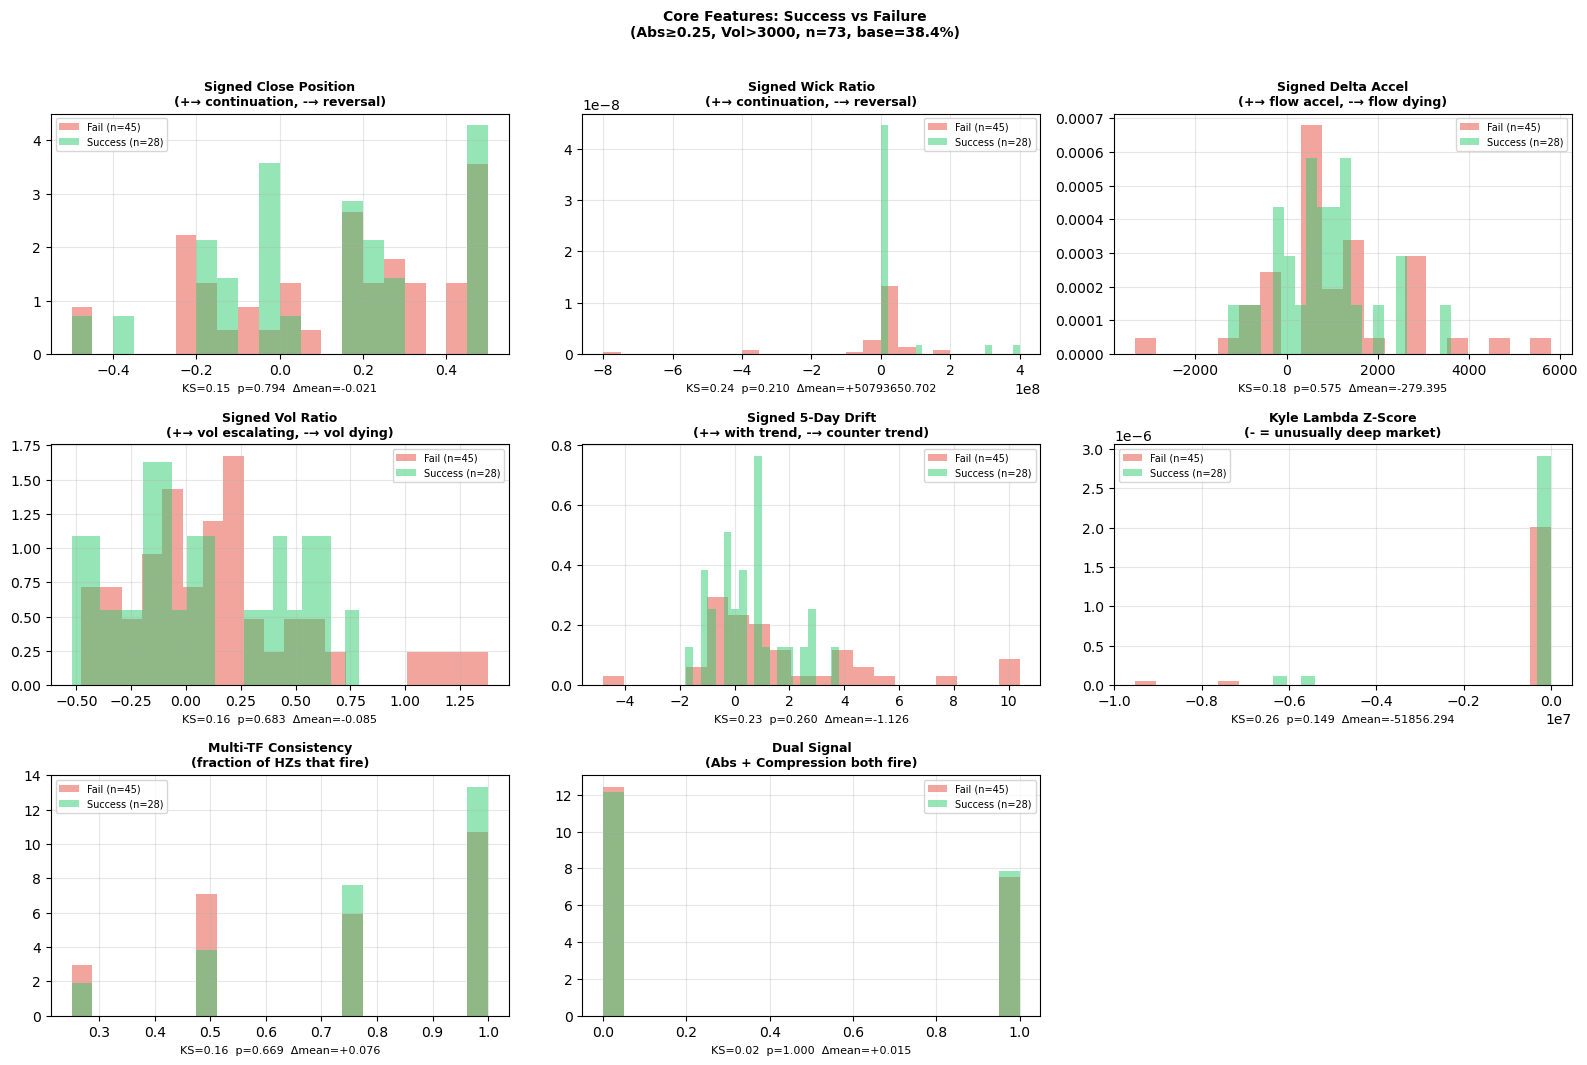


Core Feature Separation (KS test, sorted by KS stat):
           feature  ks_stat  ks_pval  mean_success     mean_fail     mean_diff
     lambda_zscore 0.261905 0.149231 -4.236859e+05 -3.718296e+05 -5.185629e+04
 signed_wick_ratio 0.243651 0.210197  2.857143e+07 -2.222222e+07  5.079365e+07
    signed_drift_5 0.230952 0.260435  5.142857e-01  1.640000e+00 -1.125714e+00
signed_delta_accel 0.176984 0.574647  8.004048e+02  1.079800e+03 -2.793952e+02
    tf_consistency 0.163492 0.669021  8.035714e-01  7.277778e-01  7.579365e-02
  signed_vol_ratio 0.161905 0.683091  6.832749e-02  1.531005e-01 -8.477298e-02
  signed_close_pos 0.145238 0.794364  1.164605e-01  1.371944e-01 -2.073389e-02
       dual_signal 0.015079 1.000000  3.928571e-01  3.777778e-01  1.507937e-02

════════════════════════════════════════════════════════════
SECTION B — RV RATIO COMBINATIONS (all num/den window pairs)
  Numerator  windows: [3, 4, 5, 10]
  Denominator windows: [15, 20, 40]
═══════════════════════════════════════

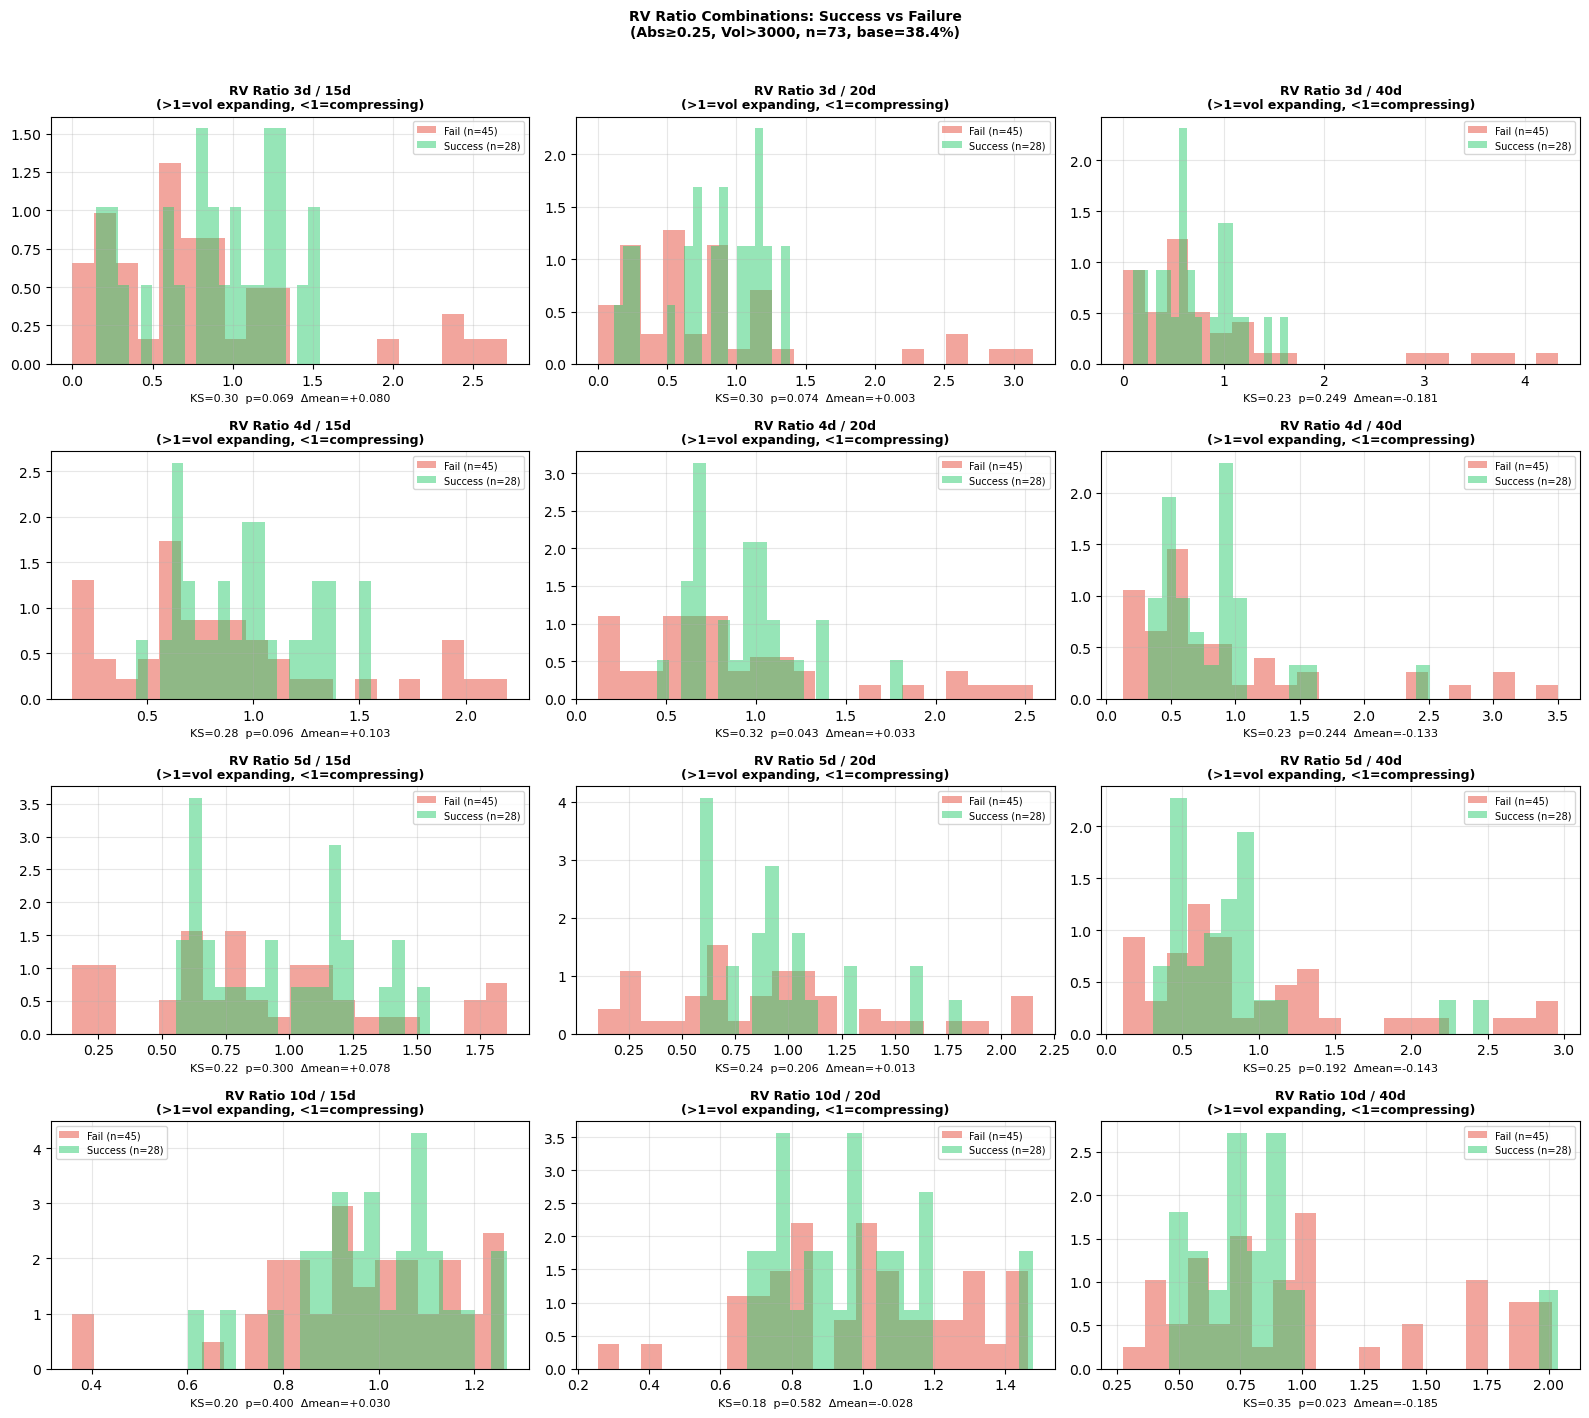


RV Ratio Separation (KS test, sorted by KS stat):
         feature  ks_stat  ks_pval  mean_success  mean_fail  mean_diff
rv_ratio_10d_40d 0.346032 0.022930      0.831765   1.016859  -0.185094
 rv_ratio_4d_20d 0.319841 0.043089      0.933976   0.900866   0.033110
 rv_ratio_3d_15d 0.300794 0.068523      0.888054   0.808493   0.079562
 rv_ratio_3d_20d 0.296825 0.073820      0.845396   0.842451   0.002946
 rv_ratio_4d_15d 0.284127 0.095567      0.969293   0.866314   0.102979
 rv_ratio_5d_40d 0.248413 0.192175      0.824906   0.967466  -0.142559
 rv_ratio_5d_20d 0.244444 0.205683      0.937653   0.924154   0.013499
 rv_ratio_4d_40d 0.234921 0.243850      0.822465   0.955585  -0.133119
 rv_ratio_3d_40d 0.234127 0.249371      0.724713   0.905825  -0.181112
 rv_ratio_5d_15d 0.222222 0.300364      0.966456   0.888927   0.077530
rv_ratio_10d_15d 0.203968 0.399811      0.991008   0.961364   0.029643
rv_ratio_10d_20d 0.176190 0.581922      0.965625   0.993280  -0.027655

  → Best RV combo: rv_rat

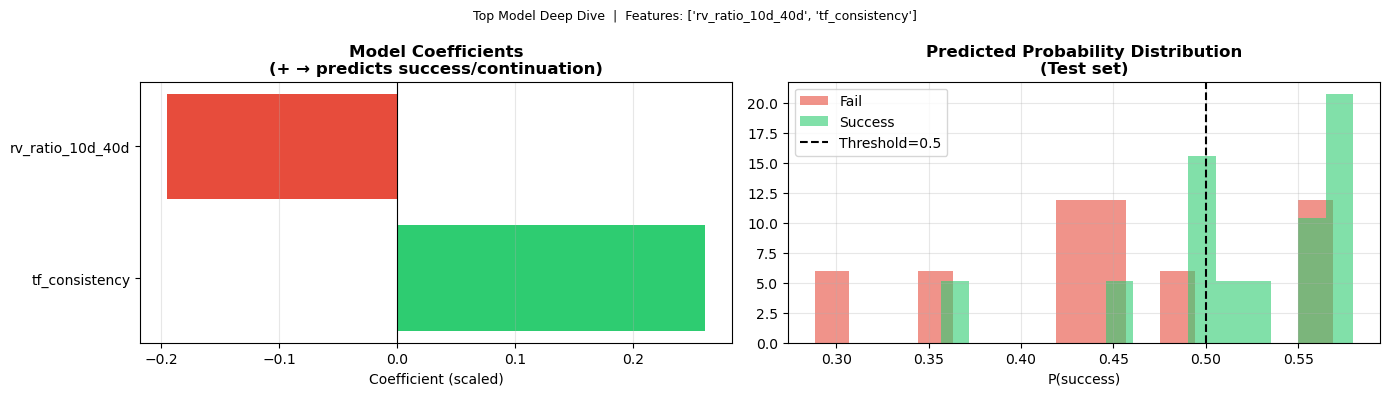


  Coefficients (sorted by |coef|):
         feature  coefficient
  tf_consistency     0.261498
rv_ratio_10d_40d    -0.194951


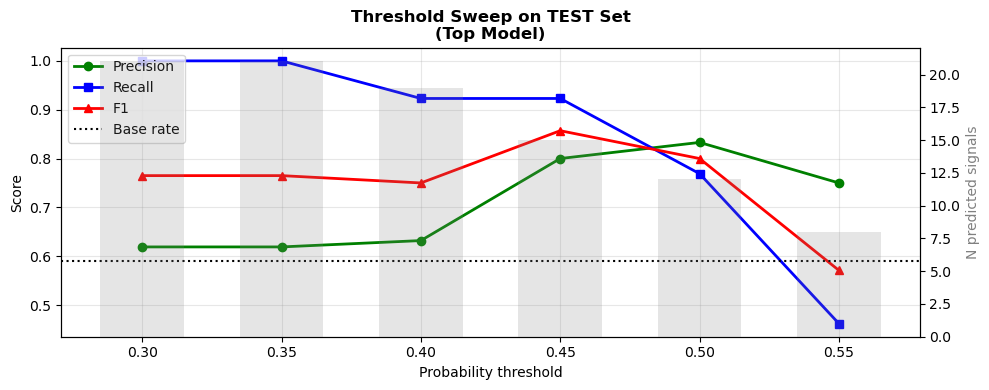


  Threshold Sweep Table (TEST):
 threshold  N_predicted  precision  recall    f1
      0.30           21      0.619   1.000 0.765
      0.35           21      0.619   1.000 0.765
      0.40           19      0.632   0.923 0.750
      0.45           15      0.800   0.923 0.857
      0.50           12      0.833   0.769 0.800
      0.55            8      0.750   0.462 0.571
════════════════════════════════════════════════════════════
BUY vs SELL ABSORPTION SPLIT
════════════════════════════════════════════════════════════

  BUY ABSORPTION  n=35  success=14 (40.0%)  fail=21
           feature  mean_success     mean_fail          diff  ks_stat  p_value
  rv_ratio_10d_40d        0.7352  1.161700e+00 -4.265000e-01    0.667    0.001
 signed_wick_ratio        0.3622 -8.095238e+07  8.095238e+07    0.405    0.105
     lambda_zscore  -455002.5728 -7.967773e+05  3.417747e+05    0.357    0.201
signed_delta_accel      931.5952  1.469714e+03 -5.381190e+02    0.333    0.269
    signed_drift_5       

In [6]:

# ═══════════════════════════════════════════════════════════════════════════════
# CELL 1 — SETUP & IMPORTS
# ═══════════════════════════════════════════════════════════════════════════════

import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, r"C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents")

import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_score, recall_score, f1_score
from itertools import combinations

from market_analysis.config import (
    PRODUCTS, FRONT_N, OHLC_START_DATE, OHLC_END_DATE, ABSORPTION, COMPRESSION
)
from market_analysis.data.ohlc import getData_OHLC_v2, fetch_ohlc_1d, get_ohlc_for_horizon
from market_analysis.utils.contracts import (
    MONTH_CODES, next_n_contract_months, get_front_instruments, fmt_contract
)
from market_analysis.signals.absorption.calculate import calculate_absorption
from market_analysis.signals.absorption.label import label_absorption
from market_analysis.signals.compression.calculate import calculate_compression

# ── Constants ──────────────────────────────────────────────────────────────────
PRODUCT_CODE      = "SM"
TICK_SIZE         = PRODUCTS[PRODUCT_CODE]["tick_size"]          # 0.1
ABS_THRESHOLD     = 0.25    # absorption_strength filter
COMP_THRESHOLD    = 0.30    # compression_score filter
VOLUME_MIN        = 3000    # ignore bars with total volume below this
HORIZONS          = ["1d", "2d", "3d", "5d"]
TODAY             = datetime.date.today()

# Label params (from your best sweep row)
REQUIRED_MOVE_TICKS = 5     # 5 × tick = 0.5 pts
SL_LOOKBACK         = 10
FORWARD_DAYS        = 10

# ── OHLC fetch window per instrument ─────────────────────────────────────────
# Each spread's data starts 7 months before the front-leg's expiry month.
# e.g. SMZ26-SMF27  → front leg = Dec 2026 → start = 2026-05-01
MONTHS_BEFORE_EXPIRY = 7

# ── RV Ratio config ──────────────────────────────────────────────────────────
# All combinations of (numerator_window, denominator_window) will be computed
# as separate features rv_ratio_{N}d_{D}d and each will get its own plot.
# Convention: short_window / long_window  → >1 = vol expanding, <1 = compressing
RV_NUMERATOR_WINDOWS   = [3,4, 5, 10]      # short lookback options (days)
RV_DENOMINATOR_WINDOWS = [15, 20, 40]    # long  lookback options (days)

# ── Kyle Lambda z-score window ───────────────────────────────────────────────
# Rolling window (in bars) used to compute the mean and std of lambda_t
# for the z-score normalisation. Larger = more stable baseline, slower to adapt.
LAMBDA_ZSCORE_WINDOW: int = 20
# ─────────────────────────────────────────────────────────────────────────────

print("✅ Setup complete")
print(f"   Product       : {PRODUCT_CODE}  tick={TICK_SIZE}")
print(f"   Abs threshold : {ABS_THRESHOLD}   Comp threshold: {COMP_THRESHOLD}")
print(f"   Volume filter : >{VOLUME_MIN}    Forward days: {FORWARD_DAYS}")
print(f"   Today         : {TODAY}")
print(f"   Fetch window  : {MONTHS_BEFORE_EXPIRY} months before front-leg expiry")
print(f"   RV numerators : {RV_NUMERATOR_WINDOWS}")
print(f"   RV denominators: {RV_DENOMINATOR_WINDOWS}")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 2 — INSTRUMENT SELECTION (front 4 + recently expired spreads)
# ═══════════════════════════════════════════════════════════════════════════════

def get_expired_spreads(product_code: str, n_expired: int = 3) -> list[str]:
    """
    Return the last `n_expired` calendar-consecutive spread pairs that expired
    before today. Uses the same traded_months list from config.
    """
    product  = PRODUCTS[product_code]
    traded   = sorted(product["traded_months"])
    prefix   = product["api_prefix"]

    # walk backwards from today to collect recent contract months
    y, m     = TODAY.year, TODAY.month
    collected = []
    while len(collected) < n_expired + 4:   # collect extra buffer
        m -= 1
        if m < 1:
            m = 12; y -= 1
        if m in traded:
            collected.append((y, m))

    collected.reverse()   # chronological order

    pairs = []
    for i in range(len(collected) - 1):
        front = fmt_contract(prefix, *collected[i])
        back  = fmt_contract(prefix, *collected[i + 1])
        pairs.append(f"{front}-{back}")

    # take the most recent n_expired pairs
    return pairs[-n_expired:]


def instr_fetch_start(instrument: str, months_before: int = MONTHS_BEFORE_EXPIRY) -> str:
    """
    Derive the OHLC fetch start date for a spread instrument.

    Logic: parse the front-leg contract → find its expiry month (year, month)
           → subtract `months_before` calendar months → return "YYYY-MM-01".

    Example:
        "SMZ26-SMF27"  → front leg SMZ26 → Dec 2026
                       → 7 months before Dec = May 2026
                       → start = "2026-05-01"
    """
    import re
    # Reverse MONTH_CODES so we can go from letter → month number
    CODE_TO_MONTH = {v: k for k, v in MONTH_CODES.items()}

    front_leg = instrument.split("-")[0]          # e.g. "SMZ26"
    m_obj     = re.match(r"^[A-Za-z]+([A-Z])(\d{2})$", front_leg)
    if not m_obj:
        # Fallback: use global OHLC_START_DATE if we can't parse
        return OHLC_START_DATE

    month_code = m_obj.group(1)                   # e.g. "Z"
    year_2dig  = int(m_obj.group(2))              # e.g. 26
    year       = 2000 + year_2dig                 # e.g. 2026
    month      = CODE_TO_MONTH.get(month_code, 1) # e.g. 12 (December)

    # subtract months_before months
    start_month = month - months_before
    start_year  = year
    while start_month < 1:
        start_month += 12
        start_year  -= 1

    return f"{start_year}-{start_month:02d}-01"


# Front 4 spreads starting from today
front_4 = get_front_instruments(PRODUCT_CODE, "spread",
                                reference_date=TODAY, front_n=4)

# ~3 recently expired spreads for extra data
expired_3 = get_expired_spreads(PRODUCT_CODE, n_expired=3)

ALL_INSTRUMENTS = expired_3 + front_4

print("═" * 60)
print("INSTRUMENTS SELECTED")
print("═" * 60)
print(f"  Expired spreads : {expired_3}")
print(f"  Front 4 spreads : {front_4}")
print(f"  Total           : {len(ALL_INSTRUMENTS)} instruments")
print()
print("  Derived fetch windows (7 months before front-leg expiry):")
for instr in ALL_INSTRUMENTS:
    print(f"    {instr:22s}  start={instr_fetch_start(instr)}")
print("═" * 60)


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 3 — FETCH, SCORE (absorption + compression) FOR ALL INSTRUMENTS
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("FETCHING & SCORING OHLC DATA")
print("═" * 60)

# Store per-instrument scored 1D DataFrames (before aggregation)
scored_1d = {}      # {instrument: df_with_absorption_1d}
scored_nd = {}      # {instrument: {horizon: df}}

for instr in ALL_INSTRUMENTS:
    print(f"\n  ▸ {instr}")

    # Per-instrument fetch window: 7 months before front-leg expiry
    instr_start = instr_fetch_start(instr)
    print(f"    fetch_start={instr_start}")

    # --- 1D fetch & absorption score ---
    df1d = fetch_ohlc_1d(instr, PRODUCT_CODE, getData_OHLC_v2,
                          start_date=instr_start, end_date=OHLC_END_DATE)
    if df1d is None or len(df1d) < 70:
        print(f"    [SKIP] not enough data (rows={len(df1d) if df1d is not None else 0})")
        continue

    df1d_abs  = calculate_absorption(df1d, window=60,
                                      tick_size=TICK_SIZE, strength_threshold=ABS_THRESHOLD)
    df1d_abs  = label_absorption(df1d_abs, tick=TICK_SIZE,
                                  required_move_ticks=REQUIRED_MOVE_TICKS,
                                  sl_lookback=SL_LOOKBACK,
                                  forward_days=FORWARD_DAYS)
    scored_1d[instr] = df1d_abs

    # --- compression on 1D ---
    df1d_comp, _ = calculate_compression(df1d.copy(),
                                          compression_threshold=COMP_THRESHOLD)

    # merge compression_score into absorption df by Date
    comp_merge = df1d_comp[["Date", "compression_score"]].copy()
    comp_merge["Date"] = pd.to_datetime(comp_merge["Date"]).dt.strftime("%Y-%m-%d")
    df1d_abs["Date"]   = pd.to_datetime(df1d_abs["Date"]).dt.strftime("%Y-%m-%d")
    df1d_abs = df1d_abs.merge(comp_merge.rename(columns={"compression_score": "comp_score_1d"}),
                               on="Date", how="left")
    scored_1d[instr] = df1d_abs

    # --- multi-horizon absorption scores (for consistency feature) ---
    scored_nd[instr] = {}
    for hz in HORIZONS:
        from market_analysis.data.ohlc import _aggregate_trailing
        from market_analysis.config import HORIZON_BARS
        n_bars = HORIZON_BARS[hz]
        dfh    = df1d.copy() if n_bars == 1 else _aggregate_trailing(df1d.copy(), n_bars)
        if dfh is None or len(dfh) < 65:
            continue
        dfh_sc = calculate_absorption(dfh, window=60,
                                       tick_size=TICK_SIZE, strength_threshold=ABS_THRESHOLD)
        scored_nd[instr][hz] = dfh_sc
    print(f"    rows={len(df1d_abs)}  "
          f"abs_events={(df1d_abs['absorption_strength'] > ABS_THRESHOLD).sum()}")

print("\n✅ Scoring complete")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 4 — FEATURE ENGINEERING
# (all past-only, no forward leakage, computed at bar t)
# ═══════════════════════════════════════════════════════════════════════════════

def build_resolution_features(df: pd.DataFrame,
                                scored_nd_for_instr: dict,
                                tick: float = 0.1,
                                epsilon: float = 1e-9) -> pd.DataFrame:
    """
    Add Stage-2 characterization features to a scored+labeled 1D DataFrame.
    All features use only [t-N : t] — strictly past-only.
    """
    d = df.copy().sort_values("Date").reset_index(drop=True)

    # ── 1. Intrabar: close position within bar ──────────────────────────────
    d["close_pos"] = (d["close"] - d["low"]) / (d["high"] - d["low"] + epsilon)
    # Signed for direction:
    #   BUY  absorption → reversal = price drops → close near LOW is BAD for buyers
    #     close_pos LOW (< 0.3) → sellers won intrabar → reversal hint → signed negative
    #   SELL absorption → reversal = price rises → close near HIGH is BAD for sellers
    # Convention: signed_close_pos > 0 → continuation, < 0 → reversal
    d["signed_close_pos"] = np.where(
        d["absorption_direction"] == "BUY",
        d["close_pos"] - 0.5,          # BUY: high → continuation (+), low → reversal (-)
        0.5 - d["close_pos"],          # SELL: low → continuation (+), high → reversal (-)
    )

    # ── 2. Intrabar: wick asymmetry ──────────────────────────────────────────
    d["upper_wick"] = d["high"] - d[["open", "close"]].max(axis=1)
    d["lower_wick"] = d[["open", "close"]].min(axis=1) - d["low"]
    d["wick_ratio"] = d["upper_wick"] / (d["lower_wick"] + epsilon)
    # BUY absorption: large upper wick → price pushed up but rejected → reversal
    # SELL absorption: large lower wick → price tested down but rejected → reversal
    # Sign: negative → reversal hint
    d["signed_wick_ratio"] = np.where(
        d["absorption_direction"] == "BUY",
        -(d["wick_ratio"] - 1.0),       # BUY: wick_ratio >> 1 → reversal → negative
        (d["wick_ratio"] - 1.0),        # SELL: wick_ratio << 1 → reversal → positive issue
    )
    # simpler: just keep raw wick_ratio and let model learn direction via dir dummy

    # ── 3. Delta ratio (how one-sided) ───────────────────────────────────────
    d["delta_ratio"] = d["buyvolume"] / (d["sellvolume"] + epsilon)

    # ── 4. Delta momentum: is aggressive flow accel or dying? ────────────────
    d["delta_accel"] = d["delta"] - d["delta"].shift(1).rolling(3, min_periods=1).mean()
    # Sign to success: BUY absorption — if delta_accel positive → buyers not exhausted → continuation
    # SELL absorption — if delta_accel negative (sell delta growing) → sellers not exhausted → continuation
    d["signed_delta_accel"] = np.where(
        d["absorption_direction"] == "BUY",
        d["delta_accel"],
        -d["delta_accel"],
    )

    # ── 5. Volume deceleration ───────────────────────────────────────────────
    vol_roll5 = d["volume"].shift(1).rolling(5, min_periods=2).mean()
    d["vol_ratio"] = d["volume"] / (vol_roll5 + epsilon)
    # vol_ratio < 1 → volume drying up → exhaustion → reversal (negative for our sign)
    # signed: positive → continuation hint
    d["signed_vol_ratio"] = d["vol_ratio"] - 1.0   # >0 = escalating, <0 = dying

    # ── 6. Price drift into absorption ───────────────────────────────────────
    d["drift_5"] = (d["close"] - d["close"].shift(5)) / (5 * tick + epsilon)
    # BUY absorption after falling prices (drift_5 < 0) → counter-trend buyers → reversal likely
    # SELL absorption after rising prices (drift_5 > 0) → counter-trend sellers → reversal likely
    # Sign: same direction as absorption = continuation, opposite = reversal
    d["signed_drift_5"] = np.where(
        d["absorption_direction"] == "BUY",
        d["drift_5"],          # rising drift + BUY absorption → continuation
        -d["drift_5"],         # falling drift + SELL absorption → continuation
    )

    # ── 7. Kyle Lambda: market depth anomaly ─────────────────────────────────
    price_change = d["close"].diff().abs()
    abs_delta    = d["delta"].abs()
    d["lambda_t"]     = price_change / (abs_delta + epsilon)
    d["lambda_5_avg"] = d["lambda_t"].shift(1).rolling(5, min_periods=2).mean()
    d["lambda_ratio"] = d["lambda_t"] / (d["lambda_5_avg"] + epsilon)
    _lam_mp    = max(10, LAMBDA_ZSCORE_WINDOW // 3)   # min_periods = 1/3 of window
    lam_mean   = d["lambda_t"].shift(1).rolling(LAMBDA_ZSCORE_WINDOW, min_periods=_lam_mp).mean()
    lam_std    = d["lambda_t"].shift(1).rolling(LAMBDA_ZSCORE_WINDOW, min_periods=_lam_mp).std()
    d["lambda_zscore"] = (d["lambda_t"] - lam_mean) / (lam_std + epsilon)
    # very negative lambda_zscore = unusually deep market = strong absorption event
    # (window controlled by LAMBDA_ZSCORE_WINDOW in Cell 1)

    # ── 8. Realized volatility ratios (all configured combinations) ──────────
    # Config lists RV_NUMERATOR_WINDOWS and RV_DENOMINATOR_WINDOWS (defined in Cell 1).
    # For each (num_w, den_w) pair where num_w < den_w we compute:
    #   rv_ratio_{num_w}d_{den_w}d = rv(num_w) / rv(den_w)
    # >1 = vol expanding (short > long)  |  <1 = vol compressing
    log_ret = np.log(d["close"].replace(0, np.nan) / d["close"].shift(1).replace(0, np.nan))

    # Pre-compute each unique window std once
    all_windows = sorted(set(RV_NUMERATOR_WINDOWS + RV_DENOMINATOR_WINDOWS))
    rv_cache = {}
    for w in all_windows:
        mp = max(2, w // 2)
        rv_cache[w] = log_ret.rolling(w, min_periods=mp).std()

    for num_w in RV_NUMERATOR_WINDOWS:
        for den_w in RV_DENOMINATOR_WINDOWS:
            if num_w >= den_w:
                continue   # skip: numerator must be shorter than denominator
            col = f"rv_ratio_{num_w}d_{den_w}d"
            d[col] = rv_cache[num_w] / (rv_cache[den_w] + epsilon)

    # Keep the original rv_ratio name pointing at the first valid combo
    # so downstream code that references "rv_ratio" still works
    _first_num = next((n for n in RV_NUMERATOR_WINDOWS for den in RV_DENOMINATOR_WINDOWS if n < den), None)
    _first_den = next((den for n in RV_NUMERATOR_WINDOWS for den in RV_DENOMINATOR_WINDOWS if n < den), None)
    if _first_num is not None:
        d["rv_ratio"] = d[f"rv_ratio_{_first_num}d_{_first_den}d"]
    # rv_ratio > 1 → short-window vol > long-window vol → expanding (high-vol regime)
    # rv_ratio < 1 → short-window vol < long-window vol → compressing (quiet)

    # ── 9. Multi-timeframe consistency ───────────────────────────────────────
    # For each bar date, check if absorption_strength > ABS_THRESHOLD on other horizons
    d["Date_str"] = pd.to_datetime(d["Date"]).dt.strftime("%Y-%m-%d")
    tf_scores = {hz: {} for hz in HORIZONS}
    for hz, dfh in scored_nd_for_instr.items():
        if dfh is None or "absorption_strength" not in dfh.columns:
            continue
        dfh_copy = dfh.copy()
        dfh_copy["Date_str"] = pd.to_datetime(dfh_copy["Date"]).dt.strftime("%Y-%m-%d")
        for _, row in dfh_copy.iterrows():
            tf_scores[hz][row["Date_str"]] = row["absorption_strength"]

    consistency_vals = []
    for _, row in d.iterrows():
        date_key = row["Date_str"]
        fires = [
            1 if tf_scores[hz].get(date_key, 0) > ABS_THRESHOLD else 0
            for hz in HORIZONS
        ]
        consistency_vals.append(np.mean(fires))
    d["tf_consistency"] = consistency_vals

    # ── 10. Dual signal: both absorption AND compression fire ─────────────────
    d["dual_signal"] = (
        (d["absorption_strength"] > ABS_THRESHOLD) &
        (d.get("comp_score_1d", pd.Series(0, index=d.index)).fillna(0) > COMP_THRESHOLD)
    ).astype(float)

    # ── 11. Direction dummy (BUY=1, SELL=0) ──────────────────────────────────
    d["is_buy_absorption"] = (d["absorption_direction"] == "BUY").astype(float)

    return d


# Apply feature engineering to all instruments
print("═" * 60)
print("FEATURE ENGINEERING")
print("═" * 60)

featured = {}
for instr, df in scored_1d.items():
    nd_for_instr = scored_nd.get(instr, {})
    featured[instr] = build_resolution_features(df, nd_for_instr, tick=TICK_SIZE)
    print(f"  ✓ {instr}  columns={len(featured[instr].columns)}")

print("✅ Feature engineering complete")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 5 — POOL ABSORPTION EVENTS & SUMMARY
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("POOLING ABSORPTION EVENTS (volume > 3000, strength > 0.25)")
print("═" * 60)

FEATURE_COLS = [
    "signed_close_pos",
    "signed_wick_ratio",
    "signed_delta_accel",
    "signed_vol_ratio",
    "signed_drift_5",
    "lambda_zscore",
    "rv_ratio",
    "tf_consistency",
    "dual_signal",
    "is_buy_absorption",
    # raw (unsigned) versions also included for exploration
    "close_pos",
    "wick_ratio",
    "vol_ratio",
    "delta_ratio",
    "lambda_ratio",
]

all_events = []
for instr, df in featured.items():
    mask = (
        (df["absorption_strength"] > ABS_THRESHOLD) &
        (df["volume"] > VOLUME_MIN) &
        (df["sl_success"].notna())
    )
    subset = df[mask].copy()
    subset["instrument"] = instr
    all_events.append(subset)

if not all_events:
    print("❌ No events found — check thresholds or data fetch")
else:
    pool = pd.concat(all_events, ignore_index=True)
    pool = pool.sort_values("Date").reset_index(drop=True)

    n_total   = len(pool)
    n_success = int(pool["sl_success"].sum())
    n_fail    = int((pool["sl_success"] == 0).sum())
    base_rate = n_success / n_total if n_total > 0 else 0

    print(f"\n  Total absorption events : {n_total}")
    print(f"  Success (reversal)      : {n_success}  ({100*base_rate:.1f}%)")
    print(f"  Failure                 : {n_fail}")
    print(f"\n  Per instrument:")
    for instr in pool["instrument"].unique():
        sub = pool[pool["instrument"] == instr]
        s = int(sub["sl_success"].sum())
        print(f"    {instr:20s}  n={len(sub):3d}  success={s}")
    print()

    # ensure features are numeric
    for fc in FEATURE_COLS:
        if fc in pool.columns:
            pool[fc] = pd.to_numeric(pool[fc], errors="coerce")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 6 — DISTRIBUTION PLOTS: Feature separation (success vs fail)
# ═══════════════════════════════════════════════════════════════════════════════

# ── Helper: plot a set of features and return separation stats ────────────────
def _plot_feature_grid(pool_df, feature_list, title_prefix=""):
    """
    Plots histograms for each (feat, label) tuple in feature_list.
    Returns a list of separation stat dicts.
    """
    suc = pool_df[pool_df["sl_success"] == 1]
    fai = pool_df[pool_df["sl_success"] == 0]
    stats_out = []

    n_cols = 3
    n_rows = (len(feature_list) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3.5))
    axes = axes.flatten()

    for ax, (feat, label) in zip(axes, feature_list):
        if feat not in pool_df.columns:
            ax.set_visible(False); continue
        s_vals = suc[feat].dropna()
        f_vals = fai[feat].dropna()
        if len(s_vals) == 0 or len(f_vals) == 0:
            ax.set_visible(False); continue

        ax.hist(f_vals, bins=20, alpha=0.5, color="#e74c3c", density=True,
                label=f"Fail (n={len(f_vals)})")
        ax.hist(s_vals, bins=20, alpha=0.5, color="#2ecc71", density=True,
                label=f"Success (n={len(s_vals)})")
        ks_stat, ks_pval = stats.ks_2samp(s_vals, f_vals)
        mean_diff = s_vals.mean() - f_vals.mean()
        ax.set_title(label, fontsize=9, fontweight="bold")
        ax.set_xlabel(f"KS={ks_stat:.2f}  p={ks_pval:.3f}  Δmean={mean_diff:+.3f}", fontsize=8)
        ax.legend(fontsize=7); ax.grid(alpha=0.3)
        stats_out.append({"feature": feat, "ks_stat": ks_stat, "ks_pval": ks_pval,
                           "mean_success": s_vals.mean(), "mean_fail": f_vals.mean(),
                           "mean_diff": mean_diff})

    for ax in axes[len(feature_list):]:
        ax.set_visible(False)
    plt.suptitle(f"{title_prefix}\n"
                 f"(Abs≥{ABS_THRESHOLD}, Vol>{VOLUME_MIN}, "
                 f"n={n_total}, base={base_rate:.1%})",
                 fontsize=10, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()
    return stats_out


# ── Section A: core signed features ──────────────────────────────────────────
CORE_PLOT_FEATURES = [
    ("signed_close_pos",   "Signed Close Position\n(+→ continuation, -→ reversal)"),
    ("signed_wick_ratio",  "Signed Wick Ratio\n(+→ continuation, -→ reversal)"),
    ("signed_delta_accel", "Signed Delta Accel\n(+→ flow accel, -→ flow dying)"),
    ("signed_vol_ratio",   "Signed Vol Ratio\n(+→ vol escalating, -→ vol dying)"),
    ("signed_drift_5",     "Signed 5-Day Drift\n(+→ with trend, -→ counter trend)"),
    ("lambda_zscore",      "Kyle Lambda Z-Score\n(- = unusually deep market)"),
    ("tf_consistency",     "Multi-TF Consistency\n(fraction of HZs that fire)"),
    ("dual_signal",        "Dual Signal\n(Abs + Compression both fire)"),
]

print("═" * 60)
print("SECTION A — CORE FEATURE SEPARATION (success vs failure)")
print("═" * 60)
sep_stats = _plot_feature_grid(pool, CORE_PLOT_FEATURES,
                                title_prefix="Core Features: Success vs Failure")

sep_df = pd.DataFrame(sep_stats).sort_values("ks_stat", ascending=False)
print("\nCore Feature Separation (KS test, sorted by KS stat):")
print(sep_df[["feature", "ks_stat", "ks_pval", "mean_success", "mean_fail", "mean_diff"]].to_string(index=False))


# ── Section B: RV Ratio — all window combinations ────────────────────────────
print()
print("═" * 60)
print("SECTION B — RV RATIO COMBINATIONS (all num/den window pairs)")
print(f"  Numerator  windows: {RV_NUMERATOR_WINDOWS}")
print(f"  Denominator windows: {RV_DENOMINATOR_WINDOWS}")
print("═" * 60)

RV_PLOT_FEATURES = []
for num_w in RV_NUMERATOR_WINDOWS:
    for den_w in RV_DENOMINATOR_WINDOWS:
        if num_w >= den_w:
            continue
        col   = f"rv_ratio_{num_w}d_{den_w}d"
        label = (f"RV Ratio {num_w}d / {den_w}d\n"
                 f"(>1=vol expanding, <1=compressing)")
        RV_PLOT_FEATURES.append((col, label))

if RV_PLOT_FEATURES:
    rv_sep_stats = _plot_feature_grid(pool, RV_PLOT_FEATURES,
                                       title_prefix="RV Ratio Combinations: Success vs Failure")
    rv_sep_df = pd.DataFrame(rv_sep_stats).sort_values("ks_stat", ascending=False)
    print("\nRV Ratio Separation (KS test, sorted by KS stat):")
    print(rv_sep_df[["feature", "ks_stat", "ks_pval",
                     "mean_success", "mean_fail", "mean_diff"]].to_string(index=False))
    print(f"\n  → Best RV combo: {rv_sep_df.iloc[0]['feature']}  "
          f"KS={rv_sep_df.iloc[0]['ks_stat']:.3f}")
    # Store best for use in model sweep
    BEST_RV_FEATURE = rv_sep_df.iloc[0]["feature"]
else:
    print("  No valid RV combos (all numerators >= denominators). Check config.")
    BEST_RV_FEATURE = "rv_ratio"

# Combined separation table (all features)
all_sep_df = pd.concat([sep_df, rv_sep_df if RV_PLOT_FEATURES else pd.DataFrame()],
                        ignore_index=True).sort_values("ks_stat", ascending=False)
print("\n── ALL FEATURES combined (sorted by KS stat) ──")
print(all_sep_df[["feature", "ks_stat", "ks_pval", "mean_diff"]].to_string(index=False))
success_events = pool[pool["sl_success"] == 1]
fail_events    = pool[pool["sl_success"] == 0]


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 7 — WALK-FORWARD TRAIN / TEST SPLIT
# ═══════════════════════════════════════════════════════════════════════════════

pool_sorted = pool.sort_values("Date").reset_index(drop=True)
split_idx   = int(len(pool_sorted) * 0.70)
train_df    = pool_sorted.iloc[:split_idx].copy()
test_df     = pool_sorted.iloc[split_idx:].copy()

print("═" * 60)
print("WALK-FORWARD SPLIT")
print("═" * 60)
print(f"  Train: {len(train_df)} events | {train_df['Date'].min()} → {train_df['Date'].max()}")
print(f"  Test : {len(test_df)} events  | {test_df['Date'].min()} → {test_df['Date'].max()}")
print(f"  Train base rate: {train_df['sl_success'].mean():.1%}")
print(f"  Test  base rate: {test_df['sl_success'].mean():.1%}")


def get_Xy(df: pd.DataFrame, feats: list[str]):
    """Extract X, y matrices from a pool DataFrame, dropping NaN rows."""
    sub  = df[feats + ["sl_success"]].dropna()
    X    = sub[feats].values.astype(float)
    y    = sub["sl_success"].values.astype(int)
    return X, y, sub.index


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 8 — FEATURE COMBO SWEEP (SGD Logistic Regression)
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("FEATURE COMBINATION SWEEP (SGD Logistic Regression)")
print("═" * 60)

# Signed feature candidates (theoretically motivated).
# rv_ratio is replaced by the best-KS combo found in Cell 6 Section B.
SIGNED_FEATS = [
    "signed_close_pos",
    "signed_delta_accel",
    "signed_vol_ratio",
    "signed_drift_5",
    "lambda_zscore",
    BEST_RV_FEATURE,       # best RV window combo by KS separation
    "tf_consistency",
    "signed_wick_ratio",
]

# Filter to only features that exist and have enough variance
available_feats = [
    f for f in SIGNED_FEATS
    if f in train_df.columns and train_df[f].dropna().std() > 1e-6
]
print(f"  Available features: {available_feats}\n")

# Combos of size 2–6 (theoretically motivated pairs first, then expand)
# Plus one full-feature model
combo_sizes = [2, 3, 4, 5]
combos      = []
for size in combo_sizes:
    combos.extend(list(combinations(available_feats, size)))
# Add full model
combos.append(tuple(available_feats))

print(f"  Total combos to evaluate: {len(combos)}")

def make_sgd_pipeline():
    clf = SGDClassifier(
        loss="log_loss",
        penalty="l2",
        alpha=0.01,
        max_iter=1000,
        tol=1e-4,
        random_state=42,
        class_weight="balanced",
    )
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])


results = []
for combo in combos:
    feats = list(combo)
    X_tr, y_tr, _ = get_Xy(train_df, feats)
    X_te, y_te, _ = get_Xy(test_df,  feats)

    if len(X_tr) < 20 or len(X_te) < 5:
        continue
    if len(np.unique(y_tr)) < 2 or len(np.unique(y_te)) < 2:
        continue

    pipe = make_sgd_pipeline()
    try:
        pipe.fit(X_tr, y_tr)
    except Exception:
        continue

    y_pred_prob = pipe.predict_proba(X_te)[:, 1]
    # Use 0.5 as default threshold
    y_pred = (y_pred_prob >= 0.5).astype(int)

    prec   = precision_score(y_te, y_pred, zero_division=0)
    rec    = recall_score(y_te,    y_pred, zero_division=0)
    f1     = f1_score(y_te,        y_pred, zero_division=0)
    # Lift over base rate
    base   = y_te.mean() if y_te.mean() > 0 else 1e-9
    lift   = prec / base

    results.append({
        "features"  : feats,
        "n_feats"   : len(feats),
        "precision" : round(prec, 4),
        "recall"    : round(rec,  4),
        "f1"        : round(f1,   4),
        "lift"      : round(lift, 4),
        "n_train"   : len(X_tr),
        "n_test"    : len(X_te),
    })

results_df = pd.DataFrame(results).sort_values("precision", ascending=False).reset_index(drop=True)

print("\n  Top 15 combos by Precision on TEST set:")
print("─" * 80)
for i, row in results_df.head(15).iterrows():
    print(f"  [{i+1:2d}] n_feats={row['n_feats']}  "
          f"P={row['precision']:.3f}  R={row['recall']:.3f}  "
          f"F1={row['f1']:.3f}  Lift={row['lift']:.2f}")
    print(f"       features: {row['features']}")

print(f"\n  Base rate on test: {test_df['sl_success'].mean():.1%}")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 9 — TOP MODEL DEEP DIVE (threshold sweep + coefficients)
# ═══════════════════════════════════════════════════════════════════════════════

# Pick top combo by precision
best_row   = results_df.iloc[0]
best_feats = best_row["features"]
print("═" * 60)
print(f"TOP MODEL ANALYSIS")
print("═" * 60)
print(f"  Features: {best_feats}")
print(f"  Train n={best_row['n_train']}  Test n={best_row['n_test']}")
print(f"  Precision={best_row['precision']:.3f}  Recall={best_row['recall']:.3f}  "
      f"F1={best_row['f1']:.3f}  Lift={best_row['lift']:.2f}")

X_tr, y_tr, _ = get_Xy(train_df, best_feats)
X_te, y_te, _ = get_Xy(test_df,  best_feats)

best_pipe = make_sgd_pipeline()
best_pipe.fit(X_tr, y_tr)
y_prob_te = best_pipe.predict_proba(X_te)[:, 1]

# ── Coefficients ──────────────────────────────────────────────────────────────
coefs = best_pipe.named_steps["clf"].coef_[0]
coef_df = pd.DataFrame({
    "feature": best_feats,
    "coefficient": coefs,
    "abs_coef": np.abs(coefs)
}).sort_values("abs_coef", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Coefficient bar chart
ax = axes[0]
colors = ["#2ecc71" if c > 0 else "#e74c3c" for c in coef_df["coefficient"]]
ax.barh(coef_df["feature"], coef_df["coefficient"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Model Coefficients\n(+ → predicts success/continuation)", fontweight="bold")
ax.set_xlabel("Coefficient (scaled)")
ax.grid(alpha=0.3, axis="x")

# Probability distribution by outcome
ax = axes[1]
ax.hist(y_prob_te[y_te == 0], bins=15, alpha=0.6, color="#e74c3c", density=True, label="Fail")
ax.hist(y_prob_te[y_te == 1], bins=15, alpha=0.6, color="#2ecc71", density=True, label="Success")
ax.axvline(0.5, color="black", linestyle="--", label="Threshold=0.5")
ax.set_title("Predicted Probability Distribution\n(Test set)", fontweight="bold")
ax.set_xlabel("P(success)")
ax.legend()
ax.grid(alpha=0.3)

plt.suptitle(f"Top Model Deep Dive  |  Features: {best_feats}", fontsize=9)
plt.tight_layout()
plt.show()

print("\n  Coefficients (sorted by |coef|):")
print(coef_df[["feature", "coefficient"]].to_string(index=False))


# ── Threshold sweep on test set ───────────────────────────────────────────────
thresholds = np.arange(0.30, 0.85, 0.05)
sweep_rows = []
for t in thresholds:
    y_pred_t = (y_prob_te >= t).astype(int)
    n_pred   = y_pred_t.sum()
    if n_pred == 0:
        continue
    p = precision_score(y_te, y_pred_t, zero_division=0)
    r = recall_score(y_te,    y_pred_t, zero_division=0)
    f = f1_score(y_te,        y_pred_t, zero_division=0)
    sweep_rows.append({"threshold": round(t, 2), "N_predicted": n_pred,
                        "precision": round(p, 3), "recall": round(r, 3), "f1": round(f, 3)})

sweep_res = pd.DataFrame(sweep_rows)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(sweep_res["threshold"], sweep_res["precision"], "g-o", label="Precision", linewidth=2)
ax.plot(sweep_res["threshold"], sweep_res["recall"],    "b-s", label="Recall",    linewidth=2)
ax.plot(sweep_res["threshold"], sweep_res["f1"],        "r-^", label="F1",        linewidth=2)
ax2 = ax.twinx()
ax2.bar(sweep_res["threshold"], sweep_res["N_predicted"], alpha=0.2, color="gray",
        width=0.03, label="N predicted")
ax2.set_ylabel("N predicted signals", color="gray")
ax.axhline(test_df["sl_success"].mean(), color="black", linestyle=":", label=f"Base rate")
ax.set_xlabel("Probability threshold")
ax.set_ylabel("Score")
ax.set_title("Threshold Sweep on TEST Set\n(Top Model)", fontweight="bold")
ax.legend(loc="upper left"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\n  Threshold Sweep Table (TEST):")
print(sweep_res.to_string(index=False))


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 10 — BUY vs SELL ABSORPTION SPLIT ANALYSIS
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("BUY vs SELL ABSORPTION SPLIT")
print("═" * 60)

for direction in ["BUY", "SELL"]:
    sub = pool[pool["absorption_direction"] == direction].copy()
    n   = len(sub)
    if n < 15:
        print(f"  {direction}: too few events ({n}), skipping")
        continue

    s_sub = sub[sub["sl_success"] == 1]
    f_sub = sub[sub["sl_success"] == 0]
    print(f"\n  {direction} ABSORPTION  n={n}  "
          f"success={len(s_sub)} ({100*len(s_sub)/n:.1f}%)  "
          f"fail={len(f_sub)}")

    feat_means = []
    for feat in available_feats:
        if feat not in sub.columns:
            continue
        sv = s_sub[feat].dropna()
        fv = f_sub[feat].dropna()
        if len(sv) < 3 or len(fv) < 3:
            continue
        ks, pv = stats.ks_2samp(sv, fv)
        feat_means.append({
            "feature": feat,
            "mean_success": round(sv.mean(), 4),
            "mean_fail"   : round(fv.mean(), 4),
            "diff"        : round(sv.mean() - fv.mean(), 4),
            "ks_stat"     : round(ks, 3),
            "p_value"     : round(pv, 3),
        })

    feat_means_df = pd.DataFrame(feat_means).sort_values("ks_stat", ascending=False)
    print(feat_means_df.to_string(index=False))

    # Train direction-specific model if enough data
    sub_sorted = sub.sort_values("Date").reset_index(drop=True)
    sp = int(len(sub_sorted) * 0.70)
    tr_d = sub_sorted.iloc[:sp]
    te_d = sub_sorted.iloc[sp:]
    if len(tr_d) < 15 or len(te_d) < 5:
        print(f"  [{direction}] Not enough data for direction model")
        continue

    X_tr_d, y_tr_d, _ = get_Xy(tr_d, best_feats)
    X_te_d, y_te_d, _ = get_Xy(te_d, best_feats)
    if len(np.unique(y_tr_d)) < 2:
        print(f"  [{direction}] Only one class in train, skipping")
        continue

    pipe_d = make_sgd_pipeline()
    pipe_d.fit(X_tr_d, y_tr_d)
    if len(np.unique(y_te_d)) < 2:
        print(f"  [{direction}] Only one class in test set, skipping metrics")
        continue
    y_pred_d = pipe_d.predict(X_te_d)
    print(f"\n  [{direction}] Direction-specific model (same features):")
    print(f"    Precision={precision_score(y_te_d, y_pred_d, zero_division=0):.3f}  "
          f"Recall={recall_score(y_te_d, y_pred_d, zero_division=0):.3f}  "
          f"F1={f1_score(y_te_d, y_pred_d, zero_division=0):.3f}")
    coefs_d = pipe_d.named_steps["clf"].coef_[0]
    print(f"    Coefficients: " +
          "  ".join(f"{f}={c:+.3f}" for f, c in zip(best_feats, coefs_d)))


print("\n" + "═" * 60)
print("ANALYSIS COMPLETE")
print("═" * 60)


# try4

✅ Setup complete
   Product       : SM  tick=0.1
   Abs threshold : 0.25   Comp threshold: 0.3
   Volume filter : >3000    Forward days: 10
   Today         : 2026-09-21
   Fetch window  : 7 months before front-leg expiry
   RV numerators : [3, 4, 5, 10]
   RV denominators: [15, 20, 40]
   Lambda zscore window : 15d
   Lambda ratio  window : 5d
════════════════════════════════════════════════════════════
INSTRUMENTS SELECTED
════════════════════════════════════════════════════════════
  Expired spreads : ['SMH26-SMK26', 'SMK26-SMN26', 'SMN26-SMQ26']
  Front 4 spreads : ['SMV26-SMZ26', 'SMZ26-SMF27', 'SMF27-SMH27', 'SMH27-SMK27']
  Total           : 7 instruments

  Derived fetch windows (7 months before front-leg expiry):
    SMH26-SMK26             start=2025-08-01
    SMK26-SMN26             start=2025-10-01
    SMN26-SMQ26             start=2025-12-01
    SMV26-SMZ26             start=2026-03-01
    SMZ26-SMF27             start=2026-05-01
    SMF27-SMH27             start=2026-06-0

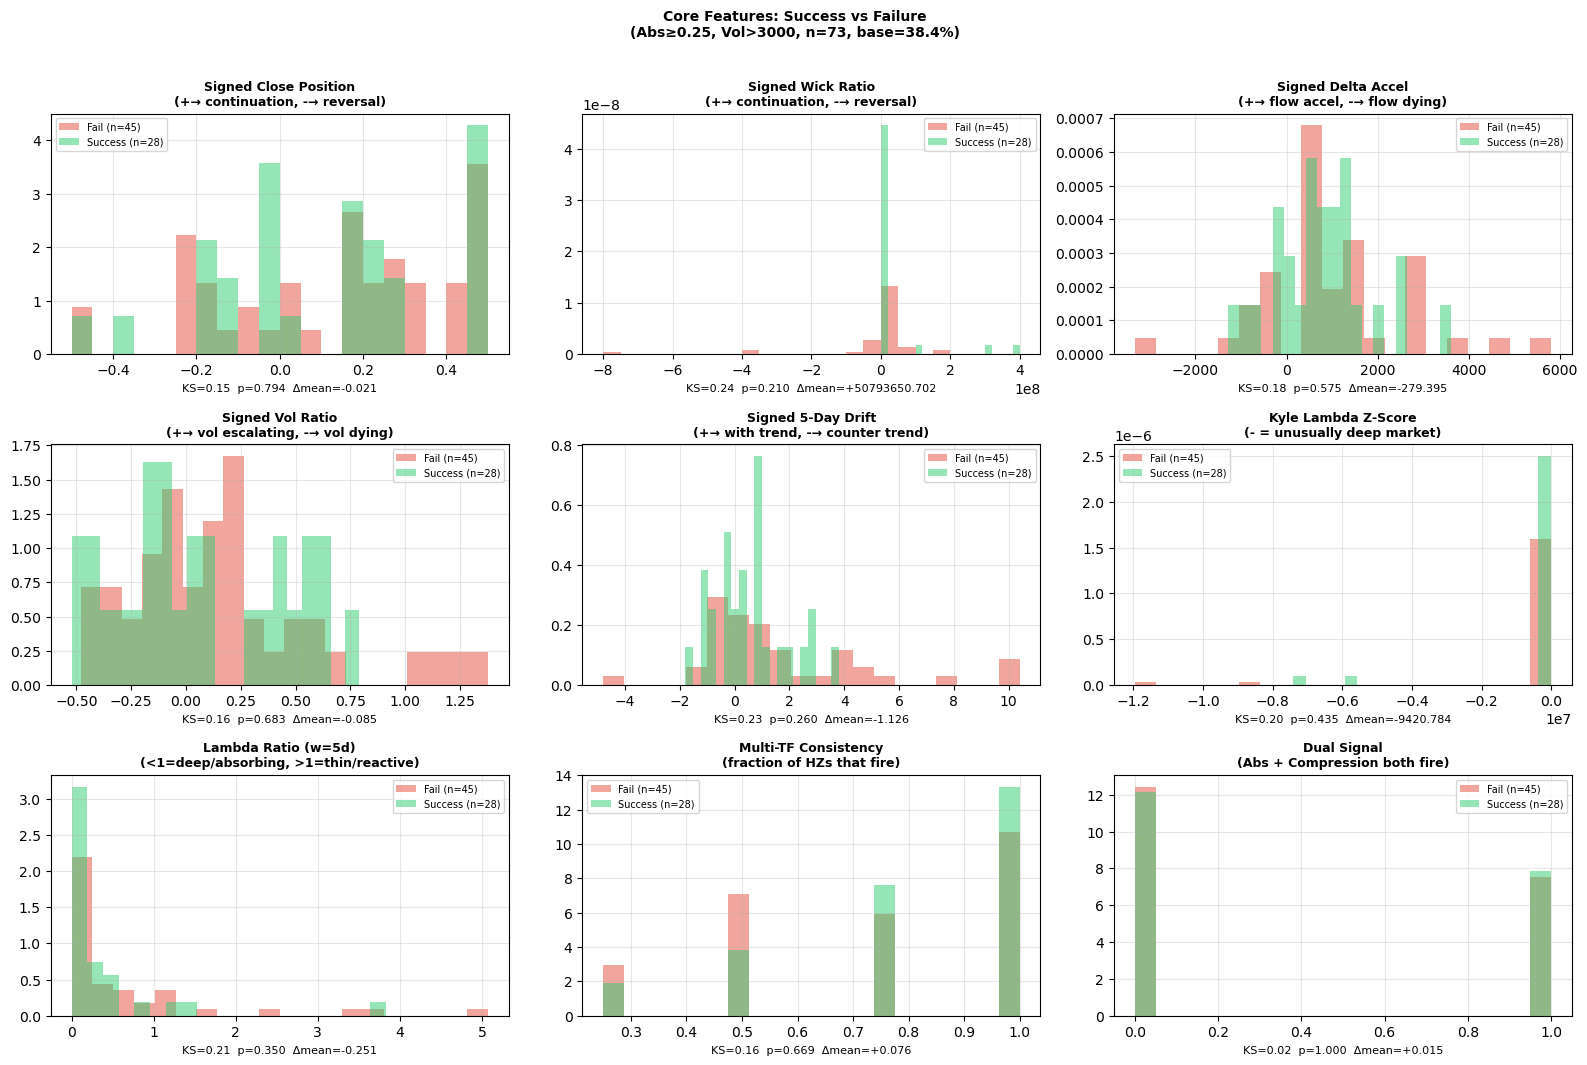


Core Feature Separation (KS test, sorted by KS stat):
           feature  ks_stat  ks_pval  mean_success     mean_fail     mean_diff
 signed_wick_ratio 0.243651 0.210197  2.857143e+07 -2.222222e+07  5.079365e+07
    signed_drift_5 0.230952 0.260435  5.142857e-01  1.640000e+00 -1.125714e+00
      lambda_ratio 0.212698 0.350124  3.808822e-01  6.317125e-01 -2.508303e-01
     lambda_zscore 0.198413 0.435260 -4.690746e+05 -4.596538e+05 -9.420784e+03
signed_delta_accel 0.176984 0.574647  8.004048e+02  1.079800e+03 -2.793952e+02
    tf_consistency 0.163492 0.669021  8.035714e-01  7.277778e-01  7.579365e-02
  signed_vol_ratio 0.161905 0.683091  6.832749e-02  1.531005e-01 -8.477298e-02
  signed_close_pos 0.145238 0.794364  1.164605e-01  1.371944e-01 -2.073389e-02
       dual_signal 0.015079 1.000000  3.928571e-01  3.777778e-01  1.507937e-02

════════════════════════════════════════════════════════════
SECTION B — RV RATIO COMBINATIONS (all num/den window pairs)
  Numerator  windows: [3, 4, 5, 

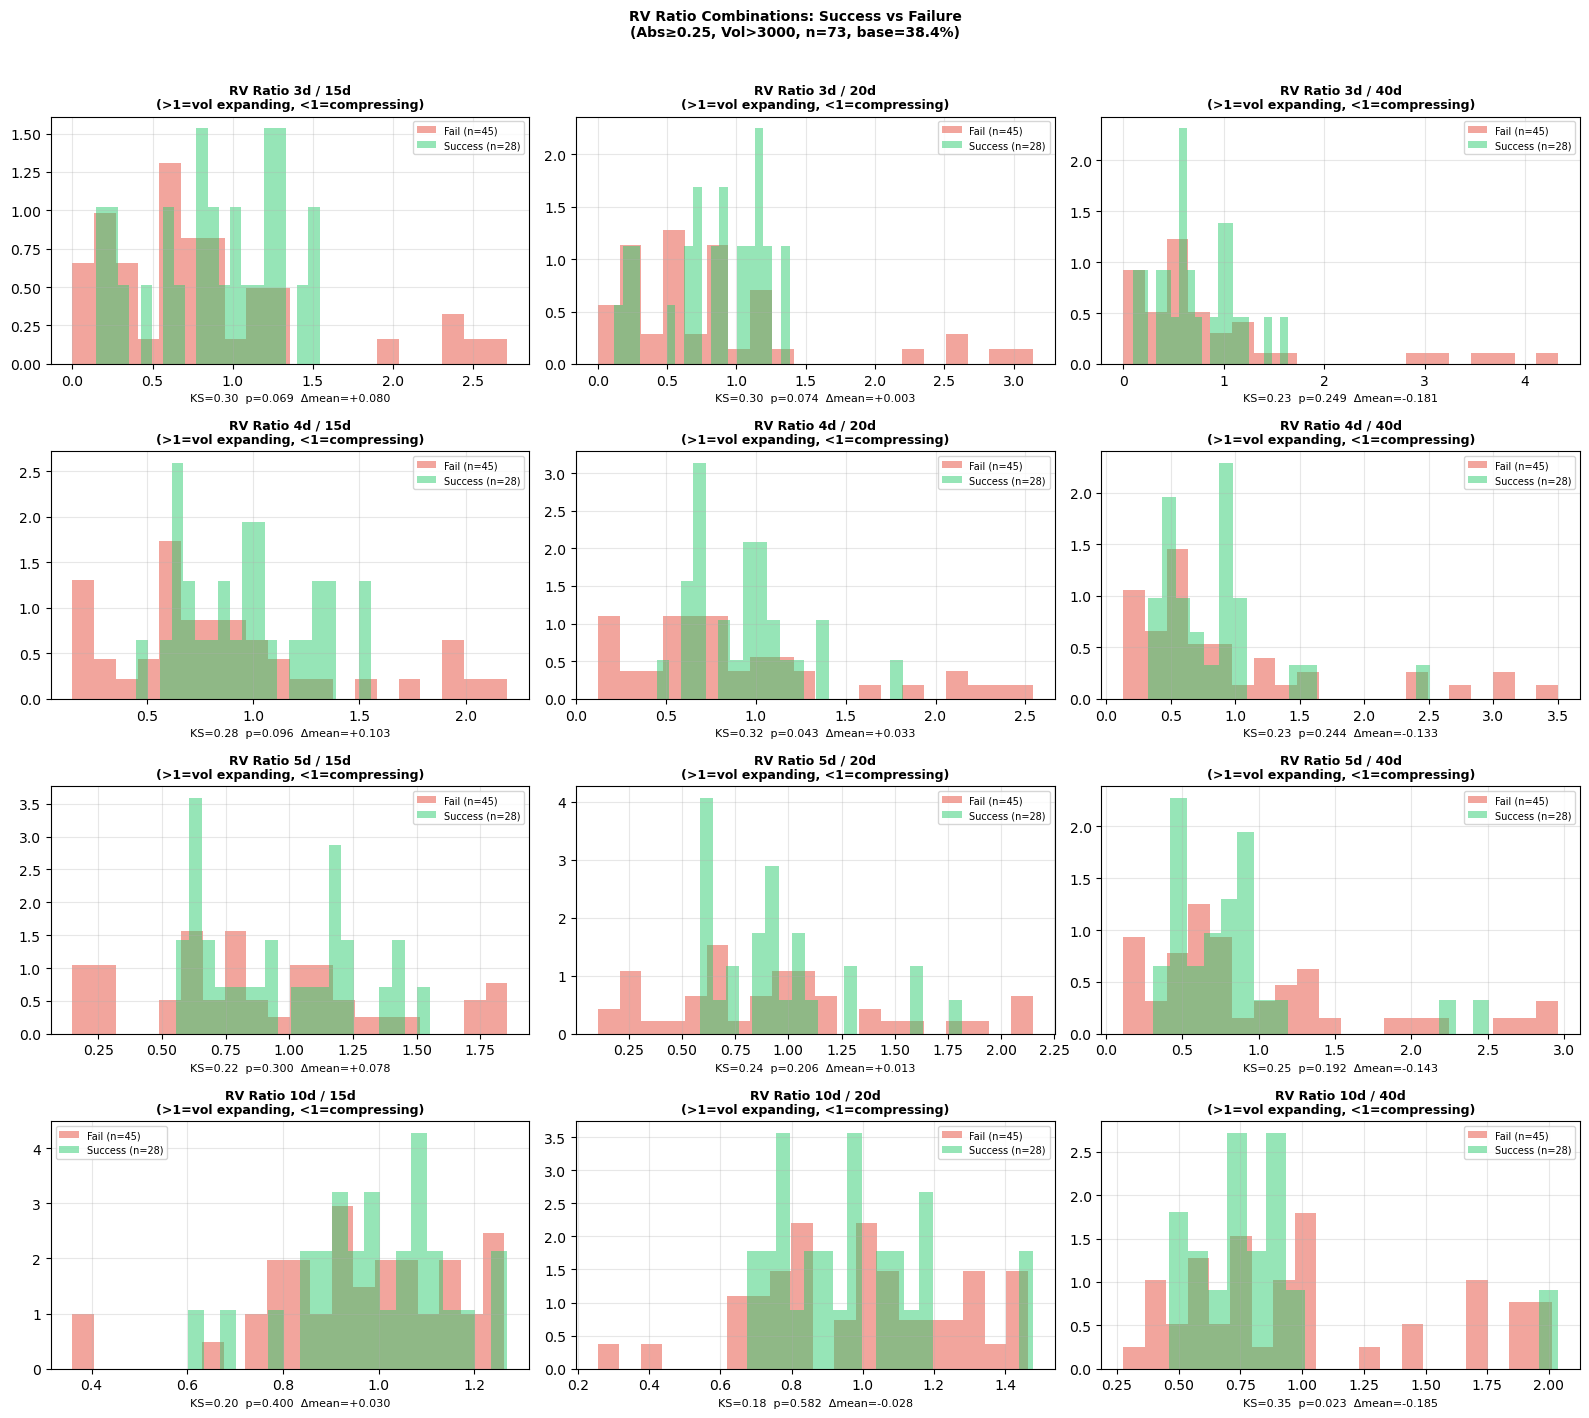


RV Ratio Separation (KS test, sorted by KS stat):
         feature  ks_stat  ks_pval  mean_success  mean_fail  mean_diff
rv_ratio_10d_40d 0.346032 0.022930      0.831765   1.016859  -0.185094
 rv_ratio_4d_20d 0.319841 0.043089      0.933976   0.900866   0.033110
 rv_ratio_3d_15d 0.300794 0.068523      0.888054   0.808493   0.079562
 rv_ratio_3d_20d 0.296825 0.073820      0.845396   0.842451   0.002946
 rv_ratio_4d_15d 0.284127 0.095567      0.969293   0.866314   0.102979
 rv_ratio_5d_40d 0.248413 0.192175      0.824906   0.967466  -0.142559
 rv_ratio_5d_20d 0.244444 0.205683      0.937653   0.924154   0.013499
 rv_ratio_4d_40d 0.234921 0.243850      0.822465   0.955585  -0.133119
 rv_ratio_3d_40d 0.234127 0.249371      0.724713   0.905825  -0.181112
 rv_ratio_5d_15d 0.222222 0.300364      0.966456   0.888927   0.077530
rv_ratio_10d_15d 0.203968 0.399811      0.991008   0.961364   0.029643
rv_ratio_10d_20d 0.176190 0.581922      0.965625   0.993280  -0.027655

  → Best RV combo: rv_rat

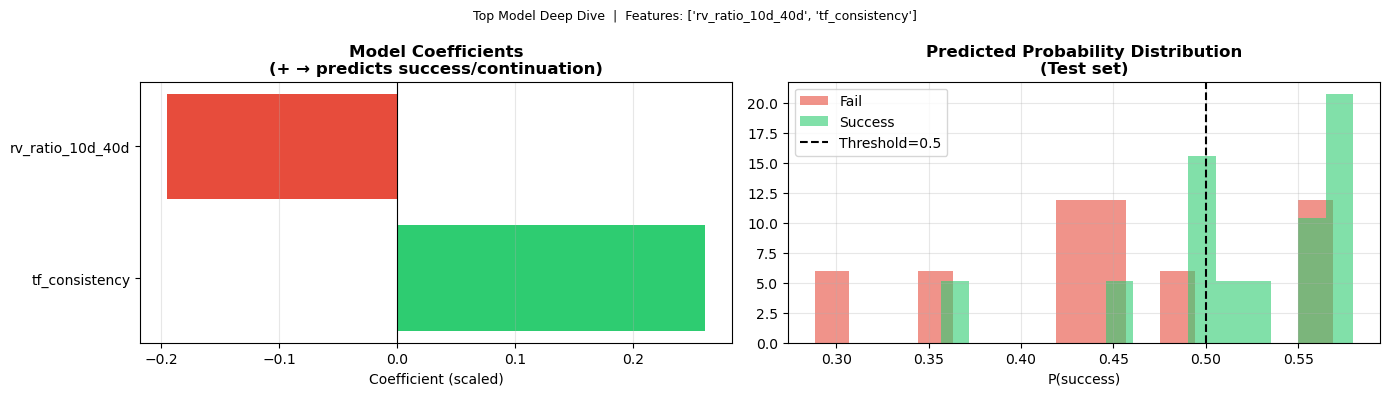


  Coefficients (sorted by |coef|):
         feature  coefficient
  tf_consistency     0.261498
rv_ratio_10d_40d    -0.194951


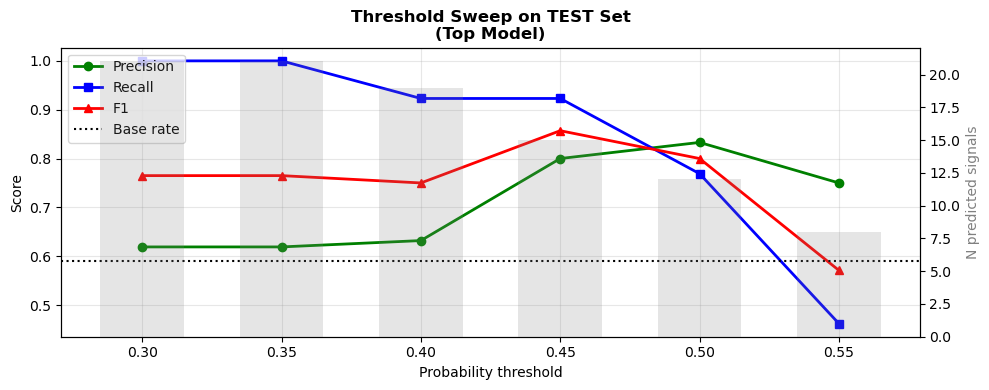


  Threshold Sweep Table (TEST):
 threshold  N_predicted  precision  recall    f1
      0.30           21      0.619   1.000 0.765
      0.35           21      0.619   1.000 0.765
      0.40           19      0.632   0.923 0.750
      0.45           15      0.800   0.923 0.857
      0.50           12      0.833   0.769 0.800
      0.55            8      0.750   0.462 0.571
════════════════════════════════════════════════════════════
BUY vs SELL ABSORPTION SPLIT
════════════════════════════════════════════════════════════

  BUY ABSORPTION  n=35  success=14 (40.0%)  fail=21
           feature  mean_success    mean_fail        diff  ks_stat  p_value
  rv_ratio_10d_40d        0.7352       1.1617     -0.4265    0.667    0.001
signed_delta_accel      931.5952    1469.7143   -538.1190    0.333    0.269
     lambda_zscore  -529939.9510 -984971.8973 455031.9463    0.310    0.350
    signed_drift_5        0.3286       0.7905     -0.4619    0.286    0.451
  signed_close_pos        0.1218       0

In [10]:

# ═══════════════════════════════════════════════════════════════════════════════
# CELL 1 — SETUP & IMPORTS
# ═══════════════════════════════════════════════════════════════════════════════

import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, r"C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents")

import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_score, recall_score, f1_score
from itertools import combinations

from market_analysis.config import (
    PRODUCTS, FRONT_N, OHLC_START_DATE, OHLC_END_DATE, ABSORPTION, COMPRESSION
)
from market_analysis.data.ohlc import getData_OHLC_v2, fetch_ohlc_1d, get_ohlc_for_horizon
from market_analysis.utils.contracts import (
    MONTH_CODES, next_n_contract_months, get_front_instruments, fmt_contract
)
from market_analysis.signals.absorption.calculate import calculate_absorption
from market_analysis.signals.absorption.label import label_absorption
from market_analysis.signals.compression.calculate import calculate_compression

# ── Constants ──────────────────────────────────────────────────────────────────
PRODUCT_CODE      = "SM"
TICK_SIZE         = PRODUCTS[PRODUCT_CODE]["tick_size"]          # 0.1
ABS_THRESHOLD     = 0.25    # absorption_strength filter
COMP_THRESHOLD    = 0.3    # compression_score filter
VOLUME_MIN        = 3000    # ignore bars with total volume below this
HORIZONS          = ["1d", "2d", "3d", "5d"]
TODAY             = datetime.date.today()

# Label params (from your best sweep row)
REQUIRED_MOVE_TICKS = 5     # 5 × tick = 0.5 pts
SL_LOOKBACK         = 10
FORWARD_DAYS        = 10

# ── OHLC fetch window per instrument ─────────────────────────────────────────
# Each spread's data starts 7 months before the front-leg's expiry month.
# e.g. SMZ26-SMF27  → front leg = Dec 2026 → start = 2026-05-01
MONTHS_BEFORE_EXPIRY = 7

# ── RV Ratio config ──────────────────────────────────────────────────────────
# All combinations of (numerator_window, denominator_window) will be computed
# as separate features rv_ratio_{N}d_{D}d and each will get its own plot.
# Convention: short_window / long_window  → >1 = vol expanding, <1 = compressing
RV_NUMERATOR_WINDOWS   = [3,4, 5, 10]      # short lookback options (days)
RV_DENOMINATOR_WINDOWS = [15, 20, 40]    # long  lookback options (days)

# ── Kyle Lambda z-score window ───────────────────────────────────────────────
# Rolling window (in bars) used to compute the mean and std of lambda_t
# for the z-score normalisation. Larger = more stable baseline, slower to adapt.
LAMBDA_ZSCORE_WINDOW: int = 15

# ── Kyle Lambda ratio window ───────────────────────────────────────────────
# lambda_ratio = lambda_t / mean(lambda_{t-LAMBDA_RATIO_WINDOW : t-1})
# Measures how current price-impact compares to recent average depth.
# < 1  → market currently harder to move than usual (deep, absorbing flow)
# > 1  → market thinner than usual (each unit of delta moves price more)
LAMBDA_RATIO_WINDOW: int = 5     # how many past bars to average for the denominator
# ─────────────────────────────────────────────────────────────────────────────

print("✅ Setup complete")
print(f"   Product       : {PRODUCT_CODE}  tick={TICK_SIZE}")
print(f"   Abs threshold : {ABS_THRESHOLD}   Comp threshold: {COMP_THRESHOLD}")
print(f"   Volume filter : >{VOLUME_MIN}    Forward days: {FORWARD_DAYS}")
print(f"   Today         : {TODAY}")
print(f"   Fetch window  : {MONTHS_BEFORE_EXPIRY} months before front-leg expiry")
print(f"   RV numerators : {RV_NUMERATOR_WINDOWS}")
print(f"   RV denominators: {RV_DENOMINATOR_WINDOWS}")
print(f"   Lambda zscore window : {LAMBDA_ZSCORE_WINDOW}d")
print(f"   Lambda ratio  window : {LAMBDA_RATIO_WINDOW}d")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 2 — INSTRUMENT SELECTION (front 4 + recently expired spreads)
# ═══════════════════════════════════════════════════════════════════════════════

def get_expired_spreads(product_code: str, n_expired: int = 3) -> list[str]:
    """
    Return the last `n_expired` calendar-consecutive spread pairs that expired
    before today. Uses the same traded_months list from config.
    """
    product  = PRODUCTS[product_code]
    traded   = sorted(product["traded_months"])
    prefix   = product["api_prefix"]

    # walk backwards from today to collect recent contract months
    y, m     = TODAY.year, TODAY.month
    collected = []
    while len(collected) < n_expired + 4:   # collect extra buffer
        m -= 1
        if m < 1:
            m = 12; y -= 1
        if m in traded:
            collected.append((y, m))

    collected.reverse()   # chronological order

    pairs = []
    for i in range(len(collected) - 1):
        front = fmt_contract(prefix, *collected[i])
        back  = fmt_contract(prefix, *collected[i + 1])
        pairs.append(f"{front}-{back}")

    # take the most recent n_expired pairs
    return pairs[-n_expired:]


def instr_fetch_start(instrument: str, months_before: int = MONTHS_BEFORE_EXPIRY) -> str:
    """
    Derive the OHLC fetch start date for a spread instrument.

    Logic: parse the front-leg contract → find its expiry month (year, month)
           → subtract `months_before` calendar months → return "YYYY-MM-01".

    Example:
        "SMZ26-SMF27"  → front leg SMZ26 → Dec 2026
                       → 7 months before Dec = May 2026
                       → start = "2026-05-01"
    """
    import re
    # Reverse MONTH_CODES so we can go from letter → month number
    CODE_TO_MONTH = {v: k for k, v in MONTH_CODES.items()}

    front_leg = instrument.split("-")[0]          # e.g. "SMZ26"
    m_obj     = re.match(r"^[A-Za-z]+([A-Z])(\d{2})$", front_leg)
    if not m_obj:
        # Fallback: use global OHLC_START_DATE if we can't parse
        return OHLC_START_DATE

    month_code = m_obj.group(1)                   # e.g. "Z"
    year_2dig  = int(m_obj.group(2))              # e.g. 26
    year       = 2000 + year_2dig                 # e.g. 2026
    month      = CODE_TO_MONTH.get(month_code, 1) # e.g. 12 (December)

    # subtract months_before months
    start_month = month - months_before
    start_year  = year
    while start_month < 1:
        start_month += 12
        start_year  -= 1

    return f"{start_year}-{start_month:02d}-01"


# Front 4 spreads starting from today
front_4 = get_front_instruments(PRODUCT_CODE, "spread",
                                reference_date=TODAY, front_n=4)

# ~3 recently expired spreads for extra data
expired_3 = get_expired_spreads(PRODUCT_CODE, n_expired=3)

ALL_INSTRUMENTS = expired_3 + front_4

print("═" * 60)
print("INSTRUMENTS SELECTED")
print("═" * 60)
print(f"  Expired spreads : {expired_3}")
print(f"  Front 4 spreads : {front_4}")
print(f"  Total           : {len(ALL_INSTRUMENTS)} instruments")
print()
print("  Derived fetch windows (7 months before front-leg expiry):")
for instr in ALL_INSTRUMENTS:
    print(f"    {instr:22s}  start={instr_fetch_start(instr)}")
print("═" * 60)


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 3 — FETCH, SCORE (absorption + compression) FOR ALL INSTRUMENTS
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("FETCHING & SCORING OHLC DATA")
print("═" * 60)

# Store per-instrument scored 1D DataFrames (before aggregation)
scored_1d = {}      # {instrument: df_with_absorption_1d}
scored_nd = {}      # {instrument: {horizon: df}}

for instr in ALL_INSTRUMENTS:
    print(f"\n  ▸ {instr}")

    # Per-instrument fetch window: 7 months before front-leg expiry
    instr_start = instr_fetch_start(instr)
    print(f"    fetch_start={instr_start}")

    # --- 1D fetch & absorption score ---
    df1d = fetch_ohlc_1d(instr, PRODUCT_CODE, getData_OHLC_v2,
                          start_date=instr_start, end_date=OHLC_END_DATE)
    if df1d is None or len(df1d) < 70:
        print(f"    [SKIP] not enough data (rows={len(df1d) if df1d is not None else 0})")
        continue

    df1d_abs  = calculate_absorption(df1d, window=60,
                                      tick_size=TICK_SIZE, strength_threshold=ABS_THRESHOLD)
    df1d_abs  = label_absorption(df1d_abs, tick=TICK_SIZE,
                                  required_move_ticks=REQUIRED_MOVE_TICKS,
                                  sl_lookback=SL_LOOKBACK,
                                  forward_days=FORWARD_DAYS)
    scored_1d[instr] = df1d_abs

    # --- compression on 1D ---
    df1d_comp, _ = calculate_compression(df1d.copy(),
                                          compression_threshold=COMP_THRESHOLD)

    # merge compression_score into absorption df by Date
    comp_merge = df1d_comp[["Date", "compression_score"]].copy()
    comp_merge["Date"] = pd.to_datetime(comp_merge["Date"]).dt.strftime("%Y-%m-%d")
    df1d_abs["Date"]   = pd.to_datetime(df1d_abs["Date"]).dt.strftime("%Y-%m-%d")
    df1d_abs = df1d_abs.merge(comp_merge.rename(columns={"compression_score": "comp_score_1d"}),
                               on="Date", how="left")
    scored_1d[instr] = df1d_abs

    # --- multi-horizon absorption scores (for consistency feature) ---
    scored_nd[instr] = {}
    for hz in HORIZONS:
        from market_analysis.data.ohlc import _aggregate_trailing
        from market_analysis.config import HORIZON_BARS
        n_bars = HORIZON_BARS[hz]
        dfh    = df1d.copy() if n_bars == 1 else _aggregate_trailing(df1d.copy(), n_bars)
        if dfh is None or len(dfh) < 65:
            continue
        dfh_sc = calculate_absorption(dfh, window=60,
                                       tick_size=TICK_SIZE, strength_threshold=ABS_THRESHOLD)
        scored_nd[instr][hz] = dfh_sc
    print(f"    rows={len(df1d_abs)}  "
          f"abs_events={(df1d_abs['absorption_strength'] > ABS_THRESHOLD).sum()}")

print("\n✅ Scoring complete")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 4 — FEATURE ENGINEERING
# (all past-only, no forward leakage, computed at bar t)
# ═══════════════════════════════════════════════════════════════════════════════

def build_resolution_features(df: pd.DataFrame,
                                scored_nd_for_instr: dict,
                                tick: float = 0.1,
                                epsilon: float = 1e-9) -> pd.DataFrame:
    """
    Add Stage-2 characterization features to a scored+labeled 1D DataFrame.
    All features use only [t-N : t] — strictly past-only.
    """
    d = df.copy().sort_values("Date").reset_index(drop=True)

    # ── 1. Intrabar: close position within bar ──────────────────────────────
    d["close_pos"] = (d["close"] - d["low"]) / (d["high"] - d["low"] + epsilon)
    # Signed for direction:
    #   BUY  absorption → reversal = price drops → close near LOW is BAD for buyers
    #     close_pos LOW (< 0.3) → sellers won intrabar → reversal hint → signed negative
    #   SELL absorption → reversal = price rises → close near HIGH is BAD for sellers
    # Convention: signed_close_pos > 0 → continuation, < 0 → reversal
    d["signed_close_pos"] = np.where(
        d["absorption_direction"] == "BUY",
        d["close_pos"] - 0.5,          # BUY: high → continuation (+), low → reversal (-)
        0.5 - d["close_pos"],          # SELL: low → continuation (+), high → reversal (-)
    )

    # ── 2. Intrabar: wick asymmetry ──────────────────────────────────────────
    d["upper_wick"] = d["high"] - d[["open", "close"]].max(axis=1)
    d["lower_wick"] = d[["open", "close"]].min(axis=1) - d["low"]
    d["wick_ratio"] = d["upper_wick"] / (d["lower_wick"] + epsilon)
    # BUY absorption: large upper wick → price pushed up but rejected → reversal
    # SELL absorption: large lower wick → price tested down but rejected → reversal
    # Sign: negative → reversal hint
    d["signed_wick_ratio"] = np.where(
        d["absorption_direction"] == "BUY",
        -(d["wick_ratio"] - 1.0),       # BUY: wick_ratio >> 1 → reversal → negative
        (d["wick_ratio"] - 1.0),        # SELL: wick_ratio << 1 → reversal → positive issue
    )
    # simpler: just keep raw wick_ratio and let model learn direction via dir dummy

    # ── 3. Delta ratio (how one-sided) ───────────────────────────────────────
    d["delta_ratio"] = d["buyvolume"] / (d["sellvolume"] + epsilon)

    # ── 4. Delta momentum: is aggressive flow accel or dying? ────────────────
    d["delta_accel"] = d["delta"] - d["delta"].shift(1).rolling(3, min_periods=1).mean()
    # Sign to success: BUY absorption — if delta_accel positive → buyers not exhausted → continuation
    # SELL absorption — if delta_accel negative (sell delta growing) → sellers not exhausted → continuation
    d["signed_delta_accel"] = np.where(
        d["absorption_direction"] == "BUY",
        d["delta_accel"],
        -d["delta_accel"],
    )

    # ── 5. Volume deceleration ───────────────────────────────────────────────
    vol_roll5 = d["volume"].shift(1).rolling(5, min_periods=2).mean()
    d["vol_ratio"] = d["volume"] / (vol_roll5 + epsilon)
    # vol_ratio < 1 → volume drying up → exhaustion → reversal (negative for our sign)
    # signed: positive → continuation hint
    d["signed_vol_ratio"] = d["vol_ratio"] - 1.0   # >0 = escalating, <0 = dying

    # ── 6. Price drift into absorption ───────────────────────────────────────
    d["drift_5"] = (d["close"] - d["close"].shift(5)) / (5 * tick + epsilon)
    # BUY absorption after falling prices (drift_5 < 0) → counter-trend buyers → reversal likely
    # SELL absorption after rising prices (drift_5 > 0) → counter-trend sellers → reversal likely
    # Sign: same direction as absorption = continuation, opposite = reversal
    d["signed_drift_5"] = np.where(
        d["absorption_direction"] == "BUY",
        d["drift_5"],          # rising drift + BUY absorption → continuation
        -d["drift_5"],         # falling drift + SELL absorption → continuation
    )

    # ── 7. Kyle Lambda: market depth anomaly ─────────────────────────────────
    price_change = d["close"].diff().abs()
    abs_delta    = d["delta"].abs()
    d["lambda_t"] = price_change / (abs_delta + epsilon)

    # lambda_ratio: current vs recent average depth
    #   = lambda_t / mean(lambda[t-LAMBDA_RATIO_WINDOW : t-1])
    #   < 1 → market deeper than usual → flow absorbed without moving price much
    #   > 1 → market thinner than usual → each delta unit moves price more
    _lam_ratio_mp          = max(2, LAMBDA_RATIO_WINDOW // 2)
    d["lambda_ratio_avg"]  = (
        d["lambda_t"].shift(1)
        .rolling(LAMBDA_RATIO_WINDOW, min_periods=_lam_ratio_mp)
        .mean()
    )
    d["lambda_ratio"] = d["lambda_t"] / (d["lambda_ratio_avg"] + epsilon)

    # lambda_zscore: z-normalised over a longer baseline window
    _lam_mp    = max(10, LAMBDA_ZSCORE_WINDOW // 3)
    lam_mean   = d["lambda_t"].shift(1).rolling(LAMBDA_ZSCORE_WINDOW, min_periods=_lam_mp).mean()
    lam_std    = d["lambda_t"].shift(1).rolling(LAMBDA_ZSCORE_WINDOW, min_periods=_lam_mp).std()
    d["lambda_zscore"] = (d["lambda_t"] - lam_mean) / (lam_std + epsilon)
    # very negative lambda_zscore = unusually deep market = strong absorption event
    # (window controlled by LAMBDA_ZSCORE_WINDOW; ratio window by LAMBDA_RATIO_WINDOW)

    # ── 8. Realized volatility ratios (all configured combinations) ──────────
    # Config lists RV_NUMERATOR_WINDOWS and RV_DENOMINATOR_WINDOWS (defined in Cell 1).
    # For each (num_w, den_w) pair where num_w < den_w we compute:
    #   rv_ratio_{num_w}d_{den_w}d = rv(num_w) / rv(den_w)
    # >1 = vol expanding (short > long)  |  <1 = vol compressing
    log_ret = np.log(d["close"].replace(0, np.nan) / d["close"].shift(1).replace(0, np.nan))

    # Pre-compute each unique window std once
    all_windows = sorted(set(RV_NUMERATOR_WINDOWS + RV_DENOMINATOR_WINDOWS))
    rv_cache = {}
    for w in all_windows:
        mp = max(2, w // 2)
        rv_cache[w] = log_ret.rolling(w, min_periods=mp).std()

    for num_w in RV_NUMERATOR_WINDOWS:
        for den_w in RV_DENOMINATOR_WINDOWS:
            if num_w >= den_w:
                continue   # skip: numerator must be shorter than denominator
            col = f"rv_ratio_{num_w}d_{den_w}d"
            d[col] = rv_cache[num_w] / (rv_cache[den_w] + epsilon)

    # Keep the original rv_ratio name pointing at the first valid combo
    # so downstream code that references "rv_ratio" still works
    _first_num = next((n for n in RV_NUMERATOR_WINDOWS for den in RV_DENOMINATOR_WINDOWS if n < den), None)
    _first_den = next((den for n in RV_NUMERATOR_WINDOWS for den in RV_DENOMINATOR_WINDOWS if n < den), None)
    if _first_num is not None:
        d["rv_ratio"] = d[f"rv_ratio_{_first_num}d_{_first_den}d"]
    # rv_ratio > 1 → short-window vol > long-window vol → expanding (high-vol regime)
    # rv_ratio < 1 → short-window vol < long-window vol → compressing (quiet)

    # ── 9. Multi-timeframe consistency ───────────────────────────────────────
    # For each bar date, check if absorption_strength > ABS_THRESHOLD on other horizons
    d["Date_str"] = pd.to_datetime(d["Date"]).dt.strftime("%Y-%m-%d")
    tf_scores = {hz: {} for hz in HORIZONS}
    for hz, dfh in scored_nd_for_instr.items():
        if dfh is None or "absorption_strength" not in dfh.columns:
            continue
        dfh_copy = dfh.copy()
        dfh_copy["Date_str"] = pd.to_datetime(dfh_copy["Date"]).dt.strftime("%Y-%m-%d")
        for _, row in dfh_copy.iterrows():
            tf_scores[hz][row["Date_str"]] = row["absorption_strength"]

    consistency_vals = []
    for _, row in d.iterrows():
        date_key = row["Date_str"]
        fires = [
            1 if tf_scores[hz].get(date_key, 0) > ABS_THRESHOLD else 0
            for hz in HORIZONS
        ]
        consistency_vals.append(np.mean(fires))
    d["tf_consistency"] = consistency_vals

    # ── 10. Dual signal: both absorption AND compression fire ─────────────────
    d["dual_signal"] = (
        (d["absorption_strength"] > ABS_THRESHOLD) &
        (d.get("comp_score_1d", pd.Series(0, index=d.index)).fillna(0) > COMP_THRESHOLD)
    ).astype(float)

    # ── 11. Direction dummy (BUY=1, SELL=0) ──────────────────────────────────
    d["is_buy_absorption"] = (d["absorption_direction"] == "BUY").astype(float)

    return d


# Apply feature engineering to all instruments
print("═" * 60)
print("FEATURE ENGINEERING")
print("═" * 60)

featured = {}
for instr, df in scored_1d.items():
    nd_for_instr = scored_nd.get(instr, {})
    featured[instr] = build_resolution_features(df, nd_for_instr, tick=TICK_SIZE)
    print(f"  ✓ {instr}  columns={len(featured[instr].columns)}")

print("✅ Feature engineering complete")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 5 — POOL ABSORPTION EVENTS & SUMMARY
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("POOLING ABSORPTION EVENTS (volume > 3000, strength > 0.25)")
print("═" * 60)

FEATURE_COLS = [
    "signed_close_pos",
    "signed_wick_ratio",
    "signed_delta_accel",
    "signed_vol_ratio",
    "signed_drift_5",
    "lambda_zscore",
    "rv_ratio",
    "tf_consistency",
    "dual_signal",
    "is_buy_absorption",
    # raw (unsigned) versions also included for exploration
    "close_pos",
    "wick_ratio",
    "vol_ratio",
    "delta_ratio",
    "lambda_ratio",
]

all_events = []
for instr, df in featured.items():
    mask = (
        (df["absorption_strength"] > ABS_THRESHOLD) &
        (df["volume"] > VOLUME_MIN) &
        (df["sl_success"].notna())
    )
    subset = df[mask].copy()
    subset["instrument"] = instr
    all_events.append(subset)

if not all_events:
    print("❌ No events found — check thresholds or data fetch")
else:
    pool = pd.concat(all_events, ignore_index=True)
    pool = pool.sort_values("Date").reset_index(drop=True)

    n_total   = len(pool)
    n_success = int(pool["sl_success"].sum())
    n_fail    = int((pool["sl_success"] == 0).sum())
    base_rate = n_success / n_total if n_total > 0 else 0

    print(f"\n  Total absorption events : {n_total}")
    print(f"  Success (reversal)      : {n_success}  ({100*base_rate:.1f}%)")
    print(f"  Failure                 : {n_fail}")
    print(f"\n  Per instrument:")
    for instr in pool["instrument"].unique():
        sub = pool[pool["instrument"] == instr]
        s = int(sub["sl_success"].sum())
        print(f"    {instr:20s}  n={len(sub):3d}  success={s}")
    print()

    # ensure features are numeric
    for fc in FEATURE_COLS:
        if fc in pool.columns:
            pool[fc] = pd.to_numeric(pool[fc], errors="coerce")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 6 — DISTRIBUTION PLOTS: Feature separation (success vs fail)
# ═══════════════════════════════════════════════════════════════════════════════

# ── Helper: plot a set of features and return separation stats ────────────────
def _plot_feature_grid(pool_df, feature_list, title_prefix=""):
    """
    Plots histograms for each (feat, label) tuple in feature_list.
    Returns a list of separation stat dicts.
    """
    suc = pool_df[pool_df["sl_success"] == 1]
    fai = pool_df[pool_df["sl_success"] == 0]
    stats_out = []

    n_cols = 3
    n_rows = (len(feature_list) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3.5))
    axes = axes.flatten()

    for ax, (feat, label) in zip(axes, feature_list):
        if feat not in pool_df.columns:
            ax.set_visible(False); continue
        s_vals = suc[feat].dropna()
        f_vals = fai[feat].dropna()
        if len(s_vals) == 0 or len(f_vals) == 0:
            ax.set_visible(False); continue

        ax.hist(f_vals, bins=20, alpha=0.5, color="#e74c3c", density=True,
                label=f"Fail (n={len(f_vals)})")
        ax.hist(s_vals, bins=20, alpha=0.5, color="#2ecc71", density=True,
                label=f"Success (n={len(s_vals)})")
        ks_stat, ks_pval = stats.ks_2samp(s_vals, f_vals)
        mean_diff = s_vals.mean() - f_vals.mean()
        ax.set_title(label, fontsize=9, fontweight="bold")
        ax.set_xlabel(f"KS={ks_stat:.2f}  p={ks_pval:.3f}  Δmean={mean_diff:+.3f}", fontsize=8)
        ax.legend(fontsize=7); ax.grid(alpha=0.3)
        stats_out.append({"feature": feat, "ks_stat": ks_stat, "ks_pval": ks_pval,
                           "mean_success": s_vals.mean(), "mean_fail": f_vals.mean(),
                           "mean_diff": mean_diff})

    for ax in axes[len(feature_list):]:
        ax.set_visible(False)
    plt.suptitle(f"{title_prefix}\n"
                 f"(Abs≥{ABS_THRESHOLD}, Vol>{VOLUME_MIN}, "
                 f"n={n_total}, base={base_rate:.1%})",
                 fontsize=10, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()
    return stats_out


# ── Section A: core signed features ──────────────────────────────────────────
CORE_PLOT_FEATURES = [
    ("signed_close_pos",   "Signed Close Position\n(+→ continuation, -→ reversal)"),
    ("signed_wick_ratio",  "Signed Wick Ratio\n(+→ continuation, -→ reversal)"),
    ("signed_delta_accel", "Signed Delta Accel\n(+→ flow accel, -→ flow dying)"),
    ("signed_vol_ratio",   "Signed Vol Ratio\n(+→ vol escalating, -→ vol dying)"),
    ("signed_drift_5",     "Signed 5-Day Drift\n(+→ with trend, -→ counter trend)"),
    ("lambda_zscore",      "Kyle Lambda Z-Score\n(- = unusually deep market)"),
    ("lambda_ratio",       f"Lambda Ratio (w={LAMBDA_RATIO_WINDOW}d)\n(<1=deep/absorbing, >1=thin/reactive)"),
    ("tf_consistency",     "Multi-TF Consistency\n(fraction of HZs that fire)"),
    ("dual_signal",        "Dual Signal\n(Abs + Compression both fire)"),
]

print("═" * 60)
print("SECTION A — CORE FEATURE SEPARATION (success vs failure)")
print("═" * 60)
sep_stats = _plot_feature_grid(pool, CORE_PLOT_FEATURES,
                                title_prefix="Core Features: Success vs Failure")

sep_df = pd.DataFrame(sep_stats).sort_values("ks_stat", ascending=False)
print("\nCore Feature Separation (KS test, sorted by KS stat):")
print(sep_df[["feature", "ks_stat", "ks_pval", "mean_success", "mean_fail", "mean_diff"]].to_string(index=False))


# ── Section B: RV Ratio — all window combinations ────────────────────────────
print()
print("═" * 60)
print("SECTION B — RV RATIO COMBINATIONS (all num/den window pairs)")
print(f"  Numerator  windows: {RV_NUMERATOR_WINDOWS}")
print(f"  Denominator windows: {RV_DENOMINATOR_WINDOWS}")
print("═" * 60)

RV_PLOT_FEATURES = []
for num_w in RV_NUMERATOR_WINDOWS:
    for den_w in RV_DENOMINATOR_WINDOWS:
        if num_w >= den_w:
            continue
        col   = f"rv_ratio_{num_w}d_{den_w}d"
        label = (f"RV Ratio {num_w}d / {den_w}d\n"
                 f"(>1=vol expanding, <1=compressing)")
        RV_PLOT_FEATURES.append((col, label))

if RV_PLOT_FEATURES:
    rv_sep_stats = _plot_feature_grid(pool, RV_PLOT_FEATURES,
                                       title_prefix="RV Ratio Combinations: Success vs Failure")
    rv_sep_df = pd.DataFrame(rv_sep_stats).sort_values("ks_stat", ascending=False)
    print("\nRV Ratio Separation (KS test, sorted by KS stat):")
    print(rv_sep_df[["feature", "ks_stat", "ks_pval",
                     "mean_success", "mean_fail", "mean_diff"]].to_string(index=False))
    print(f"\n  → Best RV combo: {rv_sep_df.iloc[0]['feature']}  "
          f"KS={rv_sep_df.iloc[0]['ks_stat']:.3f}")
    # Store best for use in model sweep
    BEST_RV_FEATURE = rv_sep_df.iloc[0]["feature"]
else:
    print("  No valid RV combos (all numerators >= denominators). Check config.")
    BEST_RV_FEATURE = "rv_ratio"

# Combined separation table (all features)
all_sep_df = pd.concat([sep_df, rv_sep_df if RV_PLOT_FEATURES else pd.DataFrame()],
                        ignore_index=True).sort_values("ks_stat", ascending=False)
print("\n── ALL FEATURES combined (sorted by KS stat) ──")
print(all_sep_df[["feature", "ks_stat", "ks_pval", "mean_diff"]].to_string(index=False))
success_events = pool[pool["sl_success"] == 1]
fail_events    = pool[pool["sl_success"] == 0]


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 7 — WALK-FORWARD TRAIN / TEST SPLIT
# ═══════════════════════════════════════════════════════════════════════════════

pool_sorted = pool.sort_values("Date").reset_index(drop=True)
split_idx   = int(len(pool_sorted) * 0.70)
train_df    = pool_sorted.iloc[:split_idx].copy()
test_df     = pool_sorted.iloc[split_idx:].copy()

print("═" * 60)
print("WALK-FORWARD SPLIT")
print("═" * 60)
print(f"  Train: {len(train_df)} events | {train_df['Date'].min()} → {train_df['Date'].max()}")
print(f"  Test : {len(test_df)} events  | {test_df['Date'].min()} → {test_df['Date'].max()}")
print(f"  Train base rate: {train_df['sl_success'].mean():.1%}")
print(f"  Test  base rate: {test_df['sl_success'].mean():.1%}")


def get_Xy(df: pd.DataFrame, feats: list[str]):
    """Extract X, y matrices from a pool DataFrame, dropping NaN rows."""
    sub  = df[feats + ["sl_success"]].dropna()
    X    = sub[feats].values.astype(float)
    y    = sub["sl_success"].values.astype(int)
    return X, y, sub.index


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 8 — FEATURE COMBO SWEEP (SGD Logistic Regression)
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("FEATURE COMBINATION SWEEP (SGD Logistic Regression)")
print("═" * 60)

# Signed feature candidates (theoretically motivated).
# rv_ratio is replaced by the best-KS combo found in Cell 6 Section B.
SIGNED_FEATS = [
    "signed_close_pos",
    "signed_delta_accel",
    "signed_vol_ratio",
    "signed_drift_5",
    "lambda_zscore",
    "lambda_ratio",        # depth ratio vs recent avg (LAMBDA_RATIO_WINDOW)
    BEST_RV_FEATURE,       # best RV window combo by KS separation
    "tf_consistency",
    #"signed_wick_ratio",
]

# Filter to only features that exist and have enough variance
available_feats = [
    f for f in SIGNED_FEATS
    if f in train_df.columns and train_df[f].dropna().std() > 1e-6
]
print(f"  Available features: {available_feats}\n")

# Combos of size 2–6 (theoretically motivated pairs first, then expand)
# Plus one full-feature model
combo_sizes = [2, 3, 4, 5]
combos      = []
for size in combo_sizes:
    combos.extend(list(combinations(available_feats, size)))
# Add full model
combos.append(tuple(available_feats))

print(f"  Total combos to evaluate: {len(combos)}")

def make_sgd_pipeline():
    clf = SGDClassifier(
        loss="log_loss",
        penalty="l2",
        alpha=0.01,
        max_iter=1000,
        tol=1e-4,
        random_state=42,
        class_weight="balanced",
    )
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])


results = []
for combo in combos:
    feats = list(combo)
    X_tr, y_tr, _ = get_Xy(train_df, feats)
    X_te, y_te, _ = get_Xy(test_df,  feats)

    if len(X_tr) < 20 or len(X_te) < 5:
        continue
    if len(np.unique(y_tr)) < 2 or len(np.unique(y_te)) < 2:
        continue

    pipe = make_sgd_pipeline()
    try:
        pipe.fit(X_tr, y_tr)
    except Exception:
        continue

    y_pred_prob = pipe.predict_proba(X_te)[:, 1]
    # Use 0.5 as default threshold
    y_pred = (y_pred_prob >= 0.5).astype(int)

    prec   = precision_score(y_te, y_pred, zero_division=0)
    rec    = recall_score(y_te,    y_pred, zero_division=0)
    f1     = f1_score(y_te,        y_pred, zero_division=0)
    # Lift over base rate
    base   = y_te.mean() if y_te.mean() > 0 else 1e-9
    lift   = prec / base

    results.append({
        "features"  : feats,
        "n_feats"   : len(feats),
        "precision" : round(prec, 4),
        "recall"    : round(rec,  4),
        "f1"        : round(f1,   4),
        "lift"      : round(lift, 4),
        "n_train"   : len(X_tr),
        "n_test"    : len(X_te),
    })

results_df = pd.DataFrame(results).sort_values("precision", ascending=False).reset_index(drop=True)

print("\n  Top 15 combos by Precision on TEST set:")
print("─" * 80)
for i, row in results_df.head(15).iterrows():
    print(f"  [{i+1:2d}] n_feats={row['n_feats']}  "
          f"P={row['precision']:.3f}  R={row['recall']:.3f}  "
          f"F1={row['f1']:.3f}  Lift={row['lift']:.2f}")
    print(f"       features: {row['features']}")

print(f"\n  Base rate on test: {test_df['sl_success'].mean():.1%}")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 9 — TOP MODEL DEEP DIVE (threshold sweep + coefficients)
# ═══════════════════════════════════════════════════════════════════════════════

# Pick top combo by precision
best_row   = results_df.iloc[0]
best_feats = best_row["features"]
print("═" * 60)
print(f"TOP MODEL ANALYSIS")
print("═" * 60)
print(f"  Features: {best_feats}")
print(f"  Train n={best_row['n_train']}  Test n={best_row['n_test']}")
print(f"  Precision={best_row['precision']:.3f}  Recall={best_row['recall']:.3f}  "
      f"F1={best_row['f1']:.3f}  Lift={best_row['lift']:.2f}")

X_tr, y_tr, _ = get_Xy(train_df, best_feats)
X_te, y_te, _ = get_Xy(test_df,  best_feats)

best_pipe = make_sgd_pipeline()
best_pipe.fit(X_tr, y_tr)
y_prob_te = best_pipe.predict_proba(X_te)[:, 1]

# ── Coefficients ──────────────────────────────────────────────────────────────
coefs = best_pipe.named_steps["clf"].coef_[0]
coef_df = pd.DataFrame({
    "feature": best_feats,
    "coefficient": coefs,
    "abs_coef": np.abs(coefs)
}).sort_values("abs_coef", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Coefficient bar chart
ax = axes[0]
colors = ["#2ecc71" if c > 0 else "#e74c3c" for c in coef_df["coefficient"]]
ax.barh(coef_df["feature"], coef_df["coefficient"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Model Coefficients\n(+ → predicts success/continuation)", fontweight="bold")
ax.set_xlabel("Coefficient (scaled)")
ax.grid(alpha=0.3, axis="x")

# Probability distribution by outcome
ax = axes[1]
ax.hist(y_prob_te[y_te == 0], bins=15, alpha=0.6, color="#e74c3c", density=True, label="Fail")
ax.hist(y_prob_te[y_te == 1], bins=15, alpha=0.6, color="#2ecc71", density=True, label="Success")
ax.axvline(0.5, color="black", linestyle="--", label="Threshold=0.5")
ax.set_title("Predicted Probability Distribution\n(Test set)", fontweight="bold")
ax.set_xlabel("P(success)")
ax.legend()
ax.grid(alpha=0.3)

plt.suptitle(f"Top Model Deep Dive  |  Features: {best_feats}", fontsize=9)
plt.tight_layout()
plt.show()

print("\n  Coefficients (sorted by |coef|):")
print(coef_df[["feature", "coefficient"]].to_string(index=False))


# ── Threshold sweep on test set ───────────────────────────────────────────────
thresholds = np.arange(0.30, 0.85, 0.05)
sweep_rows = []
for t in thresholds:
    y_pred_t = (y_prob_te >= t).astype(int)
    n_pred   = y_pred_t.sum()
    if n_pred == 0:
        continue
    p = precision_score(y_te, y_pred_t, zero_division=0)
    r = recall_score(y_te,    y_pred_t, zero_division=0)
    f = f1_score(y_te,        y_pred_t, zero_division=0)
    sweep_rows.append({"threshold": round(t, 2), "N_predicted": n_pred,
                        "precision": round(p, 3), "recall": round(r, 3), "f1": round(f, 3)})

sweep_res = pd.DataFrame(sweep_rows)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(sweep_res["threshold"], sweep_res["precision"], "g-o", label="Precision", linewidth=2)
ax.plot(sweep_res["threshold"], sweep_res["recall"],    "b-s", label="Recall",    linewidth=2)
ax.plot(sweep_res["threshold"], sweep_res["f1"],        "r-^", label="F1",        linewidth=2)
ax2 = ax.twinx()
ax2.bar(sweep_res["threshold"], sweep_res["N_predicted"], alpha=0.2, color="gray",
        width=0.03, label="N predicted")
ax2.set_ylabel("N predicted signals", color="gray")
ax.axhline(test_df["sl_success"].mean(), color="black", linestyle=":", label=f"Base rate")
ax.set_xlabel("Probability threshold")
ax.set_ylabel("Score")
ax.set_title("Threshold Sweep on TEST Set\n(Top Model)", fontweight="bold")
ax.legend(loc="upper left"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\n  Threshold Sweep Table (TEST):")
print(sweep_res.to_string(index=False))


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 10 — BUY vs SELL ABSORPTION SPLIT ANALYSIS
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("BUY vs SELL ABSORPTION SPLIT")
print("═" * 60)

for direction in ["BUY", "SELL"]:
    sub = pool[pool["absorption_direction"] == direction].copy()
    n   = len(sub)
    if n < 15:
        print(f"  {direction}: too few events ({n}), skipping")
        continue

    s_sub = sub[sub["sl_success"] == 1]
    f_sub = sub[sub["sl_success"] == 0]
    print(f"\n  {direction} ABSORPTION  n={n}  "
          f"success={len(s_sub)} ({100*len(s_sub)/n:.1f}%)  "
          f"fail={len(f_sub)}")

    feat_means = []
    for feat in available_feats:
        if feat not in sub.columns:
            continue
        sv = s_sub[feat].dropna()
        fv = f_sub[feat].dropna()
        if len(sv) < 3 or len(fv) < 3:
            continue
        ks, pv = stats.ks_2samp(sv, fv)
        feat_means.append({
            "feature": feat,
            "mean_success": round(sv.mean(), 4),
            "mean_fail"   : round(fv.mean(), 4),
            "diff"        : round(sv.mean() - fv.mean(), 4),
            "ks_stat"     : round(ks, 3),
            "p_value"     : round(pv, 3),
        })

    feat_means_df = pd.DataFrame(feat_means).sort_values("ks_stat", ascending=False)
    print(feat_means_df.to_string(index=False))

    # Train direction-specific model if enough data
    sub_sorted = sub.sort_values("Date").reset_index(drop=True)
    sp = int(len(sub_sorted) * 0.70)
    tr_d = sub_sorted.iloc[:sp]
    te_d = sub_sorted.iloc[sp:]
    if len(tr_d) < 15 or len(te_d) < 5:
        print(f"  [{direction}] Not enough data for direction model")
        continue

    X_tr_d, y_tr_d, _ = get_Xy(tr_d, best_feats)
    X_te_d, y_te_d, _ = get_Xy(te_d, best_feats)
    if len(np.unique(y_tr_d)) < 2:
        print(f"  [{direction}] Only one class in train, skipping")
        continue

    pipe_d = make_sgd_pipeline()
    pipe_d.fit(X_tr_d, y_tr_d)
    if len(np.unique(y_te_d)) < 2:
        print(f"  [{direction}] Only one class in test set, skipping metrics")
        continue
    y_pred_d = pipe_d.predict(X_te_d)
    print(f"\n  [{direction}] Direction-specific model (same features):")
    print(f"    Precision={precision_score(y_te_d, y_pred_d, zero_division=0):.3f}  "
          f"Recall={recall_score(y_te_d, y_pred_d, zero_division=0):.3f}  "
          f"F1={f1_score(y_te_d, y_pred_d, zero_division=0):.3f}")
    coefs_d = pipe_d.named_steps["clf"].coef_[0]
    print(f"    Coefficients: " +
          "  ".join(f"{f}={c:+.3f}" for f, c in zip(best_feats, coefs_d)))


print("\n" + "═" * 60)
print("ANALYSIS COMPLETE")
print("═" * 60)


✅ Setup complete
   Product       : SM  tick=0.1
   Abs threshold : 0.25   Comp threshold: 0.3
   Volume filter : >3000    Forward days: 10
   Today         : 2026-09-21
   Fetch window  : 7 months before front-leg expiry
   RV numerators : [3, 5, 10]
   RV denominators: [15, 20, 40]
   Lambda zscore window : 60d
   Lambda ratio  window : 5d
════════════════════════════════════════════════════════════
INSTRUMENTS SELECTED
════════════════════════════════════════════════════════════
  Expired spreads : ['SMH26-SMK26', 'SMK26-SMN26', 'SMN26-SMQ26']
  Front 4 spreads : ['SMV26-SMZ26', 'SMZ26-SMF27', 'SMF27-SMH27', 'SMH27-SMK27']
  Total           : 7 instruments

  Derived fetch windows (7 months before front-leg expiry):
    SMH26-SMK26             start=2025-08-01
    SMK26-SMN26             start=2025-10-01
    SMN26-SMQ26             start=2025-12-01
    SMV26-SMZ26             start=2026-03-01
    SMZ26-SMF27             start=2026-05-01
    SMF27-SMH27             start=2026-06-01
 

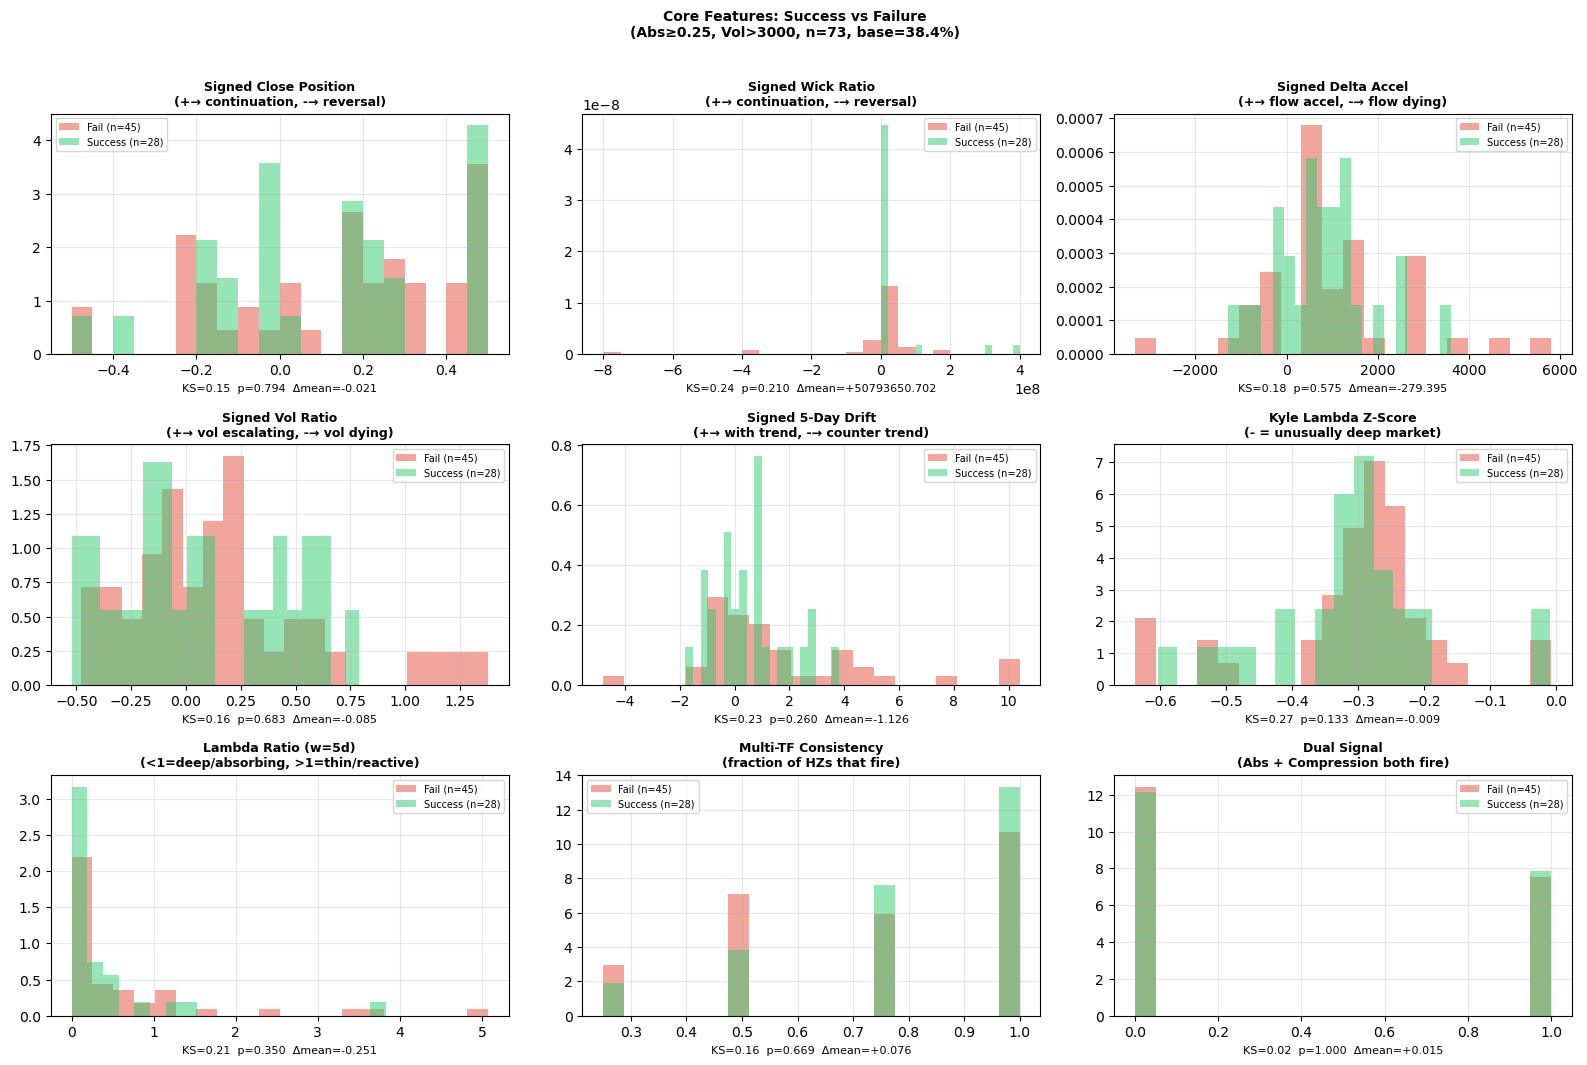


Core Feature Separation (KS test, sorted by KS stat):
           feature  ks_stat  ks_pval  mean_success     mean_fail     mean_diff
     lambda_zscore 0.269048 0.133306 -3.073758e-01 -2.985853e-01 -8.790516e-03
 signed_wick_ratio 0.243651 0.210197  2.857143e+07 -2.222222e+07  5.079365e+07
    signed_drift_5 0.230952 0.260435  5.142857e-01  1.640000e+00 -1.125714e+00
      lambda_ratio 0.212698 0.350124  3.808822e-01  6.317125e-01 -2.508303e-01
signed_delta_accel 0.176984 0.574647  8.004048e+02  1.079800e+03 -2.793952e+02
    tf_consistency 0.163492 0.669021  8.035714e-01  7.277778e-01  7.579365e-02
  signed_vol_ratio 0.161905 0.683091  6.832749e-02  1.531005e-01 -8.477298e-02
  signed_close_pos 0.145238 0.794364  1.164605e-01  1.371944e-01 -2.073389e-02
       dual_signal 0.015079 1.000000  3.928571e-01  3.777778e-01  1.507937e-02

════════════════════════════════════════════════════════════
SECTION B — RV RATIO COMBINATIONS (all num/den window pairs)
  Numerator  windows: [3, 5, 10]

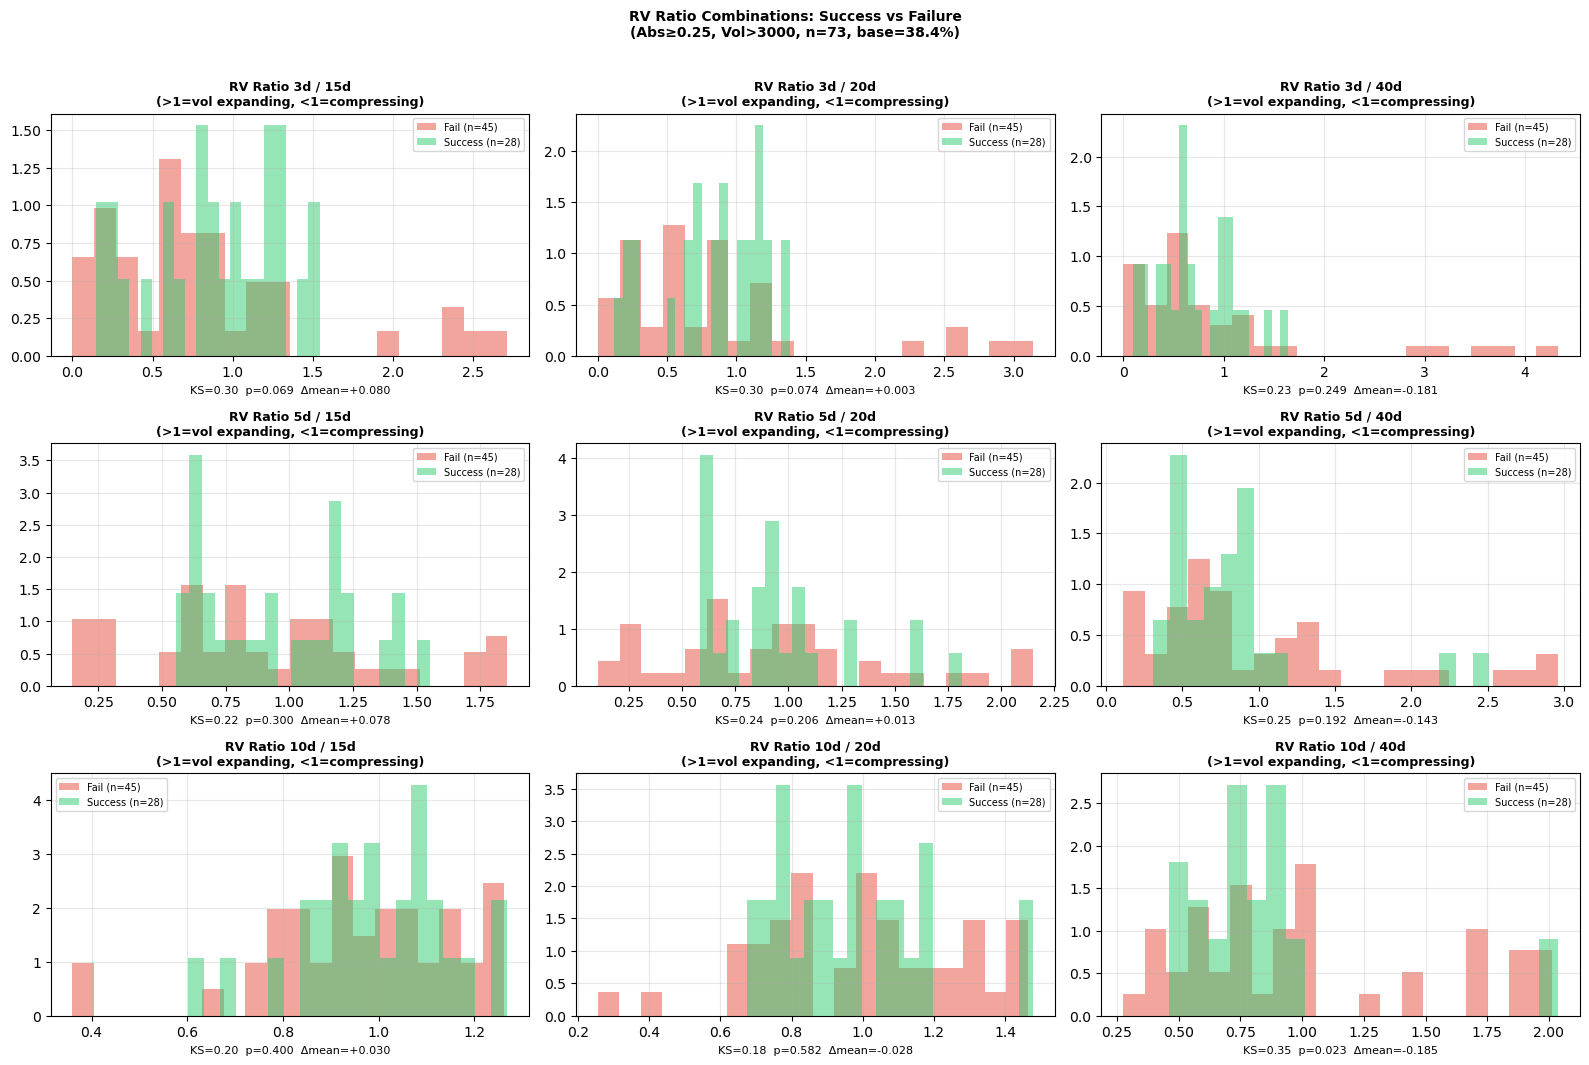


RV Ratio Separation (KS test, sorted by KS stat):
         feature  ks_stat  ks_pval  mean_success  mean_fail  mean_diff
rv_ratio_10d_40d 0.346032 0.022930      0.831765   1.016859  -0.185094
 rv_ratio_3d_15d 0.300794 0.068523      0.888054   0.808493   0.079562
 rv_ratio_3d_20d 0.296825 0.073820      0.845396   0.842451   0.002946
 rv_ratio_5d_40d 0.248413 0.192175      0.824906   0.967466  -0.142559
 rv_ratio_5d_20d 0.244444 0.205683      0.937653   0.924154   0.013499
 rv_ratio_3d_40d 0.234127 0.249371      0.724713   0.905825  -0.181112
 rv_ratio_5d_15d 0.222222 0.300364      0.966456   0.888927   0.077530
rv_ratio_10d_15d 0.203968 0.399811      0.991008   0.961364   0.029643
rv_ratio_10d_20d 0.176190 0.581922      0.965625   0.993280  -0.027655

  → Best RV combo: rv_ratio_10d_40d  KS=0.346

── ALL FEATURES combined (sorted by KS stat) ──
           feature  ks_stat  ks_pval     mean_diff
  rv_ratio_10d_40d 0.346032 0.022930 -1.850941e-01
   rv_ratio_3d_15d 0.300794 0.068523  7.9

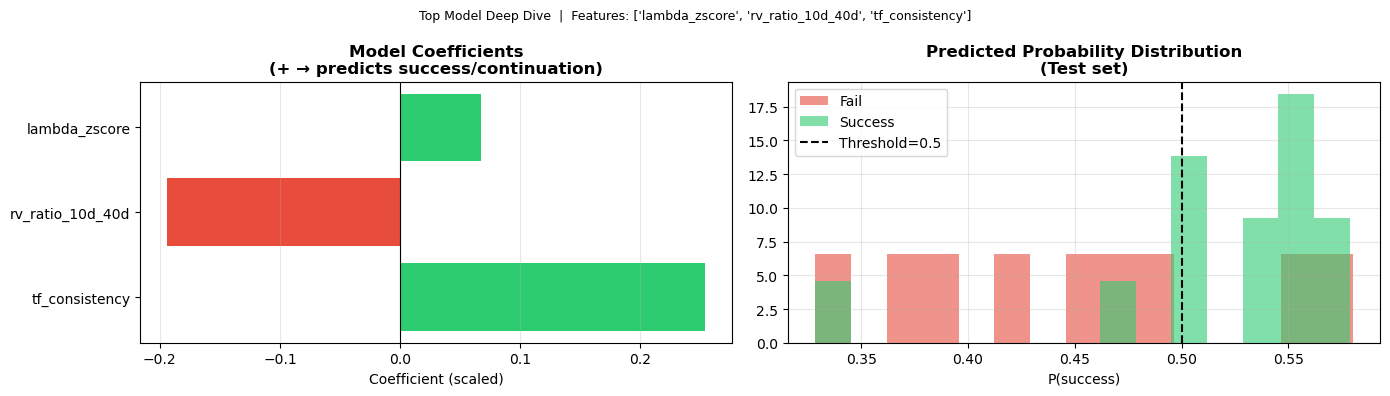


  Coefficients (sorted by |coef|):
         feature  coefficient
  tf_consistency     0.254015
rv_ratio_10d_40d    -0.193957
   lambda_zscore     0.067633


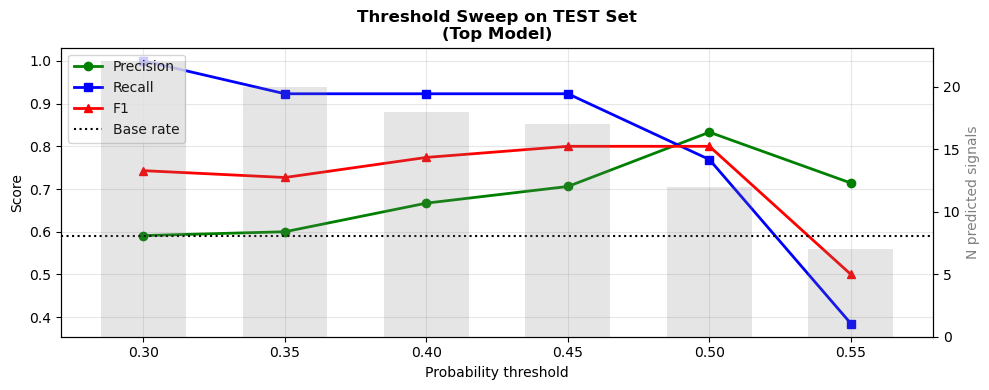


  Threshold Sweep Table (TEST):
 threshold  N_predicted  precision  recall    f1
      0.30           22      0.591   1.000 0.743
      0.35           20      0.600   0.923 0.727
      0.40           18      0.667   0.923 0.774
      0.45           17      0.706   0.923 0.800
      0.50           12      0.833   0.769 0.800
      0.55            7      0.714   0.385 0.500
════════════════════════════════════════════════════════════
BUY vs SELL ABSORPTION SPLIT
════════════════════════════════════════════════════════════

  BUY ABSORPTION  n=35  success=14 (40.0%)  fail=21
           feature  mean_success     mean_fail          diff  ks_stat  p_value
  rv_ratio_10d_40d        0.7352  1.161700e+00 -4.265000e-01    0.667    0.001
 signed_wick_ratio        0.3622 -8.095238e+07  8.095238e+07    0.405    0.105
signed_delta_accel      931.5952  1.469714e+03 -5.381190e+02    0.333    0.269
     lambda_zscore       -0.2806 -2.519000e-01 -2.860000e-02    0.310    0.350
    signed_drift_5       

In [11]:

# ═══════════════════════════════════════════════════════════════════════════════
# CELL 1 — SETUP & IMPORTS
# ═══════════════════════════════════════════════════════════════════════════════

import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, r"C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents")

import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_score, recall_score, f1_score
from itertools import combinations

from market_analysis.config import (
    PRODUCTS, FRONT_N, OHLC_START_DATE, OHLC_END_DATE, ABSORPTION, COMPRESSION
)
from market_analysis.data.ohlc import getData_OHLC_v2, fetch_ohlc_1d, get_ohlc_for_horizon
from market_analysis.utils.contracts import (
    MONTH_CODES, next_n_contract_months, get_front_instruments, fmt_contract
)
from market_analysis.signals.absorption.calculate import calculate_absorption
from market_analysis.signals.absorption.label import label_absorption
from market_analysis.signals.compression.calculate import calculate_compression

# ── Constants ──────────────────────────────────────────────────────────────────
PRODUCT_CODE      = "SM"
TICK_SIZE         = PRODUCTS[PRODUCT_CODE]["tick_size"]          # 0.1
ABS_THRESHOLD     = 0.25    # absorption_strength filter
COMP_THRESHOLD    = 0.30    # compression_score filter
VOLUME_MIN        = 3000    # ignore bars with total volume below this
HORIZONS          = ["1d", "2d", "3d", "5d"]
TODAY             = datetime.date.today()

# Label params (from your best sweep row)
REQUIRED_MOVE_TICKS = 5     # 5 × tick = 0.5 pts
SL_LOOKBACK         = 10
FORWARD_DAYS        = 10

# ── OHLC fetch window per instrument ─────────────────────────────────────────
# Each spread's data starts 7 months before the front-leg's expiry month.
# e.g. SMZ26-SMF27  → front leg = Dec 2026 → start = 2026-05-01
MONTHS_BEFORE_EXPIRY = 7

# ── RV Ratio config ──────────────────────────────────────────────────────────
# All combinations of (numerator_window, denominator_window) will be computed
# as separate features rv_ratio_{N}d_{D}d and each will get its own plot.
# Convention: short_window / long_window  → >1 = vol expanding, <1 = compressing
RV_NUMERATOR_WINDOWS   = [3, 5, 10]      # short lookback options (days)
RV_DENOMINATOR_WINDOWS = [15, 20, 40]    # long  lookback options (days)

# ── Kyle Lambda z-score window ───────────────────────────────────────────────
# Rolling window (in bars) used to compute the mean and std of lambda_t
# for the z-score normalisation. Larger = more stable baseline, slower to adapt.
LAMBDA_ZSCORE_WINDOW: int = 60

# ── Kyle Lambda ratio window ───────────────────────────────────────────────
# lambda_ratio = lambda_t / mean(lambda_{t-LAMBDA_RATIO_WINDOW : t-1})
# Measures how current price-impact compares to recent average depth.
# < 1  → market currently harder to move than usual (deep, absorbing flow)
# > 1  → market thinner than usual (each unit of delta moves price more)
LAMBDA_RATIO_WINDOW: int = 5     # how many past bars to average for the denominator
# ─────────────────────────────────────────────────────────────────────────────

print("✅ Setup complete")
print(f"   Product       : {PRODUCT_CODE}  tick={TICK_SIZE}")
print(f"   Abs threshold : {ABS_THRESHOLD}   Comp threshold: {COMP_THRESHOLD}")
print(f"   Volume filter : >{VOLUME_MIN}    Forward days: {FORWARD_DAYS}")
print(f"   Today         : {TODAY}")
print(f"   Fetch window  : {MONTHS_BEFORE_EXPIRY} months before front-leg expiry")
print(f"   RV numerators : {RV_NUMERATOR_WINDOWS}")
print(f"   RV denominators: {RV_DENOMINATOR_WINDOWS}")
print(f"   Lambda zscore window : {LAMBDA_ZSCORE_WINDOW}d")
print(f"   Lambda ratio  window : {LAMBDA_RATIO_WINDOW}d")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 2 — INSTRUMENT SELECTION (front 4 + recently expired spreads)
# ═══════════════════════════════════════════════════════════════════════════════

def get_expired_spreads(product_code: str, n_expired: int = 3) -> list[str]:
    """
    Return the last `n_expired` calendar-consecutive spread pairs that expired
    before today. Uses the same traded_months list from config.
    """
    product  = PRODUCTS[product_code]
    traded   = sorted(product["traded_months"])
    prefix   = product["api_prefix"]

    # walk backwards from today to collect recent contract months
    y, m     = TODAY.year, TODAY.month
    collected = []
    while len(collected) < n_expired + 4:   # collect extra buffer
        m -= 1
        if m < 1:
            m = 12; y -= 1
        if m in traded:
            collected.append((y, m))

    collected.reverse()   # chronological order

    pairs = []
    for i in range(len(collected) - 1):
        front = fmt_contract(prefix, *collected[i])
        back  = fmt_contract(prefix, *collected[i + 1])
        pairs.append(f"{front}-{back}")

    # take the most recent n_expired pairs
    return pairs[-n_expired:]


def instr_fetch_start(instrument: str, months_before: int = MONTHS_BEFORE_EXPIRY) -> str:
    """
    Derive the OHLC fetch start date for a spread instrument.

    Logic: parse the front-leg contract → find its expiry month (year, month)
           → subtract `months_before` calendar months → return "YYYY-MM-01".

    Example:
        "SMZ26-SMF27"  → front leg SMZ26 → Dec 2026
                       → 7 months before Dec = May 2026
                       → start = "2026-05-01"
    """
    import re
    # Reverse MONTH_CODES so we can go from letter → month number
    CODE_TO_MONTH = {v: k for k, v in MONTH_CODES.items()}

    front_leg = instrument.split("-")[0]          # e.g. "SMZ26"
    m_obj     = re.match(r"^[A-Za-z]+([A-Z])(\d{2})$", front_leg)
    if not m_obj:
        # Fallback: use global OHLC_START_DATE if we can't parse
        return OHLC_START_DATE

    month_code = m_obj.group(1)                   # e.g. "Z"
    year_2dig  = int(m_obj.group(2))              # e.g. 26
    year       = 2000 + year_2dig                 # e.g. 2026
    month      = CODE_TO_MONTH.get(month_code, 1) # e.g. 12 (December)

    # subtract months_before months
    start_month = month - months_before
    start_year  = year
    while start_month < 1:
        start_month += 12
        start_year  -= 1

    return f"{start_year}-{start_month:02d}-01"


# Front 4 spreads starting from today
front_4 = get_front_instruments(PRODUCT_CODE, "spread",
                                reference_date=TODAY, front_n=4)

# ~3 recently expired spreads for extra data
expired_3 = get_expired_spreads(PRODUCT_CODE, n_expired=3)

ALL_INSTRUMENTS = expired_3 + front_4

print("═" * 60)
print("INSTRUMENTS SELECTED")
print("═" * 60)
print(f"  Expired spreads : {expired_3}")
print(f"  Front 4 spreads : {front_4}")
print(f"  Total           : {len(ALL_INSTRUMENTS)} instruments")
print()
print("  Derived fetch windows (7 months before front-leg expiry):")
for instr in ALL_INSTRUMENTS:
    print(f"    {instr:22s}  start={instr_fetch_start(instr)}")
print("═" * 60)


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 3 — FETCH, SCORE (absorption + compression) FOR ALL INSTRUMENTS
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("FETCHING & SCORING OHLC DATA")
print("═" * 60)

# Store per-instrument scored 1D DataFrames (before aggregation)
scored_1d = {}      # {instrument: df_with_absorption_1d}
scored_nd = {}      # {instrument: {horizon: df}}

for instr in ALL_INSTRUMENTS:
    print(f"\n  ▸ {instr}")

    # Per-instrument fetch window: 7 months before front-leg expiry
    instr_start = instr_fetch_start(instr)
    print(f"    fetch_start={instr_start}")

    # --- 1D fetch & absorption score ---
    df1d = fetch_ohlc_1d(instr, PRODUCT_CODE, getData_OHLC_v2,
                          start_date=instr_start, end_date=OHLC_END_DATE)
    if df1d is None or len(df1d) < 70:
        print(f"    [SKIP] not enough data (rows={len(df1d) if df1d is not None else 0})")
        continue

    df1d_abs  = calculate_absorption(df1d, window=60,
                                      tick_size=TICK_SIZE, strength_threshold=ABS_THRESHOLD)
    df1d_abs  = label_absorption(df1d_abs, tick=TICK_SIZE,
                                  required_move_ticks=REQUIRED_MOVE_TICKS,
                                  sl_lookback=SL_LOOKBACK,
                                  forward_days=FORWARD_DAYS)
    scored_1d[instr] = df1d_abs

    # --- compression on 1D ---
    df1d_comp, _ = calculate_compression(df1d.copy(),
                                          compression_threshold=COMP_THRESHOLD)

    # merge compression_score into absorption df by Date
    comp_merge = df1d_comp[["Date", "compression_score"]].copy()
    comp_merge["Date"] = pd.to_datetime(comp_merge["Date"]).dt.strftime("%Y-%m-%d")
    df1d_abs["Date"]   = pd.to_datetime(df1d_abs["Date"]).dt.strftime("%Y-%m-%d")
    df1d_abs = df1d_abs.merge(comp_merge.rename(columns={"compression_score": "comp_score_1d"}),
                               on="Date", how="left")
    scored_1d[instr] = df1d_abs

    # --- multi-horizon absorption scores (for consistency feature) ---
    scored_nd[instr] = {}
    for hz in HORIZONS:
        from market_analysis.data.ohlc import _aggregate_trailing
        from market_analysis.config import HORIZON_BARS
        n_bars = HORIZON_BARS[hz]
        dfh    = df1d.copy() if n_bars == 1 else _aggregate_trailing(df1d.copy(), n_bars)
        if dfh is None or len(dfh) < 65:
            continue
        dfh_sc = calculate_absorption(dfh, window=60,
                                       tick_size=TICK_SIZE, strength_threshold=ABS_THRESHOLD)
        scored_nd[instr][hz] = dfh_sc
    print(f"    rows={len(df1d_abs)}  "
          f"abs_events={(df1d_abs['absorption_strength'] > ABS_THRESHOLD).sum()}")

print("\n✅ Scoring complete")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 4 — FEATURE ENGINEERING
# (all past-only, no forward leakage, computed at bar t)
# ═══════════════════════════════════════════════════════════════════════════════

def build_resolution_features(df: pd.DataFrame,
                                scored_nd_for_instr: dict,
                                tick: float = 0.1,
                                epsilon: float = 1e-9) -> pd.DataFrame:
    """
    Add Stage-2 characterization features to a scored+labeled 1D DataFrame.
    All features use only [t-N : t] — strictly past-only.
    """
    d = df.copy().sort_values("Date").reset_index(drop=True)

    # ── 1. Intrabar: close position within bar ──────────────────────────────
    d["close_pos"] = (d["close"] - d["low"]) / (d["high"] - d["low"] + epsilon)
    # Signed for direction:
    #   BUY  absorption → reversal = price drops → close near LOW is BAD for buyers
    #     close_pos LOW (< 0.3) → sellers won intrabar → reversal hint → signed negative
    #   SELL absorption → reversal = price rises → close near HIGH is BAD for sellers
    # Convention: signed_close_pos > 0 → continuation, < 0 → reversal
    d["signed_close_pos"] = np.where(
        d["absorption_direction"] == "BUY",
        d["close_pos"] - 0.5,          # BUY: high → continuation (+), low → reversal (-)
        0.5 - d["close_pos"],          # SELL: low → continuation (+), high → reversal (-)
    )

    # ── 2. Intrabar: wick asymmetry ──────────────────────────────────────────
    d["upper_wick"] = d["high"] - d[["open", "close"]].max(axis=1)
    d["lower_wick"] = d[["open", "close"]].min(axis=1) - d["low"]
    d["wick_ratio"] = d["upper_wick"] / (d["lower_wick"] + epsilon)
    # BUY absorption: large upper wick → price pushed up but rejected → reversal
    # SELL absorption: large lower wick → price tested down but rejected → reversal
    # Sign: negative → reversal hint
    d["signed_wick_ratio"] = np.where(
        d["absorption_direction"] == "BUY",
        -(d["wick_ratio"] - 1.0),       # BUY: wick_ratio >> 1 → reversal → negative
        (d["wick_ratio"] - 1.0),        # SELL: wick_ratio << 1 → reversal → positive issue
    )
    # simpler: just keep raw wick_ratio and let model learn direction via dir dummy

    # ── 3. Delta ratio (how one-sided) ───────────────────────────────────────
    d["delta_ratio"] = d["buyvolume"] / (d["sellvolume"] + epsilon)

    # ── 4. Delta momentum: is aggressive flow accel or dying? ────────────────
    d["delta_accel"] = d["delta"] - d["delta"].shift(1).rolling(3, min_periods=1).mean()
    # Sign to success: BUY absorption — if delta_accel positive → buyers not exhausted → continuation
    # SELL absorption — if delta_accel negative (sell delta growing) → sellers not exhausted → continuation
    d["signed_delta_accel"] = np.where(
        d["absorption_direction"] == "BUY",
        d["delta_accel"],
        -d["delta_accel"],
    )

    # ── 5. Volume deceleration ───────────────────────────────────────────────
    vol_roll5 = d["volume"].shift(1).rolling(5, min_periods=2).mean()
    d["vol_ratio"] = d["volume"] / (vol_roll5 + epsilon)
    # vol_ratio < 1 → volume drying up → exhaustion → reversal (negative for our sign)
    # signed: positive → continuation hint
    d["signed_vol_ratio"] = d["vol_ratio"] - 1.0   # >0 = escalating, <0 = dying

    # ── 6. Price drift into absorption ───────────────────────────────────────
    d["drift_5"] = (d["close"] - d["close"].shift(5)) / (5 * tick + epsilon)
    # BUY absorption after falling prices (drift_5 < 0) → counter-trend buyers → reversal likely
    # SELL absorption after rising prices (drift_5 > 0) → counter-trend sellers → reversal likely
    # Sign: same direction as absorption = continuation, opposite = reversal
    d["signed_drift_5"] = np.where(
        d["absorption_direction"] == "BUY",
        d["drift_5"],          # rising drift + BUY absorption → continuation
        -d["drift_5"],         # falling drift + SELL absorption → continuation
    )

    # ── 7. Kyle Lambda: market depth anomaly ─────────────────────────────────
    price_change = d["close"].diff().abs()
    abs_delta    = d["delta"].abs()
    d["lambda_t"] = price_change / (abs_delta + epsilon)

    # lambda_ratio: current vs recent average depth
    #   = lambda_t / mean(lambda[t-LAMBDA_RATIO_WINDOW : t-1])
    #   < 1 → market deeper than usual → flow absorbed without moving price much
    #   > 1 → market thinner than usual → each delta unit moves price more
    _lam_ratio_mp          = max(2, LAMBDA_RATIO_WINDOW // 2)
    d["lambda_ratio_avg"]  = (
        d["lambda_t"].shift(1)
        .rolling(LAMBDA_RATIO_WINDOW, min_periods=_lam_ratio_mp)
        .mean()
    )
    d["lambda_ratio"] = d["lambda_t"] / (d["lambda_ratio_avg"] + epsilon)

    # lambda_zscore: z-normalised over a longer baseline window
    _lam_mp    = max(10, LAMBDA_ZSCORE_WINDOW // 3)
    lam_mean   = d["lambda_t"].shift(1).rolling(LAMBDA_ZSCORE_WINDOW, min_periods=_lam_mp).mean()
    lam_std    = d["lambda_t"].shift(1).rolling(LAMBDA_ZSCORE_WINDOW, min_periods=_lam_mp).std()
    d["lambda_zscore"] = (d["lambda_t"] - lam_mean) / (lam_std + epsilon)
    # very negative lambda_zscore = unusually deep market = strong absorption event
    # (window controlled by LAMBDA_ZSCORE_WINDOW; ratio window by LAMBDA_RATIO_WINDOW)

    # ── 8. Realized volatility ratios (all configured combinations) ──────────
    # Config lists RV_NUMERATOR_WINDOWS and RV_DENOMINATOR_WINDOWS (defined in Cell 1).
    # For each (num_w, den_w) pair where num_w < den_w we compute:
    #   rv_ratio_{num_w}d_{den_w}d = rv(num_w) / rv(den_w)
    # >1 = vol expanding (short > long)  |  <1 = vol compressing
    log_ret = np.log(d["close"].replace(0, np.nan) / d["close"].shift(1).replace(0, np.nan))

    # Pre-compute each unique window std once
    all_windows = sorted(set(RV_NUMERATOR_WINDOWS + RV_DENOMINATOR_WINDOWS))
    rv_cache = {}
    for w in all_windows:
        mp = max(2, w // 2)
        rv_cache[w] = log_ret.rolling(w, min_periods=mp).std()

    for num_w in RV_NUMERATOR_WINDOWS:
        for den_w in RV_DENOMINATOR_WINDOWS:
            if num_w >= den_w:
                continue   # skip: numerator must be shorter than denominator
            col = f"rv_ratio_{num_w}d_{den_w}d"
            d[col] = rv_cache[num_w] / (rv_cache[den_w] + epsilon)

    # Keep the original rv_ratio name pointing at the first valid combo
    # so downstream code that references "rv_ratio" still works
    _first_num = next((n for n in RV_NUMERATOR_WINDOWS for den in RV_DENOMINATOR_WINDOWS if n < den), None)
    _first_den = next((den for n in RV_NUMERATOR_WINDOWS for den in RV_DENOMINATOR_WINDOWS if n < den), None)
    if _first_num is not None:
        d["rv_ratio"] = d[f"rv_ratio_{_first_num}d_{_first_den}d"]
    # rv_ratio > 1 → short-window vol > long-window vol → expanding (high-vol regime)
    # rv_ratio < 1 → short-window vol < long-window vol → compressing (quiet)

    # ── 9. Multi-timeframe consistency ───────────────────────────────────────
    # For each bar date, check if absorption_strength > ABS_THRESHOLD on other horizons
    d["Date_str"] = pd.to_datetime(d["Date"]).dt.strftime("%Y-%m-%d")
    tf_scores = {hz: {} for hz in HORIZONS}
    for hz, dfh in scored_nd_for_instr.items():
        if dfh is None or "absorption_strength" not in dfh.columns:
            continue
        dfh_copy = dfh.copy()
        dfh_copy["Date_str"] = pd.to_datetime(dfh_copy["Date"]).dt.strftime("%Y-%m-%d")
        for _, row in dfh_copy.iterrows():
            tf_scores[hz][row["Date_str"]] = row["absorption_strength"]

    consistency_vals = []
    for _, row in d.iterrows():
        date_key = row["Date_str"]
        fires = [
            1 if tf_scores[hz].get(date_key, 0) > ABS_THRESHOLD else 0
            for hz in HORIZONS
        ]
        consistency_vals.append(np.mean(fires))
    d["tf_consistency"] = consistency_vals

    # ── 10. Dual signal: both absorption AND compression fire ─────────────────
    d["dual_signal"] = (
        (d["absorption_strength"] > ABS_THRESHOLD) &
        (d.get("comp_score_1d", pd.Series(0, index=d.index)).fillna(0) > COMP_THRESHOLD)
    ).astype(float)

    # ── 11. Direction dummy (BUY=1, SELL=0) ──────────────────────────────────
    d["is_buy_absorption"] = (d["absorption_direction"] == "BUY").astype(float)

    return d


# Apply feature engineering to all instruments
print("═" * 60)
print("FEATURE ENGINEERING")
print("═" * 60)

featured = {}
for instr, df in scored_1d.items():
    nd_for_instr = scored_nd.get(instr, {})
    featured[instr] = build_resolution_features(df, nd_for_instr, tick=TICK_SIZE)
    print(f"  ✓ {instr}  columns={len(featured[instr].columns)}")

print("✅ Feature engineering complete")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 5 — POOL ABSORPTION EVENTS & SUMMARY
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("POOLING ABSORPTION EVENTS (volume > 3000, strength > 0.25)")
print("═" * 60)

FEATURE_COLS = [
    "signed_close_pos",
    "signed_wick_ratio",
    "signed_delta_accel",
    "signed_vol_ratio",
    "signed_drift_5",
    "lambda_zscore",
    "rv_ratio",
    "tf_consistency",
    "dual_signal",
    "is_buy_absorption",
    # raw (unsigned) versions also included for exploration
    "close_pos",
    "wick_ratio",
    "vol_ratio",
    "delta_ratio",
    "lambda_ratio",
]

all_events = []
for instr, df in featured.items():
    mask = (
        (df["absorption_strength"] > ABS_THRESHOLD) &
        (df["volume"] > VOLUME_MIN) &
        (df["sl_success"].notna())
    )
    subset = df[mask].copy()
    subset["instrument"] = instr
    all_events.append(subset)

if not all_events:
    print("❌ No events found — check thresholds or data fetch")
else:
    pool = pd.concat(all_events, ignore_index=True)
    pool = pool.sort_values("Date").reset_index(drop=True)

    n_total   = len(pool)
    n_success = int(pool["sl_success"].sum())
    n_fail    = int((pool["sl_success"] == 0).sum())
    base_rate = n_success / n_total if n_total > 0 else 0

    print(f"\n  Total absorption events : {n_total}")
    print(f"  Success (reversal)      : {n_success}  ({100*base_rate:.1f}%)")
    print(f"  Failure                 : {n_fail}")
    print(f"\n  Per instrument:")
    for instr in pool["instrument"].unique():
        sub = pool[pool["instrument"] == instr]
        s = int(sub["sl_success"].sum())
        print(f"    {instr:20s}  n={len(sub):3d}  success={s}")
    print()

    # ensure features are numeric
    for fc in FEATURE_COLS:
        if fc in pool.columns:
            pool[fc] = pd.to_numeric(pool[fc], errors="coerce")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 6 — DISTRIBUTION PLOTS: Feature separation (success vs fail)
# ═══════════════════════════════════════════════════════════════════════════════

# ── Helper: plot a set of features and return separation stats ────────────────
def _plot_feature_grid(pool_df, feature_list, title_prefix=""):
    """
    Plots histograms for each (feat, label) tuple in feature_list.
    Returns a list of separation stat dicts.
    """
    suc = pool_df[pool_df["sl_success"] == 1]
    fai = pool_df[pool_df["sl_success"] == 0]
    stats_out = []

    n_cols = 3
    n_rows = (len(feature_list) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3.5))
    axes = axes.flatten()

    for ax, (feat, label) in zip(axes, feature_list):
        if feat not in pool_df.columns:
            ax.set_visible(False); continue
        s_vals = suc[feat].dropna()
        f_vals = fai[feat].dropna()
        if len(s_vals) == 0 or len(f_vals) == 0:
            ax.set_visible(False); continue

        ax.hist(f_vals, bins=20, alpha=0.5, color="#e74c3c", density=True,
                label=f"Fail (n={len(f_vals)})")
        ax.hist(s_vals, bins=20, alpha=0.5, color="#2ecc71", density=True,
                label=f"Success (n={len(s_vals)})")
        ks_stat, ks_pval = stats.ks_2samp(s_vals, f_vals)
        mean_diff = s_vals.mean() - f_vals.mean()
        ax.set_title(label, fontsize=9, fontweight="bold")
        ax.set_xlabel(f"KS={ks_stat:.2f}  p={ks_pval:.3f}  Δmean={mean_diff:+.3f}", fontsize=8)
        ax.legend(fontsize=7); ax.grid(alpha=0.3)
        stats_out.append({"feature": feat, "ks_stat": ks_stat, "ks_pval": ks_pval,
                           "mean_success": s_vals.mean(), "mean_fail": f_vals.mean(),
                           "mean_diff": mean_diff})

    for ax in axes[len(feature_list):]:
        ax.set_visible(False)
    plt.suptitle(f"{title_prefix}\n"
                 f"(Abs≥{ABS_THRESHOLD}, Vol>{VOLUME_MIN}, "
                 f"n={n_total}, base={base_rate:.1%})",
                 fontsize=10, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()
    return stats_out


# ── Section A: core signed features ──────────────────────────────────────────
CORE_PLOT_FEATURES = [
    ("signed_close_pos",   "Signed Close Position\n(+→ continuation, -→ reversal)"),
    ("signed_wick_ratio",  "Signed Wick Ratio\n(+→ continuation, -→ reversal)"),
    ("signed_delta_accel", "Signed Delta Accel\n(+→ flow accel, -→ flow dying)"),
    ("signed_vol_ratio",   "Signed Vol Ratio\n(+→ vol escalating, -→ vol dying)"),
    ("signed_drift_5",     "Signed 5-Day Drift\n(+→ with trend, -→ counter trend)"),
    ("lambda_zscore",      "Kyle Lambda Z-Score\n(- = unusually deep market)"),
    ("lambda_ratio",       f"Lambda Ratio (w={LAMBDA_RATIO_WINDOW}d)\n(<1=deep/absorbing, >1=thin/reactive)"),
    ("tf_consistency",     "Multi-TF Consistency\n(fraction of HZs that fire)"),
    ("dual_signal",        "Dual Signal\n(Abs + Compression both fire)"),
]

print("═" * 60)
print("SECTION A — CORE FEATURE SEPARATION (success vs failure)")
print("═" * 60)
sep_stats = _plot_feature_grid(pool, CORE_PLOT_FEATURES,
                                title_prefix="Core Features: Success vs Failure")

sep_df = pd.DataFrame(sep_stats).sort_values("ks_stat", ascending=False)
print("\nCore Feature Separation (KS test, sorted by KS stat):")
print(sep_df[["feature", "ks_stat", "ks_pval", "mean_success", "mean_fail", "mean_diff"]].to_string(index=False))


# ── Section B: RV Ratio — all window combinations ────────────────────────────
print()
print("═" * 60)
print("SECTION B — RV RATIO COMBINATIONS (all num/den window pairs)")
print(f"  Numerator  windows: {RV_NUMERATOR_WINDOWS}")
print(f"  Denominator windows: {RV_DENOMINATOR_WINDOWS}")
print("═" * 60)

RV_PLOT_FEATURES = []
for num_w in RV_NUMERATOR_WINDOWS:
    for den_w in RV_DENOMINATOR_WINDOWS:
        if num_w >= den_w:
            continue
        col   = f"rv_ratio_{num_w}d_{den_w}d"
        label = (f"RV Ratio {num_w}d / {den_w}d\n"
                 f"(>1=vol expanding, <1=compressing)")
        RV_PLOT_FEATURES.append((col, label))

if RV_PLOT_FEATURES:
    rv_sep_stats = _plot_feature_grid(pool, RV_PLOT_FEATURES,
                                       title_prefix="RV Ratio Combinations: Success vs Failure")
    rv_sep_df = pd.DataFrame(rv_sep_stats).sort_values("ks_stat", ascending=False)
    print("\nRV Ratio Separation (KS test, sorted by KS stat):")
    print(rv_sep_df[["feature", "ks_stat", "ks_pval",
                     "mean_success", "mean_fail", "mean_diff"]].to_string(index=False))
    print(f"\n  → Best RV combo: {rv_sep_df.iloc[0]['feature']}  "
          f"KS={rv_sep_df.iloc[0]['ks_stat']:.3f}")
    # Store best for use in model sweep
    BEST_RV_FEATURE = rv_sep_df.iloc[0]["feature"]
else:
    print("  No valid RV combos (all numerators >= denominators). Check config.")
    BEST_RV_FEATURE = "rv_ratio"

# Combined separation table (all features)
all_sep_df = pd.concat([sep_df, rv_sep_df if RV_PLOT_FEATURES else pd.DataFrame()],
                        ignore_index=True).sort_values("ks_stat", ascending=False)
print("\n── ALL FEATURES combined (sorted by KS stat) ──")
print(all_sep_df[["feature", "ks_stat", "ks_pval", "mean_diff"]].to_string(index=False))
success_events = pool[pool["sl_success"] == 1]
fail_events    = pool[pool["sl_success"] == 0]


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 7 — WALK-FORWARD TRAIN / TEST SPLIT
# ═══════════════════════════════════════════════════════════════════════════════

pool_sorted = pool.sort_values("Date").reset_index(drop=True)
split_idx   = int(len(pool_sorted) * 0.70)
train_df    = pool_sorted.iloc[:split_idx].copy()
test_df     = pool_sorted.iloc[split_idx:].copy()

print("═" * 60)
print("WALK-FORWARD SPLIT")
print("═" * 60)
print(f"  Train: {len(train_df)} events | {train_df['Date'].min()} → {train_df['Date'].max()}")
print(f"  Test : {len(test_df)} events  | {test_df['Date'].min()} → {test_df['Date'].max()}")
print(f"  Train base rate: {train_df['sl_success'].mean():.1%}")
print(f"  Test  base rate: {test_df['sl_success'].mean():.1%}")


def get_Xy(df: pd.DataFrame, feats: list[str]):
    """Extract X, y matrices from a pool DataFrame, dropping NaN rows."""
    sub  = df[feats + ["sl_success"]].dropna()
    X    = sub[feats].values.astype(float)
    y    = sub["sl_success"].values.astype(int)
    return X, y, sub.index


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 8 — FEATURE COMBO SWEEP (SGD Logistic Regression)
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("FEATURE COMBINATION SWEEP (SGD Logistic Regression)")
print("═" * 60)

# Signed feature candidates (theoretically motivated).
# rv_ratio is replaced by the best-KS combo found in Cell 6 Section B.
SIGNED_FEATS = [
    "signed_close_pos",
    "signed_delta_accel",
    "signed_vol_ratio",
    "signed_drift_5",
    "lambda_zscore",
    "lambda_ratio",        # depth ratio vs recent avg (LAMBDA_RATIO_WINDOW)
    BEST_RV_FEATURE,       # best RV window combo by KS separation
    "tf_consistency",
    "signed_wick_ratio",
]

# Filter to only features that exist and have enough variance
available_feats = [
    f for f in SIGNED_FEATS
    if f in train_df.columns and train_df[f].dropna().std() > 1e-6
]
print(f"  Available features: {available_feats}\n")

# Combos of size 2–6 (theoretically motivated pairs first, then expand)
# Plus one full-feature model
combo_sizes = [2, 3, 4, 5]
combos      = []
for size in combo_sizes:
    combos.extend(list(combinations(available_feats, size)))
# Add full model
combos.append(tuple(available_feats))

print(f"  Total combos to evaluate: {len(combos)}")

def make_sgd_pipeline():
    clf = SGDClassifier(
        loss="log_loss",
        penalty="l2",
        alpha=0.01,
        max_iter=1000,
        tol=1e-4,
        random_state=42,
        class_weight="balanced",
    )
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])


results = []
for combo in combos:
    feats = list(combo)
    X_tr, y_tr, _ = get_Xy(train_df, feats)
    X_te, y_te, _ = get_Xy(test_df,  feats)

    if len(X_tr) < 20 or len(X_te) < 5:
        continue
    if len(np.unique(y_tr)) < 2 or len(np.unique(y_te)) < 2:
        continue

    pipe = make_sgd_pipeline()
    try:
        pipe.fit(X_tr, y_tr)
    except Exception:
        continue

    y_pred_prob = pipe.predict_proba(X_te)[:, 1]
    # Use 0.5 as default threshold
    y_pred = (y_pred_prob >= 0.5).astype(int)

    prec   = precision_score(y_te, y_pred, zero_division=0)
    rec    = recall_score(y_te,    y_pred, zero_division=0)
    f1     = f1_score(y_te,        y_pred, zero_division=0)
    # Lift over base rate
    base   = y_te.mean() if y_te.mean() > 0 else 1e-9
    lift   = prec / base

    results.append({
        "features"  : feats,
        "n_feats"   : len(feats),
        "precision" : round(prec, 4),
        "recall"    : round(rec,  4),
        "f1"        : round(f1,   4),
        "lift"      : round(lift, 4),
        "n_train"   : len(X_tr),
        "n_test"    : len(X_te),
    })

results_df = pd.DataFrame(results).sort_values("precision", ascending=False).reset_index(drop=True)

print("\n  Top 15 combos by Precision on TEST set:")
print("─" * 80)
for i, row in results_df.head(15).iterrows():
    print(f"  [{i+1:2d}] n_feats={row['n_feats']}  "
          f"P={row['precision']:.3f}  R={row['recall']:.3f}  "
          f"F1={row['f1']:.3f}  Lift={row['lift']:.2f}")
    print(f"       features: {row['features']}")

print(f"\n  Base rate on test: {test_df['sl_success'].mean():.1%}")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 9 — TOP MODEL DEEP DIVE (threshold sweep + coefficients)
# ═══════════════════════════════════════════════════════════════════════════════

# Pick top combo by precision
best_row   = results_df.iloc[0]
best_feats = best_row["features"]
print("═" * 60)
print(f"TOP MODEL ANALYSIS")
print("═" * 60)
print(f"  Features: {best_feats}")
print(f"  Train n={best_row['n_train']}  Test n={best_row['n_test']}")
print(f"  Precision={best_row['precision']:.3f}  Recall={best_row['recall']:.3f}  "
      f"F1={best_row['f1']:.3f}  Lift={best_row['lift']:.2f}")

X_tr, y_tr, _ = get_Xy(train_df, best_feats)
X_te, y_te, _ = get_Xy(test_df,  best_feats)

best_pipe = make_sgd_pipeline()
best_pipe.fit(X_tr, y_tr)
y_prob_te = best_pipe.predict_proba(X_te)[:, 1]

# ── Coefficients ──────────────────────────────────────────────────────────────
coefs = best_pipe.named_steps["clf"].coef_[0]
coef_df = pd.DataFrame({
    "feature": best_feats,
    "coefficient": coefs,
    "abs_coef": np.abs(coefs)
}).sort_values("abs_coef", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Coefficient bar chart
ax = axes[0]
colors = ["#2ecc71" if c > 0 else "#e74c3c" for c in coef_df["coefficient"]]
ax.barh(coef_df["feature"], coef_df["coefficient"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Model Coefficients\n(+ → predicts success/continuation)", fontweight="bold")
ax.set_xlabel("Coefficient (scaled)")
ax.grid(alpha=0.3, axis="x")

# Probability distribution by outcome
ax = axes[1]
ax.hist(y_prob_te[y_te == 0], bins=15, alpha=0.6, color="#e74c3c", density=True, label="Fail")
ax.hist(y_prob_te[y_te == 1], bins=15, alpha=0.6, color="#2ecc71", density=True, label="Success")
ax.axvline(0.5, color="black", linestyle="--", label="Threshold=0.5")
ax.set_title("Predicted Probability Distribution\n(Test set)", fontweight="bold")
ax.set_xlabel("P(success)")
ax.legend()
ax.grid(alpha=0.3)

plt.suptitle(f"Top Model Deep Dive  |  Features: {best_feats}", fontsize=9)
plt.tight_layout()
plt.show()

print("\n  Coefficients (sorted by |coef|):")
print(coef_df[["feature", "coefficient"]].to_string(index=False))


# ── Threshold sweep on test set ───────────────────────────────────────────────
thresholds = np.arange(0.30, 0.85, 0.05)
sweep_rows = []
for t in thresholds:
    y_pred_t = (y_prob_te >= t).astype(int)
    n_pred   = y_pred_t.sum()
    if n_pred == 0:
        continue
    p = precision_score(y_te, y_pred_t, zero_division=0)
    r = recall_score(y_te,    y_pred_t, zero_division=0)
    f = f1_score(y_te,        y_pred_t, zero_division=0)
    sweep_rows.append({"threshold": round(t, 2), "N_predicted": n_pred,
                        "precision": round(p, 3), "recall": round(r, 3), "f1": round(f, 3)})

sweep_res = pd.DataFrame(sweep_rows)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(sweep_res["threshold"], sweep_res["precision"], "g-o", label="Precision", linewidth=2)
ax.plot(sweep_res["threshold"], sweep_res["recall"],    "b-s", label="Recall",    linewidth=2)
ax.plot(sweep_res["threshold"], sweep_res["f1"],        "r-^", label="F1",        linewidth=2)
ax2 = ax.twinx()
ax2.bar(sweep_res["threshold"], sweep_res["N_predicted"], alpha=0.2, color="gray",
        width=0.03, label="N predicted")
ax2.set_ylabel("N predicted signals", color="gray")
ax.axhline(test_df["sl_success"].mean(), color="black", linestyle=":", label=f"Base rate")
ax.set_xlabel("Probability threshold")
ax.set_ylabel("Score")
ax.set_title("Threshold Sweep on TEST Set\n(Top Model)", fontweight="bold")
ax.legend(loc="upper left"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\n  Threshold Sweep Table (TEST):")
print(sweep_res.to_string(index=False))


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 10 — BUY vs SELL ABSORPTION SPLIT ANALYSIS
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("BUY vs SELL ABSORPTION SPLIT")
print("═" * 60)

for direction in ["BUY", "SELL"]:
    sub = pool[pool["absorption_direction"] == direction].copy()
    n   = len(sub)
    if n < 15:
        print(f"  {direction}: too few events ({n}), skipping")
        continue

    s_sub = sub[sub["sl_success"] == 1]
    f_sub = sub[sub["sl_success"] == 0]
    print(f"\n  {direction} ABSORPTION  n={n}  "
          f"success={len(s_sub)} ({100*len(s_sub)/n:.1f}%)  "
          f"fail={len(f_sub)}")

    feat_means = []
    for feat in available_feats:
        if feat not in sub.columns:
            continue
        sv = s_sub[feat].dropna()
        fv = f_sub[feat].dropna()
        if len(sv) < 3 or len(fv) < 3:
            continue
        ks, pv = stats.ks_2samp(sv, fv)
        feat_means.append({
            "feature": feat,
            "mean_success": round(sv.mean(), 4),
            "mean_fail"   : round(fv.mean(), 4),
            "diff"        : round(sv.mean() - fv.mean(), 4),
            "ks_stat"     : round(ks, 3),
            "p_value"     : round(pv, 3),
        })

    feat_means_df = pd.DataFrame(feat_means).sort_values("ks_stat", ascending=False)
    print(feat_means_df.to_string(index=False))

    # Train direction-specific model if enough data
    sub_sorted = sub.sort_values("Date").reset_index(drop=True)
    sp = int(len(sub_sorted) * 0.70)
    tr_d = sub_sorted.iloc[:sp]
    te_d = sub_sorted.iloc[sp:]
    if len(tr_d) < 15 or len(te_d) < 5:
        print(f"  [{direction}] Not enough data for direction model")
        continue

    X_tr_d, y_tr_d, _ = get_Xy(tr_d, best_feats)
    X_te_d, y_te_d, _ = get_Xy(te_d, best_feats)
    if len(np.unique(y_tr_d)) < 2:
        print(f"  [{direction}] Only one class in train, skipping")
        continue

    pipe_d = make_sgd_pipeline()
    pipe_d.fit(X_tr_d, y_tr_d)
    if len(np.unique(y_te_d)) < 2:
        print(f"  [{direction}] Only one class in test set, skipping metrics")
        continue
    y_pred_d = pipe_d.predict(X_te_d)
    print(f"\n  [{direction}] Direction-specific model (same features):")
    print(f"    Precision={precision_score(y_te_d, y_pred_d, zero_division=0):.3f}  "
          f"Recall={recall_score(y_te_d, y_pred_d, zero_division=0):.3f}  "
          f"F1={f1_score(y_te_d, y_pred_d, zero_division=0):.3f}")
    coefs_d = pipe_d.named_steps["clf"].coef_[0]
    print(f"    Coefficients: " +
          "  ".join(f"{f}={c:+.3f}" for f, c in zip(best_feats, coefs_d)))


print("\n" + "═" * 60)
print("ANALYSIS COMPLETE")
print("═" * 60)


In [12]:
from market_analysis.runner import run_absorption_1h
results = run_absorption_1h("SM", horizons=["1h","2h","4h"])


ImportError: cannot import name 'ABSORPTION_1H' from 'market_analysis.config' (C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\config.py)

In [ ]:
import sys
import warnings
warnings.filterwarnings("ignore")

# Make sure Python knows where your market_analysis folder is
sys.path.insert(0, r"C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents")

from market_analysis.runner import run_absorption_1h

# Run 1H absorption analysis for SM (Soybean Meal)
results_1h = run_absorption_1h(
    product_code="SM",
    front_n=5,           # Number of front spreads/jumbos to analyze
    show_plots=True,     # Show distribution plots inline
    save_outputs=True    # Save results to output/sm/absorption_1h/
)


# try hourly

✅ Setup complete
   Product       : SM  tick=0.1
   Abs threshold : 0.25   Comp threshold: 0.3
   Volume filter : >500    Forward bars: 40
   Today         : 2026-09-21
   Fetch window  : 7 months before front-leg expiry
   RV numerators : [3, 4, 5, 10]
   RV denominators: [15, 20, 40]
   Lambda zscore window : 20d
   Lambda ratio  window : 3d
════════════════════════════════════════════════════════════
INSTRUMENTS SELECTED
════════════════════════════════════════════════════════════
  Expired spreads : ['SMH26-SMK26', 'SMK26-SMN26', 'SMN26-SMQ26']
  Front 4 spreads : ['SMV26-SMZ26', 'SMZ26-SMF27', 'SMF27-SMH27', 'SMH27-SMK27']
  Total           : 7 instruments

  Derived fetch windows (7 months before front-leg expiry):
    SMH26-SMK26             start=2025-08-01
    SMK26-SMN26             start=2025-10-01
    SMN26-SMQ26             start=2025-12-01
    SMV26-SMZ26             start=2026-03-01
    SMZ26-SMF27             start=2026-05-01
    SMF27-SMH27             start=2026-06-01

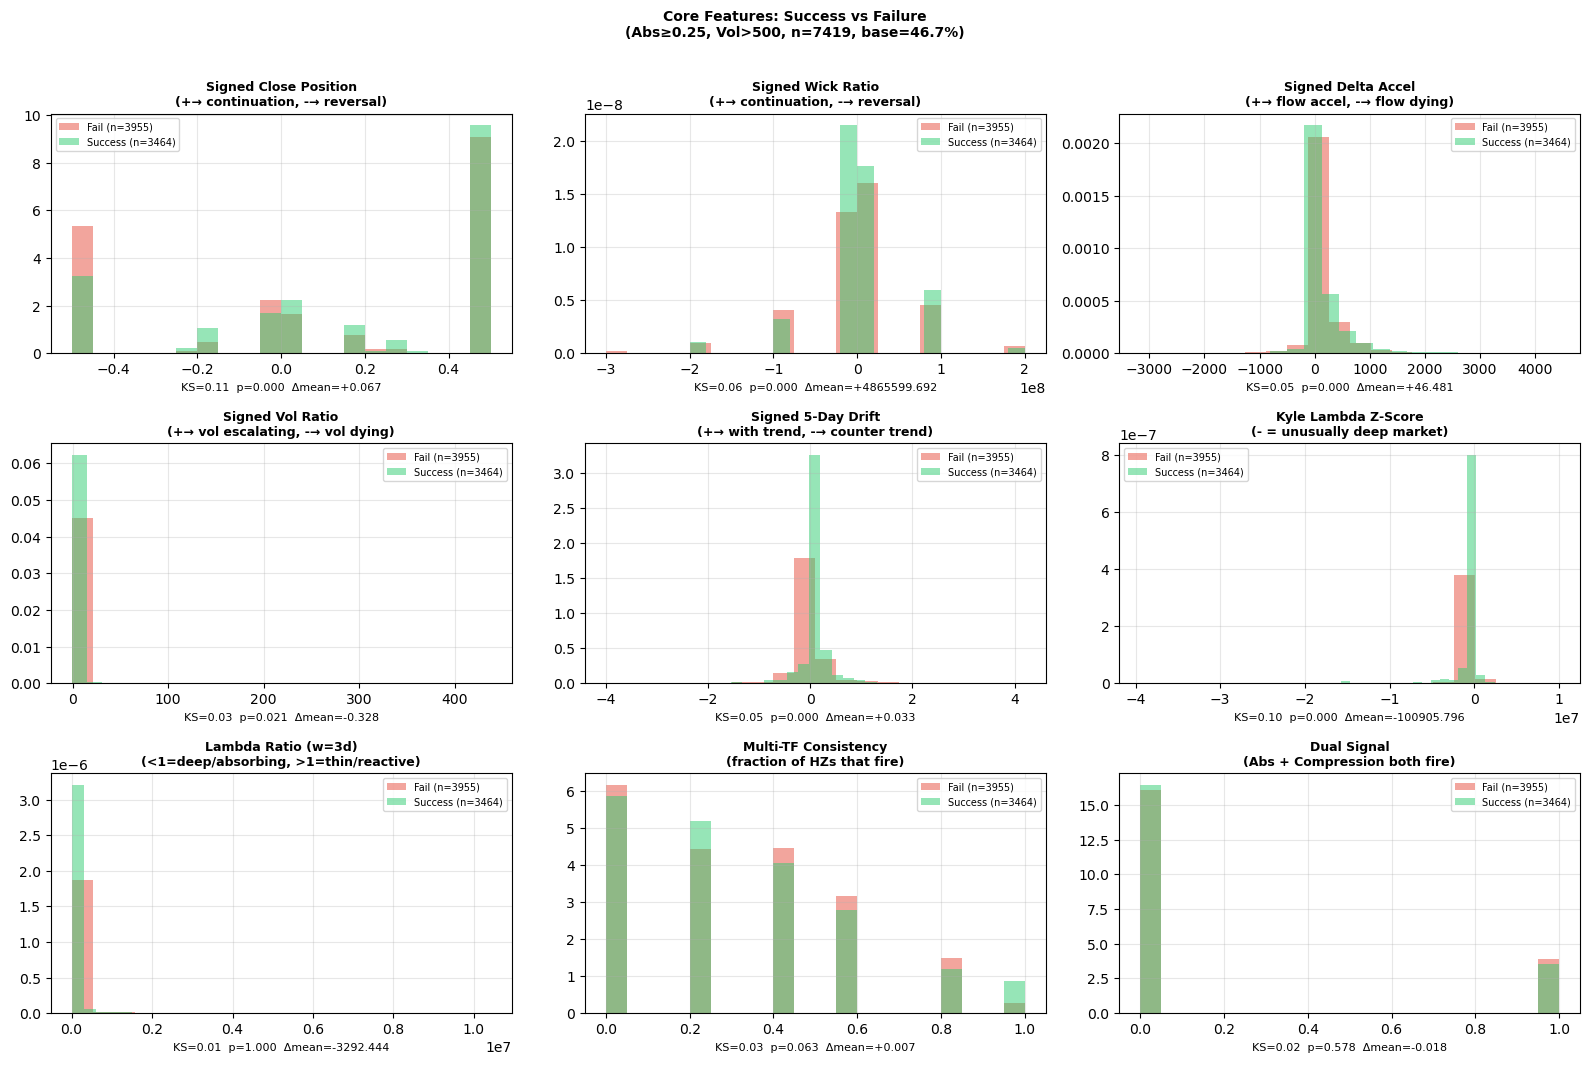


Core Feature Separation (KS test, sorted by KS stat):
           feature  ks_stat      ks_pval  mean_success     mean_fail     mean_diff
  signed_close_pos 0.105017 3.474016e-18  1.669650e-01  1.002276e-01  6.673741e-02
     lambda_zscore 0.100188 1.372731e-16 -3.747333e+05 -2.738275e+05 -1.009058e+05
 signed_wick_ratio 0.058005 7.581158e-06  3.550808e+06 -1.314791e+06  4.865600e+06
    signed_drift_5 0.050125 1.780453e-04  4.422633e-02  1.077118e-02  3.345515e-02
signed_delta_accel 0.048685 3.016991e-04  1.568965e+02  1.104151e+02  4.648137e+01
  signed_vol_ratio 0.034948 2.130124e-02  9.222924e-01  1.250019e+00 -3.277268e-01
    tf_consistency 0.030479 6.297608e-02  3.087182e-01  3.016941e-01  7.024187e-03
       dual_signal 0.018016 5.781474e-01  1.766744e-01  1.946903e-01 -1.801590e-02
      lambda_ratio 0.008127 9.996181e-01  4.781525e+04  5.110769e+04 -3.292444e+03

════════════════════════════════════════════════════════════
SECTION B — RV RATIO COMBINATIONS (all num/den window

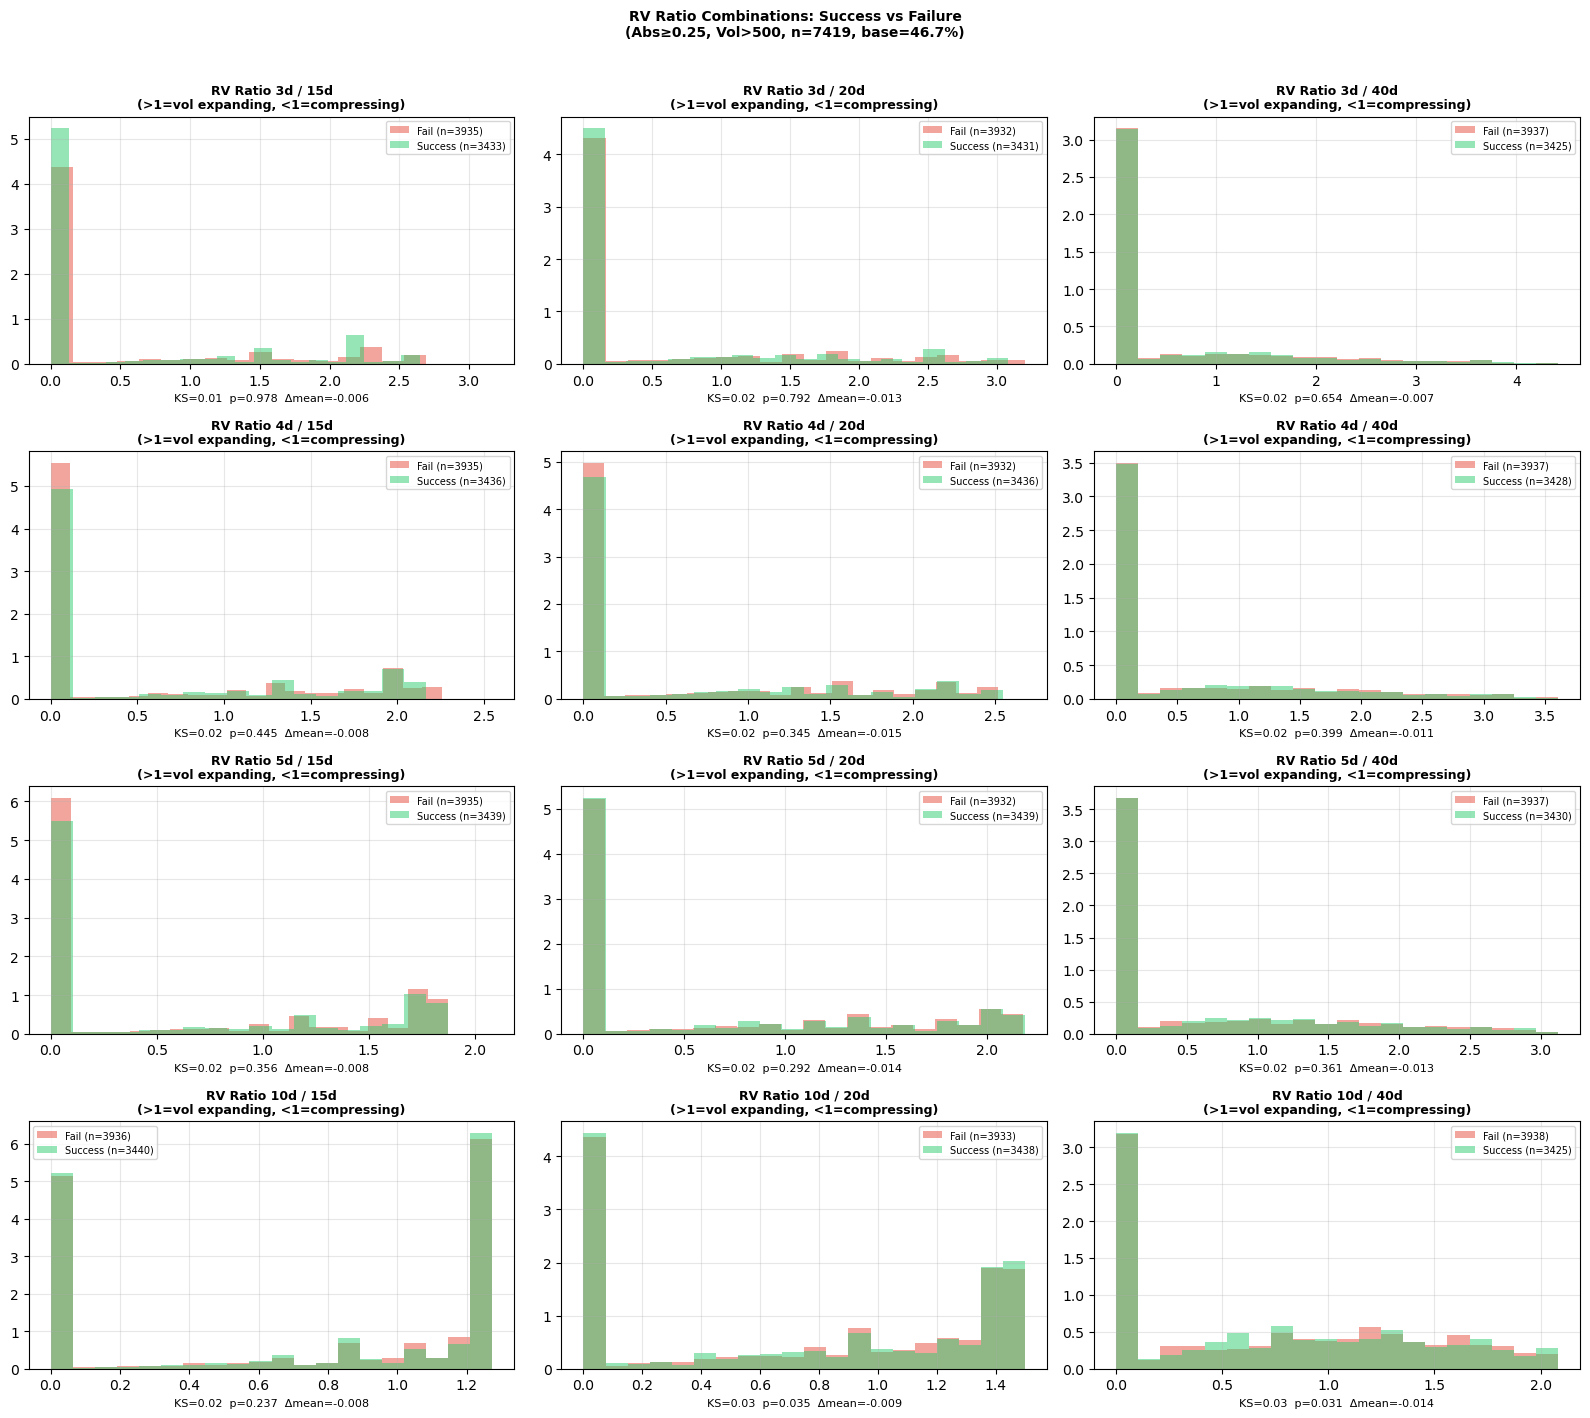


RV Ratio Separation (KS test, sorted by KS stat):
         feature  ks_stat  ks_pval  mean_success  mean_fail  mean_diff
rv_ratio_10d_40d 0.033640 0.030719      0.732572   0.746318  -0.013746
rv_ratio_10d_20d 0.033084 0.035013      0.745309   0.754012  -0.008703
rv_ratio_10d_15d 0.023980 0.236730      0.721538   0.729975  -0.008437
 rv_ratio_5d_20d 0.022768 0.291713      0.594079   0.607933  -0.013855
 rv_ratio_4d_20d 0.021736 0.345092      0.556345   0.571219  -0.014874
 rv_ratio_5d_15d 0.021536 0.355645      0.591516   0.599995  -0.008479
 rv_ratio_5d_40d 0.021451 0.361063      0.591184   0.603867  -0.012683
 rv_ratio_4d_40d 0.020802 0.398812      0.556284   0.567469  -0.011185
 rv_ratio_4d_15d 0.020040 0.445189      0.558990   0.567110  -0.008119
 rv_ratio_3d_40d 0.017032 0.654057      0.514935   0.522372  -0.007436
 rv_ratio_3d_20d 0.015063 0.792180      0.510997   0.523732  -0.012735
 rv_ratio_3d_15d 0.010981 0.977580      0.518548   0.524083  -0.005535

  → Best RV combo: rv_rat

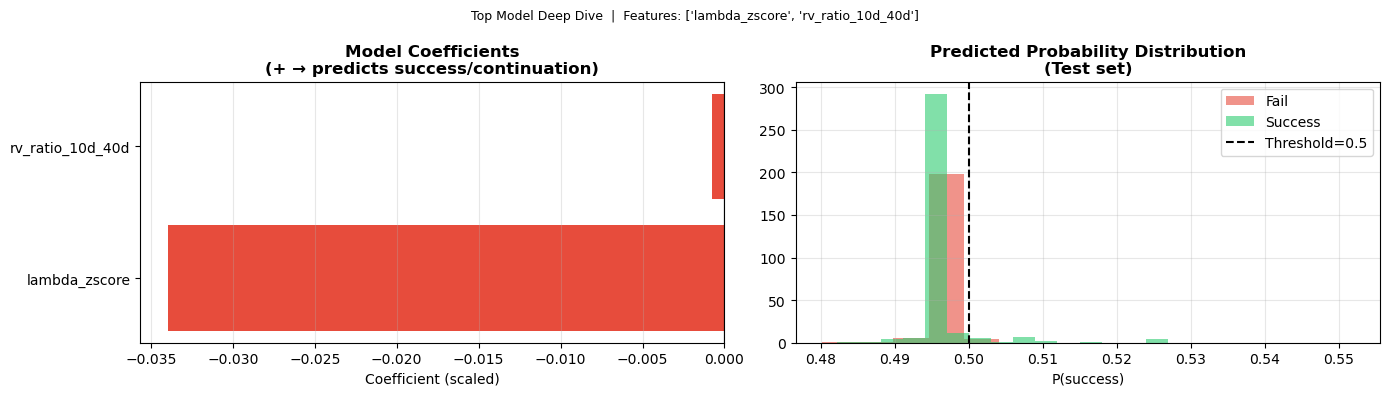


  Coefficients (sorted by |coef|):
         feature  coefficient
   lambda_zscore    -0.033955
rv_ratio_10d_40d    -0.000736


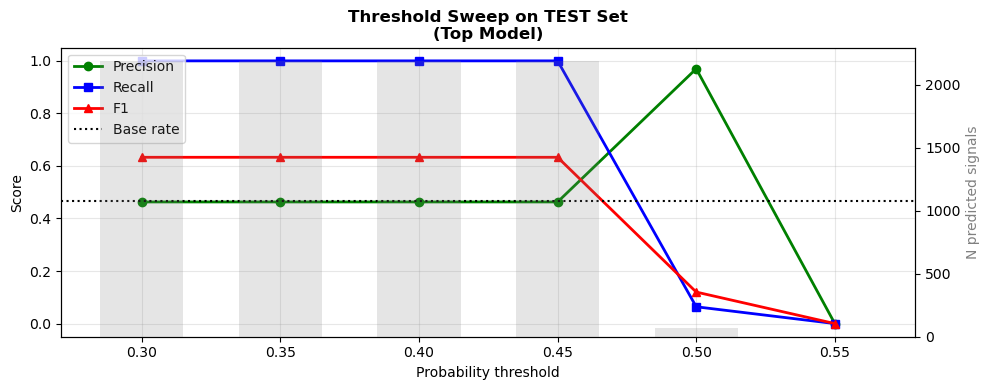


  Threshold Sweep Table (TEST):
 threshold  N_predicted  precision  recall    f1
      0.30         2184      0.463   1.000 0.633
      0.35         2184      0.463   1.000 0.633
      0.40         2184      0.463   1.000 0.633
      0.45         2184      0.463   1.000 0.633
      0.50           67      0.970   0.064 0.120
      0.55            1      0.000   0.000 0.000
════════════════════════════════════════════════════════════
BUY vs SELL ABSORPTION SPLIT
════════════════════════════════════════════════════════════

  BUY ABSORPTION  n=3335  success=1482 (44.4%)  fail=1853
           feature  mean_success     mean_fail          diff  ks_stat  p_value
 signed_wick_ratio -2.476383e+07 -3.507825e+07  1.031442e+07    0.097    0.000
  signed_vol_ratio  8.209000e-01  1.722200e+00 -9.013000e-01    0.091    0.000
  signed_close_pos  1.528000e-01  1.098000e-01  4.300000e-02    0.064    0.002
     lambda_zscore -2.259387e+05 -2.846979e+05  5.875912e+04    0.064    0.002
  rv_ratio_10d_40d 

In [9]:
# ═══════════════════════════════════════════════════════════════════════════════
# CELL 1 — SETUP & IMPORTS
# ═══════════════════════════════════════════════════════════════════════════════

import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, r"C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents")

import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_score, recall_score, f1_score
from itertools import combinations

from market_analysis.config import (
    PRODUCTS, FRONT_N, OHLC_START_DATE, OHLC_END_DATE, ABSORPTION, COMPRESSION,
    ABSORPTION_1H, HORIZON_BARS_1H, VOLUME_MIN_1H
)
from market_analysis.data.ohlc import (
    getData_OHLC_v2, fetch_ohlc_1h, get_ohlc_1h_for_horizon, _aggregate_trailing_1h
)
from market_analysis.utils.contracts import (
    MONTH_CODES, next_n_contract_months, get_front_instruments, fmt_contract
)
from market_analysis.signals.absorption.calculate import calculate_absorption
from market_analysis.signals.absorption.label_hourly import label_absorption_hourly
from market_analysis.signals.compression.calculate import calculate_compression

# ── Constants ──────────────────────────────────────────────────────────────────
PRODUCT_CODE      = "SM"
TICK_SIZE         = PRODUCTS[PRODUCT_CODE]["tick_size"]          # 0.1
ABS_THRESHOLD     = 0.25    # absorption_strength filter
COMP_THRESHOLD    = 0.30    # compression_score filter
VOLUME_MIN        = VOLUME_MIN_1H    # ignore bars with total volume below this
HORIZONS          = ["1h", "2h", "4h", "8h", "16h"]
TODAY             = datetime.date.today()

# Label params (from your best sweep row)
REQUIRED_MOVE_TICKS = ABSORPTION_1H["required_move_ticks"]
SL_LOOKBACK         = ABSORPTION_1H["sl_lookback"]
FORWARD_BARS        = ABSORPTION_1H["forward_bars"]

# ── OHLC fetch window per instrument ─────────────────────────────────────────
# Each spread's data starts 7 months before the front-leg's expiry month.
# e.g. SMZ26-SMF27  → front leg = Dec 2026 → start = 2026-05-01
MONTHS_BEFORE_EXPIRY = 7

# ── RV Ratio config ──────────────────────────────────────────────────────────
# All combinations of (numerator_window, denominator_window) will be computed
# as separate features rv_ratio_{N}d_{D}d and each will get its own plot.
# Convention: short_window / long_window  → >1 = vol expanding, <1 = compressing
RV_NUMERATOR_WINDOWS   = [3,4, 5, 10]      # short lookback options (days)
RV_DENOMINATOR_WINDOWS = [15, 20, 40]    # long  lookback options (days)

# ── Kyle Lambda z-score window ───────────────────────────────────────────────
# Rolling window (in bars) used to compute the mean and std of lambda_t
# for the z-score normalisation. Larger = more stable baseline, slower to adapt.
LAMBDA_ZSCORE_WINDOW: int = 20

# ── Kyle Lambda ratio window ───────────────────────────────────────────────
# lambda_ratio = lambda_t / mean(lambda_{t-LAMBDA_RATIO_WINDOW : t-1})
# Measures how current price-impact compares to recent average depth.
# < 1  → market currently harder to move than usual (deep, absorbing flow)
# > 1  → market thinner than usual (each unit of delta moves price more)
LAMBDA_RATIO_WINDOW: int = 3     # how many past bars to average for the denominator
# ─────────────────────────────────────────────────────────────────────────────

print("✅ Setup complete")
print(f"   Product       : {PRODUCT_CODE}  tick={TICK_SIZE}")
print(f"   Abs threshold : {ABS_THRESHOLD}   Comp threshold: {COMP_THRESHOLD}")
print(f"   Volume filter : >{VOLUME_MIN}    Forward bars: {FORWARD_BARS}")
print(f"   Today         : {TODAY}")
print(f"   Fetch window  : {MONTHS_BEFORE_EXPIRY} months before front-leg expiry")
print(f"   RV numerators : {RV_NUMERATOR_WINDOWS}")
print(f"   RV denominators: {RV_DENOMINATOR_WINDOWS}")
print(f"   Lambda zscore window : {LAMBDA_ZSCORE_WINDOW}d")
print(f"   Lambda ratio  window : {LAMBDA_RATIO_WINDOW}d")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 2 — INSTRUMENT SELECTION (front 4 + recently expired spreads)
# ═══════════════════════════════════════════════════════════════════════════════

def get_expired_spreads(product_code: str, n_expired: int = 3) -> list[str]:
    """
    Return the last `n_expired` calendar-consecutive spread pairs that expired
    before today. Uses the same traded_months list from config.
    """
    product  = PRODUCTS[product_code]
    traded   = sorted(product["traded_months"])
    prefix   = product["api_prefix"]

    # walk backwards from today to collect recent contract months
    y, m     = TODAY.year, TODAY.month
    collected = []
    while len(collected) < n_expired + 4:   # collect extra buffer
        m -= 1
        if m < 1:
            m = 12; y -= 1
        if m in traded:
            collected.append((y, m))

    collected.reverse()   # chronological order

    pairs = []
    for i in range(len(collected) - 1):
        front = fmt_contract(prefix, *collected[i])
        back  = fmt_contract(prefix, *collected[i + 1])
        pairs.append(f"{front}-{back}")

    # take the most recent n_expired pairs
    return pairs[-n_expired:]


def instr_fetch_start(instrument: str, months_before: int = MONTHS_BEFORE_EXPIRY) -> str:
    """
    Derive the OHLC fetch start date for a spread instrument.

    Logic: parse the front-leg contract → find its expiry month (year, month)
           → subtract `months_before` calendar months → return "YYYY-MM-01".

    Example:
        "SMZ26-SMF27"  → front leg SMZ26 → Dec 2026
                       → 7 months before Dec = May 2026
                       → start = "2026-05-01"
    """
    import re
    # Reverse MONTH_CODES so we can go from letter → month number
    CODE_TO_MONTH = {v: k for k, v in MONTH_CODES.items()}

    front_leg = instrument.split("-")[0]          # e.g. "SMZ26"
    m_obj     = re.match(r"^[A-Za-z]+([A-Z])(\d{2})$", front_leg)
    if not m_obj:
        # Fallback: use global OHLC_START_DATE if we can't parse
        return OHLC_START_DATE

    month_code = m_obj.group(1)                   # e.g. "Z"
    year_2dig  = int(m_obj.group(2))              # e.g. 26
    year       = 2000 + year_2dig                 # e.g. 2026
    month      = CODE_TO_MONTH.get(month_code, 1) # e.g. 12 (December)

    # subtract months_before months
    start_month = month - months_before
    start_year  = year
    while start_month < 1:
        start_month += 12
        start_year  -= 1

    return f"{start_year}-{start_month:02d}-01"


# Front 4 spreads starting from today
front_4 = get_front_instruments(PRODUCT_CODE, "spread",
                                reference_date=TODAY, front_n=4)

# ~3 recently expired spreads for extra data
expired_3 = get_expired_spreads(PRODUCT_CODE, n_expired=3)

ALL_INSTRUMENTS = expired_3 + front_4

print("═" * 60)
print("INSTRUMENTS SELECTED")
print("═" * 60)
print(f"  Expired spreads : {expired_3}")
print(f"  Front 4 spreads : {front_4}")
print(f"  Total           : {len(ALL_INSTRUMENTS)} instruments")
print()
print("  Derived fetch windows (7 months before front-leg expiry):")
for instr in ALL_INSTRUMENTS:
    print(f"    {instr:22s}  start={instr_fetch_start(instr)}")
print("═" * 60)


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 3 — FETCH, SCORE (absorption + compression) FOR ALL INSTRUMENTS
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("FETCHING & SCORING OHLC DATA")
print("═" * 60)

# Store per-instrument scored 1D DataFrames (before aggregation)
scored_1d = {}      # {instrument: df_with_absorption_1d}
scored_nd = {}      # {instrument: {horizon: df}}

for instr in ALL_INSTRUMENTS:
    print(f"\n  ▸ {instr}")

    # Per-instrument fetch window: 7 months before front-leg expiry
    instr_start = instr_fetch_start(instr)
    print(f"    fetch_start={instr_start}")

    # --- 1D fetch & absorption score ---
    df1d = fetch_ohlc_1h(instr, PRODUCT_CODE, getData_OHLC_v2,
                          start_date=instr_start, end_date=OHLC_END_DATE)
    if df1d is None or len(df1d) < 70:
        print(f"    [SKIP] not enough data (rows={len(df1d) if df1d is not None else 0})")
        continue

    df1d_abs  = calculate_absorption(df1d, window=120,
                                      tick_size=TICK_SIZE, strength_threshold=ABS_THRESHOLD)
    df1d_abs  = label_absorption_hourly(df1d_abs, tick=TICK_SIZE,
                                  required_move_ticks=REQUIRED_MOVE_TICKS,
                                  sl_lookback=SL_LOOKBACK,
                                  forward_bars=FORWARD_BARS)
    scored_1d[instr] = df1d_abs

    # --- compression on 1D ---
    df1d_comp, _ = calculate_compression(df1d.copy(),
                                          compression_threshold=COMP_THRESHOLD)

    # merge compression_score into absorption df by Date
    comp_merge = df1d_comp[["Date", "compression_score"]].copy()
    comp_merge["Date"] = pd.to_datetime(comp_merge["Date"]).dt.strftime("%Y-%m-%d")
    df1d_abs["Date"]   = pd.to_datetime(df1d_abs["Date"]).dt.strftime("%Y-%m-%d")
    df1d_abs = df1d_abs.merge(comp_merge.rename(columns={"compression_score": "comp_score_1d"}),
                               on="Date", how="left")
    scored_1d[instr] = df1d_abs

    # --- multi-horizon absorption scores (for consistency feature) ---
    scored_nd[instr] = {}
    for hz in HORIZONS:
        from market_analysis.data.ohlc import _aggregate_trailing_1h
        from market_analysis.config import HORIZON_BARS_1H
        n_bars = HORIZON_BARS_1H[hz]
        dfh    = df1d.copy() if n_bars == 1 else _aggregate_trailing_1h(df1d.copy(), n_bars)
        if dfh is None or len(dfh) < 65:
            continue
        dfh_sc = calculate_absorption(dfh, window=120,
                                       tick_size=TICK_SIZE, strength_threshold=ABS_THRESHOLD)
        scored_nd[instr][hz] = dfh_sc
    print(f"    rows={len(df1d_abs)}  "
          f"abs_events={(df1d_abs['absorption_strength'] > ABS_THRESHOLD).sum()}")

print("\n✅ Scoring complete")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 4 — FEATURE ENGINEERING
# (all past-only, no forward leakage, computed at bar t)
# ═══════════════════════════════════════════════════════════════════════════════

def build_resolution_features(df: pd.DataFrame,
                                scored_nd_for_instr: dict,
                                tick: float = 0.1,
                                epsilon: float = 1e-9) -> pd.DataFrame:
    """
    Add Stage-2 characterization features to a scored+labeled 1D DataFrame.
    All features use only [t-N : t] — strictly past-only.
    """
    d = df.copy().sort_values("Date").reset_index(drop=True)

    # ── 1. Intrabar: close position within bar ──────────────────────────────
    d["close_pos"] = (d["close"] - d["low"]) / (d["high"] - d["low"] + epsilon)
    # Signed for direction:
    #   BUY  absorption → reversal = price drops → close near LOW is BAD for buyers
    #     close_pos LOW (< 0.3) → sellers won intrabar → reversal hint → signed negative
    #   SELL absorption → reversal = price rises → close near HIGH is BAD for sellers
    # Convention: signed_close_pos > 0 → continuation, < 0 → reversal
    d["signed_close_pos"] = np.where(
        d["absorption_direction"] == "BUY",
        d["close_pos"] - 0.5,          # BUY: high → continuation (+), low → reversal (-)
        0.5 - d["close_pos"],          # SELL: low → continuation (+), high → reversal (-)
    )

    # ── 2. Intrabar: wick asymmetry ──────────────────────────────────────────
    d["upper_wick"] = d["high"] - d[["open", "close"]].max(axis=1)
    d["lower_wick"] = d[["open", "close"]].min(axis=1) - d["low"]
    d["wick_ratio"] = d["upper_wick"] / (d["lower_wick"] + epsilon)
    # BUY absorption: large upper wick → price pushed up but rejected → reversal
    # SELL absorption: large lower wick → price tested down but rejected → reversal
    # Sign: negative → reversal hint
    d["signed_wick_ratio"] = np.where(
        d["absorption_direction"] == "BUY",
        -(d["wick_ratio"] - 1.0),       # BUY: wick_ratio >> 1 → reversal → negative
        (d["wick_ratio"] - 1.0),        # SELL: wick_ratio << 1 → reversal → positive issue
    )
    # simpler: just keep raw wick_ratio and let model learn direction via dir dummy

    # ── 3. Delta ratio (how one-sided) ───────────────────────────────────────
    d["delta_ratio"] = d["buyvolume"] / (d["sellvolume"] + epsilon)

    # ── 4. Delta momentum: is aggressive flow accel or dying? ────────────────
    d["delta_accel"] = d["delta"] - d["delta"].shift(1).rolling(3, min_periods=1).mean()
    # Sign to success: BUY absorption — if delta_accel positive → buyers not exhausted → continuation
    # SELL absorption — if delta_accel negative (sell delta growing) → sellers not exhausted → continuation
    d["signed_delta_accel"] = np.where(
        d["absorption_direction"] == "BUY",
        d["delta_accel"],
        -d["delta_accel"],
    )

    # ── 5. Volume deceleration ───────────────────────────────────────────────
    vol_roll5 = d["volume"].shift(1).rolling(5, min_periods=2).mean()
    d["vol_ratio"] = d["volume"] / (vol_roll5 + epsilon)
    # vol_ratio < 1 → volume drying up → exhaustion → reversal (negative for our sign)
    # signed: positive → continuation hint
    d["signed_vol_ratio"] = d["vol_ratio"] - 1.0   # >0 = escalating, <0 = dying

    # ── 6. Price drift into absorption ───────────────────────────────────────
    d["drift_5"] = (d["close"] - d["close"].shift(5)) / (5 * tick + epsilon)
    # BUY absorption after falling prices (drift_5 < 0) → counter-trend buyers → reversal likely
    # SELL absorption after rising prices (drift_5 > 0) → counter-trend sellers → reversal likely
    # Sign: same direction as absorption = continuation, opposite = reversal
    d["signed_drift_5"] = np.where(
        d["absorption_direction"] == "BUY",
        d["drift_5"],          # rising drift + BUY absorption → continuation
        -d["drift_5"],         # falling drift + SELL absorption → continuation
    )

    # ── 7. Kyle Lambda: market depth anomaly ─────────────────────────────────
    price_change = d["close"].diff().abs()
    abs_delta    = d["delta"].abs()
    d["lambda_t"] = price_change / (abs_delta + epsilon)

    # lambda_ratio: current vs recent average depth
    #   = lambda_t / mean(lambda[t-LAMBDA_RATIO_WINDOW : t-1])
    #   < 1 → market deeper than usual → flow absorbed without moving price much
    #   > 1 → market thinner than usual → each delta unit moves price more
    _lam_ratio_mp          = max(2, LAMBDA_RATIO_WINDOW // 2)
    d["lambda_ratio_avg"]  = (
        d["lambda_t"].shift(1)
        .rolling(LAMBDA_RATIO_WINDOW, min_periods=_lam_ratio_mp)
        .mean()
    )
    d["lambda_ratio"] = d["lambda_t"] / (d["lambda_ratio_avg"] + epsilon)

    # lambda_zscore: z-normalised over a longer baseline window
    _lam_mp    = max(10, LAMBDA_ZSCORE_WINDOW // 3)
    lam_mean   = d["lambda_t"].shift(1).rolling(LAMBDA_ZSCORE_WINDOW, min_periods=_lam_mp).mean()
    lam_std    = d["lambda_t"].shift(1).rolling(LAMBDA_ZSCORE_WINDOW, min_periods=_lam_mp).std()
    d["lambda_zscore"] = (d["lambda_t"] - lam_mean) / (lam_std + epsilon)
    # very negative lambda_zscore = unusually deep market = strong absorption event
    # (window controlled by LAMBDA_ZSCORE_WINDOW; ratio window by LAMBDA_RATIO_WINDOW)

    # ── 8. Realized volatility ratios (all configured combinations) ──────────
    # Config lists RV_NUMERATOR_WINDOWS and RV_DENOMINATOR_WINDOWS (defined in Cell 1).
    # For each (num_w, den_w) pair where num_w < den_w we compute:
    #   rv_ratio_{num_w}d_{den_w}d = rv(num_w) / rv(den_w)
    # >1 = vol expanding (short > long)  |  <1 = vol compressing
    log_ret = np.log(d["close"].replace(0, np.nan) / d["close"].shift(1).replace(0, np.nan))

    # Pre-compute each unique window std once
    all_windows = sorted(set(RV_NUMERATOR_WINDOWS + RV_DENOMINATOR_WINDOWS))
    rv_cache = {}
    for w in all_windows:
        mp = max(2, w // 2)
        rv_cache[w] = log_ret.rolling(w, min_periods=mp).std()

    for num_w in RV_NUMERATOR_WINDOWS:
        for den_w in RV_DENOMINATOR_WINDOWS:
            if num_w >= den_w:
                continue   # skip: numerator must be shorter than denominator
            col = f"rv_ratio_{num_w}d_{den_w}d"
            d[col] = rv_cache[num_w] / (rv_cache[den_w] + epsilon)

    # Keep the original rv_ratio name pointing at the first valid combo
    # so downstream code that references "rv_ratio" still works
    _first_num = next((n for n in RV_NUMERATOR_WINDOWS for den in RV_DENOMINATOR_WINDOWS if n < den), None)
    _first_den = next((den for n in RV_NUMERATOR_WINDOWS for den in RV_DENOMINATOR_WINDOWS if n < den), None)
    if _first_num is not None:
        d["rv_ratio"] = d[f"rv_ratio_{_first_num}d_{_first_den}d"]
    # rv_ratio > 1 → short-window vol > long-window vol → expanding (high-vol regime)
    # rv_ratio < 1 → short-window vol < long-window vol → compressing (quiet)

    # ── 9. Multi-timeframe consistency ───────────────────────────────────────
    # For each bar date, check if absorption_strength > ABS_THRESHOLD on other horizons
    d["Date_str"] = pd.to_datetime(d["Date"]).dt.strftime("%Y-%m-%d")
    tf_scores = {hz: {} for hz in HORIZONS}
    for hz, dfh in scored_nd_for_instr.items():
        if dfh is None or "absorption_strength" not in dfh.columns:
            continue
        dfh_copy = dfh.copy()
        dfh_copy["Date_str"] = pd.to_datetime(dfh_copy["Date"]).dt.strftime("%Y-%m-%d")
        for _, row in dfh_copy.iterrows():
            tf_scores[hz][row["Date_str"]] = row["absorption_strength"]

    consistency_vals = []
    for _, row in d.iterrows():
        date_key = row["Date_str"]
        fires = [
            1 if tf_scores[hz].get(date_key, 0) > ABS_THRESHOLD else 0
            for hz in HORIZONS
        ]
        consistency_vals.append(np.mean(fires))
    d["tf_consistency"] = consistency_vals

    # ── 10. Dual signal: both absorption AND compression fire ─────────────────
    d["dual_signal"] = (
        (d["absorption_strength"] > ABS_THRESHOLD) &
        (d.get("comp_score_1d", pd.Series(0, index=d.index)).fillna(0) > COMP_THRESHOLD)
    ).astype(float)

    # ── 11. Direction dummy (BUY=1, SELL=0) ──────────────────────────────────
    d["is_buy_absorption"] = (d["absorption_direction"] == "BUY").astype(float)

    return d


# Apply feature engineering to all instruments
print("═" * 60)
print("FEATURE ENGINEERING")
print("═" * 60)

featured = {}
for instr, df in scored_1d.items():
    nd_for_instr = scored_nd.get(instr, {})
    featured[instr] = build_resolution_features(df, nd_for_instr, tick=TICK_SIZE)
    print(f"  ✓ {instr}  columns={len(featured[instr].columns)}")

print("✅ Feature engineering complete")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 5 — POOL ABSORPTION EVENTS & SUMMARY
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("POOLING ABSORPTION EVENTS (volume > 3000, strength > 0.25)")
print("═" * 60)

FEATURE_COLS = [
    "signed_close_pos",
    "signed_wick_ratio",
    "signed_delta_accel",
    "signed_vol_ratio",
    "signed_drift_5",
    "lambda_zscore",
    "rv_ratio",
    "tf_consistency",
    "dual_signal",
    "is_buy_absorption",
    # raw (unsigned) versions also included for exploration
    "close_pos",
    "wick_ratio",
    "vol_ratio",
    "delta_ratio",
    "lambda_ratio",
]

all_events = []
for instr, df in featured.items():
    mask = (
        (df["absorption_strength"] > ABS_THRESHOLD) &
        (df["volume"] > VOLUME_MIN) &
        (df["sl_success"].notna())
    )
    subset = df[mask].copy()
    subset["instrument"] = instr
    all_events.append(subset)

if not all_events:
    print("❌ No events found — check thresholds or data fetch")
else:
    pool = pd.concat(all_events, ignore_index=True)
    pool = pool.sort_values("Date").reset_index(drop=True)

    n_total   = len(pool)
    n_success = int(pool["sl_success"].sum())
    n_fail    = int((pool["sl_success"] == 0).sum())
    base_rate = n_success / n_total if n_total > 0 else 0

    print(f"\n  Total absorption events : {n_total}")
    print(f"  Success (reversal)      : {n_success}  ({100*base_rate:.1f}%)")
    print(f"  Failure                 : {n_fail}")
    print(f"\n  Per instrument:")
    for instr in pool["instrument"].unique():
        sub = pool[pool["instrument"] == instr]
        s = int(sub["sl_success"].sum())
        print(f"    {instr:20s}  n={len(sub):3d}  success={s}")
    print()

    # ensure features are numeric
    for fc in FEATURE_COLS:
        if fc in pool.columns:
            pool[fc] = pd.to_numeric(pool[fc], errors="coerce")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 6 — DISTRIBUTION PLOTS: Feature separation (success vs fail)
# ═══════════════════════════════════════════════════════════════════════════════

# ── Helper: plot a set of features and return separation stats ────────────────
def _plot_feature_grid(pool_df, feature_list, title_prefix=""):
    """
    Plots histograms for each (feat, label) tuple in feature_list.
    Returns a list of separation stat dicts.
    """
    suc = pool_df[pool_df["sl_success"] == 1]
    fai = pool_df[pool_df["sl_success"] == 0]
    stats_out = []

    n_cols = 3
    n_rows = (len(feature_list) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3.5))
    axes = axes.flatten()

    for ax, (feat, label) in zip(axes, feature_list):
        if feat not in pool_df.columns:
            ax.set_visible(False); continue
        s_vals = suc[feat].dropna()
        f_vals = fai[feat].dropna()
        if len(s_vals) == 0 or len(f_vals) == 0:
            ax.set_visible(False); continue

        ax.hist(f_vals, bins=20, alpha=0.5, color="#e74c3c", density=True,
                label=f"Fail (n={len(f_vals)})")
        ax.hist(s_vals, bins=20, alpha=0.5, color="#2ecc71", density=True,
                label=f"Success (n={len(s_vals)})")
        ks_stat, ks_pval = stats.ks_2samp(s_vals, f_vals)
        mean_diff = s_vals.mean() - f_vals.mean()
        ax.set_title(label, fontsize=9, fontweight="bold")
        ax.set_xlabel(f"KS={ks_stat:.2f}  p={ks_pval:.3f}  Δmean={mean_diff:+.3f}", fontsize=8)
        ax.legend(fontsize=7); ax.grid(alpha=0.3)
        stats_out.append({"feature": feat, "ks_stat": ks_stat, "ks_pval": ks_pval,
                           "mean_success": s_vals.mean(), "mean_fail": f_vals.mean(),
                           "mean_diff": mean_diff})

    for ax in axes[len(feature_list):]:
        ax.set_visible(False)
    plt.suptitle(f"{title_prefix}\n"
                 f"(Abs≥{ABS_THRESHOLD}, Vol>{VOLUME_MIN}, "
                 f"n={n_total}, base={base_rate:.1%})",
                 fontsize=10, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()
    return stats_out


# ── Section A: core signed features ──────────────────────────────────────────
CORE_PLOT_FEATURES = [
    ("signed_close_pos",   "Signed Close Position\n(+→ continuation, -→ reversal)"),
    ("signed_wick_ratio",  "Signed Wick Ratio\n(+→ continuation, -→ reversal)"),
    ("signed_delta_accel", "Signed Delta Accel\n(+→ flow accel, -→ flow dying)"),
    ("signed_vol_ratio",   "Signed Vol Ratio\n(+→ vol escalating, -→ vol dying)"),
    ("signed_drift_5",     "Signed 5-Day Drift\n(+→ with trend, -→ counter trend)"),
    ("lambda_zscore",      "Kyle Lambda Z-Score\n(- = unusually deep market)"),
    ("lambda_ratio",       f"Lambda Ratio (w={LAMBDA_RATIO_WINDOW}d)\n(<1=deep/absorbing, >1=thin/reactive)"),
    ("tf_consistency",     "Multi-TF Consistency\n(fraction of HZs that fire)"),
    ("dual_signal",        "Dual Signal\n(Abs + Compression both fire)"),
]

print("═" * 60)
print("SECTION A — CORE FEATURE SEPARATION (success vs failure)")
print("═" * 60)
sep_stats = _plot_feature_grid(pool, CORE_PLOT_FEATURES,
                                title_prefix="Core Features: Success vs Failure")

sep_df = pd.DataFrame(sep_stats).sort_values("ks_stat", ascending=False)
print("\nCore Feature Separation (KS test, sorted by KS stat):")
print(sep_df[["feature", "ks_stat", "ks_pval", "mean_success", "mean_fail", "mean_diff"]].to_string(index=False))


# ── Section B: RV Ratio — all window combinations ────────────────────────────
print()
print("═" * 60)
print("SECTION B — RV RATIO COMBINATIONS (all num/den window pairs)")
print(f"  Numerator  windows: {RV_NUMERATOR_WINDOWS}")
print(f"  Denominator windows: {RV_DENOMINATOR_WINDOWS}")
print("═" * 60)

RV_PLOT_FEATURES = []
for num_w in RV_NUMERATOR_WINDOWS:
    for den_w in RV_DENOMINATOR_WINDOWS:
        if num_w >= den_w:
            continue
        col   = f"rv_ratio_{num_w}d_{den_w}d"
        label = (f"RV Ratio {num_w}d / {den_w}d\n"
                 f"(>1=vol expanding, <1=compressing)")
        RV_PLOT_FEATURES.append((col, label))

if RV_PLOT_FEATURES:
    rv_sep_stats = _plot_feature_grid(pool, RV_PLOT_FEATURES,
                                       title_prefix="RV Ratio Combinations: Success vs Failure")
    rv_sep_df = pd.DataFrame(rv_sep_stats).sort_values("ks_stat", ascending=False)
    print("\nRV Ratio Separation (KS test, sorted by KS stat):")
    print(rv_sep_df[["feature", "ks_stat", "ks_pval",
                     "mean_success", "mean_fail", "mean_diff"]].to_string(index=False))
    print(f"\n  → Best RV combo: {rv_sep_df.iloc[0]['feature']}  "
          f"KS={rv_sep_df.iloc[0]['ks_stat']:.3f}")
    # Store best for use in model sweep
    BEST_RV_FEATURE = rv_sep_df.iloc[0]["feature"]
else:
    print("  No valid RV combos (all numerators >= denominators). Check config.")
    BEST_RV_FEATURE = "rv_ratio"

# Combined separation table (all features)
all_sep_df = pd.concat([sep_df, rv_sep_df if RV_PLOT_FEATURES else pd.DataFrame()],
                        ignore_index=True).sort_values("ks_stat", ascending=False)
print("\n── ALL FEATURES combined (sorted by KS stat) ──")
print(all_sep_df[["feature", "ks_stat", "ks_pval", "mean_diff"]].to_string(index=False))
success_events = pool[pool["sl_success"] == 1]
fail_events    = pool[pool["sl_success"] == 0]


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 7 — WALK-FORWARD TRAIN / TEST SPLIT
# ═══════════════════════════════════════════════════════════════════════════════

pool_sorted = pool.sort_values("Date").reset_index(drop=True)
split_idx   = int(len(pool_sorted) * 0.70)
train_df    = pool_sorted.iloc[:split_idx].copy()
test_df     = pool_sorted.iloc[split_idx:].copy()

print("═" * 60)
print("WALK-FORWARD SPLIT")
print("═" * 60)
print(f"  Train: {len(train_df)} events | {train_df['Date'].min()} → {train_df['Date'].max()}")
print(f"  Test : {len(test_df)} events  | {test_df['Date'].min()} → {test_df['Date'].max()}")
print(f"  Train base rate: {train_df['sl_success'].mean():.1%}")
print(f"  Test  base rate: {test_df['sl_success'].mean():.1%}")


def get_Xy(df: pd.DataFrame, feats: list[str]):
    """Extract X, y matrices from a pool DataFrame, dropping NaN rows."""
    sub  = df[feats + ["sl_success"]].dropna()
    X    = sub[feats].values.astype(float)
    y    = sub["sl_success"].values.astype(int)
    return X, y, sub.index


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 8 — FEATURE COMBO SWEEP (SGD Logistic Regression)
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("FEATURE COMBINATION SWEEP (SGD Logistic Regression)")
print("═" * 60)

# Signed feature candidates (theoretically motivated).
# rv_ratio is replaced by the best-KS combo found in Cell 6 Section B.
SIGNED_FEATS = [
    "signed_close_pos",
    "signed_delta_accel",
    "signed_vol_ratio",
    "signed_drift_5",
    "lambda_zscore",
    "lambda_ratio",        # depth ratio vs recent avg (LAMBDA_RATIO_WINDOW)
    BEST_RV_FEATURE,       # best RV window combo by KS separation
    "tf_consistency",
    "signed_wick_ratio",
]

# Filter to only features that exist and have enough variance
available_feats = [
    f for f in SIGNED_FEATS
    if f in train_df.columns and train_df[f].dropna().std() > 1e-6
]
print(f"  Available features: {available_feats}\n")

# Combos of size 2–6 (theoretically motivated pairs first, then expand)
# Plus one full-feature model
combo_sizes = [2, 3, 4, 5]
combos      = []
for size in combo_sizes:
    combos.extend(list(combinations(available_feats, size)))
# Add full model
combos.append(tuple(available_feats))

print(f"  Total combos to evaluate: {len(combos)}")

def make_sgd_pipeline():
    clf = SGDClassifier(
        loss="log_loss",
        penalty="l2",
        alpha=0.01,
        max_iter=1000,
        tol=1e-4,
        random_state=42,
        class_weight="balanced",
    )
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])


results = []
for combo in combos:
    feats = list(combo)
    X_tr, y_tr, _ = get_Xy(train_df, feats)
    X_te, y_te, _ = get_Xy(test_df,  feats)

    if len(X_tr) < 20 or len(X_te) < 5:
        continue
    if len(np.unique(y_tr)) < 2 or len(np.unique(y_te)) < 2:
        continue

    pipe = make_sgd_pipeline()
    try:
        pipe.fit(X_tr, y_tr)
    except Exception:
        continue

    y_pred_prob = pipe.predict_proba(X_te)[:, 1]
    # Use 0.5 as default threshold
    y_pred = (y_pred_prob >= 0.5).astype(int)

    prec   = precision_score(y_te, y_pred, zero_division=0)
    rec    = recall_score(y_te,    y_pred, zero_division=0)
    f1     = f1_score(y_te,        y_pred, zero_division=0)
    # Lift over base rate
    base   = y_te.mean() if y_te.mean() > 0 else 1e-9
    lift   = prec / base

    results.append({
        "features"  : feats,
        "n_feats"   : len(feats),
        "precision" : round(prec, 4),
        "recall"    : round(rec,  4),
        "f1"        : round(f1,   4),
        "lift"      : round(lift, 4),
        "n_train"   : len(X_tr),
        "n_test"    : len(X_te),
    })

results_df = pd.DataFrame(results).sort_values("precision", ascending=False).reset_index(drop=True)

print("\n  Top 15 combos by Precision on TEST set:")
print("─" * 80)
for i, row in results_df.head(15).iterrows():
    print(f"  [{i+1:2d}] n_feats={row['n_feats']}  "
          f"P={row['precision']:.3f}  R={row['recall']:.3f}  "
          f"F1={row['f1']:.3f}  Lift={row['lift']:.2f}")
    print(f"       features: {row['features']}")

print(f"\n  Base rate on test: {test_df['sl_success'].mean():.1%}")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 9 — TOP MODEL DEEP DIVE (threshold sweep + coefficients)
# ═══════════════════════════════════════════════════════════════════════════════

# Pick top combo by precision
best_row   = results_df.iloc[0]
best_feats = best_row["features"]
print("═" * 60)
print(f"TOP MODEL ANALYSIS")
print("═" * 60)
print(f"  Features: {best_feats}")
print(f"  Train n={best_row['n_train']}  Test n={best_row['n_test']}")
print(f"  Precision={best_row['precision']:.3f}  Recall={best_row['recall']:.3f}  "
      f"F1={best_row['f1']:.3f}  Lift={best_row['lift']:.2f}")

X_tr, y_tr, _ = get_Xy(train_df, best_feats)
X_te, y_te, _ = get_Xy(test_df,  best_feats)

best_pipe = make_sgd_pipeline()
best_pipe.fit(X_tr, y_tr)
y_prob_te = best_pipe.predict_proba(X_te)[:, 1]

# ── Coefficients ──────────────────────────────────────────────────────────────
coefs = best_pipe.named_steps["clf"].coef_[0]
coef_df = pd.DataFrame({
    "feature": best_feats,
    "coefficient": coefs,
    "abs_coef": np.abs(coefs)
}).sort_values("abs_coef", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Coefficient bar chart
ax = axes[0]
colors = ["#2ecc71" if c > 0 else "#e74c3c" for c in coef_df["coefficient"]]
ax.barh(coef_df["feature"], coef_df["coefficient"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Model Coefficients\n(+ → predicts success/continuation)", fontweight="bold")
ax.set_xlabel("Coefficient (scaled)")
ax.grid(alpha=0.3, axis="x")

# Probability distribution by outcome
ax = axes[1]
ax.hist(y_prob_te[y_te == 0], bins=15, alpha=0.6, color="#e74c3c", density=True, label="Fail")
ax.hist(y_prob_te[y_te == 1], bins=15, alpha=0.6, color="#2ecc71", density=True, label="Success")
ax.axvline(0.5, color="black", linestyle="--", label="Threshold=0.5")
ax.set_title("Predicted Probability Distribution\n(Test set)", fontweight="bold")
ax.set_xlabel("P(success)")
ax.legend()
ax.grid(alpha=0.3)

plt.suptitle(f"Top Model Deep Dive  |  Features: {best_feats}", fontsize=9)
plt.tight_layout()
plt.show()

print("\n  Coefficients (sorted by |coef|):")
print(coef_df[["feature", "coefficient"]].to_string(index=False))


# ── Threshold sweep on test set ───────────────────────────────────────────────
thresholds = np.arange(0.30, 0.85, 0.05)
sweep_rows = []
for t in thresholds:
    y_pred_t = (y_prob_te >= t).astype(int)
    n_pred   = y_pred_t.sum()
    if n_pred == 0:
        continue
    p = precision_score(y_te, y_pred_t, zero_division=0)
    r = recall_score(y_te,    y_pred_t, zero_division=0)
    f = f1_score(y_te,        y_pred_t, zero_division=0)
    sweep_rows.append({"threshold": round(t, 2), "N_predicted": n_pred,
                        "precision": round(p, 3), "recall": round(r, 3), "f1": round(f, 3)})

sweep_res = pd.DataFrame(sweep_rows)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(sweep_res["threshold"], sweep_res["precision"], "g-o", label="Precision", linewidth=2)
ax.plot(sweep_res["threshold"], sweep_res["recall"],    "b-s", label="Recall",    linewidth=2)
ax.plot(sweep_res["threshold"], sweep_res["f1"],        "r-^", label="F1",        linewidth=2)
ax2 = ax.twinx()
ax2.bar(sweep_res["threshold"], sweep_res["N_predicted"], alpha=0.2, color="gray",
        width=0.03, label="N predicted")
ax2.set_ylabel("N predicted signals", color="gray")
ax.axhline(test_df["sl_success"].mean(), color="black", linestyle=":", label=f"Base rate")
ax.set_xlabel("Probability threshold")
ax.set_ylabel("Score")
ax.set_title("Threshold Sweep on TEST Set\n(Top Model)", fontweight="bold")
ax.legend(loc="upper left"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\n  Threshold Sweep Table (TEST):")
print(sweep_res.to_string(index=False))


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 10 — BUY vs SELL ABSORPTION SPLIT ANALYSIS
# ═══════════════════════════════════════════════════════════════════════════════

print("═" * 60)
print("BUY vs SELL ABSORPTION SPLIT")
print("═" * 60)

for direction in ["BUY", "SELL"]:
    sub = pool[pool["absorption_direction"] == direction].copy()
    n   = len(sub)
    if n < 15:
        print(f"  {direction}: too few events ({n}), skipping")
        continue

    s_sub = sub[sub["sl_success"] == 1]
    f_sub = sub[sub["sl_success"] == 0]
    print(f"\n  {direction} ABSORPTION  n={n}  "
          f"success={len(s_sub)} ({100*len(s_sub)/n:.1f}%)  "
          f"fail={len(f_sub)}")

    feat_means = []
    for feat in available_feats:
        if feat not in sub.columns:
            continue
        sv = s_sub[feat].dropna()
        fv = f_sub[feat].dropna()
        if len(sv) < 3 or len(fv) < 3:
            continue
        ks, pv = stats.ks_2samp(sv, fv)
        feat_means.append({
            "feature": feat,
            "mean_success": round(sv.mean(), 4),
            "mean_fail"   : round(fv.mean(), 4),
            "diff"        : round(sv.mean() - fv.mean(), 4),
            "ks_stat"     : round(ks, 3),
            "p_value"     : round(pv, 3),
        })

    feat_means_df = pd.DataFrame(feat_means).sort_values("ks_stat", ascending=False)
    print(feat_means_df.to_string(index=False))

    # Train direction-specific model if enough data
    sub_sorted = sub.sort_values("Date").reset_index(drop=True)
    sp = int(len(sub_sorted) * 0.70)
    tr_d = sub_sorted.iloc[:sp]
    te_d = sub_sorted.iloc[sp:]
    if len(tr_d) < 15 or len(te_d) < 5:
        print(f"  [{direction}] Not enough data for direction model")
        continue

    X_tr_d, y_tr_d, _ = get_Xy(tr_d, best_feats)
    X_te_d, y_te_d, _ = get_Xy(te_d, best_feats)
    if len(np.unique(y_tr_d)) < 2:
        print(f"  [{direction}] Only one class in train, skipping")
        continue

    pipe_d = make_sgd_pipeline()
    pipe_d.fit(X_tr_d, y_tr_d)
    if len(np.unique(y_te_d)) < 2:
        print(f"  [{direction}] Only one class in test set, skipping metrics")
        continue
    y_pred_d = pipe_d.predict(X_te_d)
    print(f"\n  [{direction}] Direction-specific model (same features):")
    print(f"    Precision={precision_score(y_te_d, y_pred_d, zero_division=0):.3f}  "
          f"Recall={recall_score(y_te_d, y_pred_d, zero_division=0):.3f}  "
          f"F1={f1_score(y_te_d, y_pred_d, zero_division=0):.3f}")
    coefs_d = pipe_d.named_steps["clf"].coef_[0]
    print(f"    Coefficients: " +
          "  ".join(f"{f}={c:+.3f}" for f, c in zip(best_feats, coefs_d)))


print("\n" + "═" * 60)
print("ANALYSIS COMPLETE")
print("═" * 60)
